# **Modelos candidatos — protocolo en el panel de 8 municipios y referencias**

Notebook del Entregable 3. **Esta primera etapa cubre sólo el protocolo y las referencias**:
reglas fijadas antes de ejecutar (sección 1), carga sin el bloque final (2), motor de
backtesting (3), métricas (4), control cruzado del motor contra `linea_base.ipynb` (5) y las
referencias en el panel (6). Los modelos candidatos (GLM Poisson, GLM binomial negativa,
XGBoost) se agregan en una etapa posterior, **sin modificar** lo que está acá.

**El bloque final (2025-02-06 → 2025-12-31) no se lee en ningún código de este notebook.** Toda
lectura del panel descarta las filas posteriores a 2025-02-05 en el mismo paso, y un `assert`
verifica que no quedó ninguna.

**Fase 2 (19/10/2026).** Las secciones 7 a 9 agregan la experimentación con los candidatos (pasos A, B y C)
a continuación de la sección 6, sin modificar las secciones 0 a 6, la adenda ni las precisiones de la
fase 2. «Estado y artefactos» pasó a ser la sección 10.

**Fase 3 (19/10/2026).** La decisión D42 (bloque debajo de las precisiones del paso C) fija la configuración final, apartándose de la regla. La sección 10 la escribe en `solucion_seleccionada.json`; las secciones 11 y 12 quedan para la explicabilidad y el análisis de errores. «Estado y artefactos» pasó a ser la sección 13. El bloque final sigue sin leerse.

## 0. Entorno

Igual que `linea_base.ipynb`: lee `requirements.txt` en vivo y **detiene la ejecución** si la
versión de Python o la de alguna dependencia directa difiere.

In [1]:
# Detiene la ejecución si el entorno no coincide con requirements.txt. No es un aviso.
import platform
import re
from pathlib import Path
import importlib.metadata as importlib_metadata

_cwd = Path.cwd()
if (_cwd / "requirements.txt").exists():
    _RAIZ_CHK = _cwd
elif (_cwd.parent / "requirements.txt").exists():
    _RAIZ_CHK = _cwd.parent
else:
    raise FileNotFoundError("No se encuentra requirements.txt para verificar el entorno.")

_req_texto = (_RAIZ_CHK / "requirements.txt").read_text(encoding="utf-8")

_m_py = re.search(r"#\s*Python\s+(\d+\.\d+\.\d+)", _req_texto)
if not _m_py:
    raise RuntimeError("No se encontró la versión de Python esperada en requirements.txt.")
PYTHON_ESPERADO = _m_py.group(1)

DEPENDENCIAS_ESPERADAS = {}
for _linea in _req_texto.splitlines():
    _sin_comentario = _linea.split("#", 1)[0].strip()
    _m = re.match(r"^([A-Za-z0-9_.\-]+)==([A-Za-z0-9_.\-]+)$", _sin_comentario)
    if _m:
        DEPENDENCIAS_ESPERADAS[_m.group(1).lower()] = _m.group(2)

python_actual = platform.python_version()
_errores = []
if python_actual != PYTHON_ESPERADO:
    _errores.append(f"Python: se esperaba {PYTHON_ESPERADO}, hay {python_actual}")

for _paquete, _version_esperada in DEPENDENCIAS_ESPERADAS.items():
    try:
        _version_actual = importlib_metadata.version(_paquete)
    except importlib_metadata.PackageNotFoundError:
        _errores.append(f"{_paquete}: no está instalado (se esperaba {_version_esperada})")
        continue
    if _version_actual != _version_esperada:
        _errores.append(f"{_paquete}: se esperaba {_version_esperada}, hay {_version_actual}")

if _errores:
    _mensaje = ("El entorno no coincide con requirements.txt (instalar con "
                "`pip install -r requirements.txt -c requirements-lock.txt`):\n  - "
                + "\n  - ".join(_errores))
    raise RuntimeError(_mensaje)

print(f"Entorno OK — Python {python_actual}, {len(DEPENDENCIAS_ESPERADAS)} dependencias "
      f"directas verificadas contra requirements.txt (ninguna diferencia).")

Entorno OK — Python 3.13.2, 18 dependencias directas verificadas contra requirements.txt (ninguna diferencia).


## 1. Reglas fijadas antes de ejecutar

> **Esta celda no se modifica después de ver resultados.** Cualquier cambio posterior se
> registra aparte, con fecha y motivo, en el documento acompañante.

**Lista cerrada de modelos**

- *Referencias.* (i) Media constante global. (ii) **L0**: promedio de lo observado 7, 14, 21 y 28
  días antes; su ventana se revisa con 2, 4 y 8 semanas. (iii) **L1 en el panel**: nivel del
  municipio × factor de calendario agregado de 8 niveles (lunes a domingo, más feriado); es el
  modelo M2 de `diagnostico_municipios.ipynb`.
- *Candidatos* (se agregan en una etapa posterior). GLM Poisson, GLM binomial negativa y XGBoost
  con `objective="count:poisson"`.

**Árbol de decisión: retirado antes de ejecutar.** En el Entregable 2 no extrapoló la
tendencia, y XGBoost con pérdida Poisson es la extensión de la misma familia.

**Conjuntos de variables, anidados**

| Conjunto | Contenido |
| --- | --- |
| (0) | sin exógenas: municipio + nivel reciente + rezagos 7/14/21/28 |
| (a) | municipio + calendario de 8 niveles |
| (b) | (a) + término propio de calendario para el municipio A |
| (c) | (b) + nivel reciente (28/56/91 días) |

**El conjunto (d) (= (c) + lluvia) se eliminó de la lista antes de ejecutar** (decisión del
equipo, 2026-10-14). Motivo: la lluvia del día a predecir no está disponible con un horizonte de
7 días (sólo existiría un pronóstico), y el diagnóstico no le encontró aporte fuera de muestra
(`diagnostico_municipios.ipynb`, §7.5). La lluvia no figura en `src/variables.py`.

**Grilla de XGBoost.** `max_depth` ∈ {2, 3, 4} × `n_estimators` ∈ {100, 300} ×
`learning_rate` ∈ {0.05, 0.1}. El resto de los parámetros, fijos y declarados.

**Ventanas de entrenamiento.** Expansiva; deslizante de 364, 546 y 728 días.

**Orden de la experimentación**

- **A.** Conjuntos con GLM Poisson y XGBoost por defecto, en ventana expansiva.
- **B.** Grilla de XGBoost y ajuste de la binomial negativa sobre el conjunto elegido.
- **C.** Ventanas para los dos mejores candidatos.

**Regla de selección**

1. Desvianza de Poisson media en validación.
2. Empate: candidatos a menos de 1 error estándar del mejor, con el error estándar calculado
   sobre los 47 cortes.
3. Entre empatados, el más simple y explicable (GLM antes que XGBoost; menos variables antes
   que más).
4. Desempate por estabilidad (peor municipio, dispersión entre semanas) y luego por calibración
   (total predicho / observado).

**Binomial negativa.** Se reporta la dispersión de Pearson del GLM Poisson y el α estimado. Su
papel declarado son los intervalos de predicción y la inferencia sobre coeficientes, no mejorar
la desvianza.

**Sesgo declarado.** La búsqueda de hiperparámetros y la selección usan los mismos 47 cortes; el
desempeño del ganador en validación es optimista.

**Protocolo común (de `linea_base.ipynb`, sin cambios).** Horizonte de 7 días, 47 cortes de
origen móvil, reentrenamiento en cada corte; desvianza de Poisson media como métrica principal.

## Adenda a la sección 1 — Precisiones fijadas el 19/10/2026, después de la fase 1 y antes de ejecutar cualquier candidato

> **La celda de la sección 1 no se modificó.** Este bloque registra, con fecha y motivo, cinco
> precisiones del plan (cada una con su decisión) que la sección 1 dejó abiertas o sin escribir.
> Se fijaron con las referencias de la fase 1 ya evaluadas y **antes de ejecutar cualquier
> candidato** (GLM Poisson, GLM binomial negativa, XGBoost). La lista cerrada de modelos, los
> conjuntos (0), (a), (b) y (c), la grilla de XGBoost, las ventanas, el orden A → B → C y la regla
> de selección de la sección 1 siguen como estaban.

1. **L0 que pasa a la comparación: 8 semanas** (D17). La sección 1 dejó la ventana de L0 «a revisar con
   2, 4 y 8 semanas» sin una regla para elegir. La elección se hizo **después de fijar la lista y
   mirando los 47 cortes de validación**: desvianza de Poisson media de **1,3626** con 8 semanas,
   contra 1,5210 con 4 semanas (la del Entregable 2) y 2,4384 con 2 semanas
   (`experiments/modelos_candidatos/tablas/05_referencias_globales.csv`). Es una elección
   **informada por la validación**, no una regla previa a los resultados. La media constante marca
   1,3967 (misma tabla) y su error estándar sobre los 47 cortes es 0,0447
   (`tablas/08_referencias_error_estandar_y_estabilidad.csv`): L0 de 8 semanas queda por debajo
   de ella por 0,0341, es decir, **a menos de 1 error estándar**. El bloque final no intervino.
2. **Nivel reciente del conjunto (0)** (D18). N ∈ {28, 56, 91} días, elegido en el paso A por la
   desvianza de Poisson media en validación, **por separado en cada familia** (GLM Poisson y
   XGBoost), igual que en el conjunto (c).
3. **XGBoost en el paso A** (D19). `max_depth=3`, `n_estimators=300`, `learning_rate=0.05`; el resto de
   los parámetros, fijos y declarados en el código; semilla fija.
4. **Elección del conjunto por familia** (GLM y XGBoost) (D20). Entre (a), (b) y (c), con la regla de
   1 error estándar de la sección 1 y el orden de simplicidad a < b < c. El conjunto (0) se
   reporta para el objetivo 1.2.2 y solo reemplaza al elegido si lo mejora por más de 1 error
   estándar.
5. **Binomial negativa: NB2** (D27 y D28). Varianza μ + αμ², con α **estimado por máxima verosimilitud en
   cada corte**: `statsmodels.discrete.discrete_model.NegativeBinomial` con
   `loglike_method="nb2"` (parámetro y valor verificados en la firma y el docstring de la clase de
   statsmodels 0.14.6, la versión instalada). La familia `NegativeBinomial` del GLM
   (`statsmodels.genmod.families`) deja α fijo (1,0 si no se le pasa), por eso no se usa como
   estimador principal. **Plan B (D28):** si NB2 por máxima verosimilitud no converge
   en un corte, se reporta y en ese corte se usa el GLM NB con α estimado por momentos en el
   mismo corte: regresión auxiliar sin intercepto de ((y − μ)² − y)/μ sobre μ, con μ del GLM
   Poisson ajustado en el entrenamiento de ese corte (Cameron y Trivedi, 1990).
6. **Criterio de convergencia de NB2** (D29) — *agregado el 19/10/2026 en el fix de la ronda 2, antes de ejecutar candidatos (D29).*
   Sexta precisión, posterior a las cinco anteriores (que no se modifican). NB2 se ajusta con
   `method="newton"` y `maxiter=100`. Un corte cuenta como **no convergido** si
   `mle_retvals["converged"]` es `False`, si se emite un `ConvergenceWarning` o si α no es finito o
   no es positivo; en ese caso se aplica el plan B (D28) del ítem 5.

## Precisiones de la fase 2, fijadas el 19/10/2026 antes de ejecutar candidatos

> **Ni la sección 1 ni la adenda se modificaron.** Este bloque agrega cinco precisiones (D31 a D34 y la
> del ítem 5) que la fase 2 necesita y que ninguna de las dos cubre. Se fijaron **antes de ejecutar cualquier candidato**
> (GLM Poisson, binomial negativa, XGBoost), con las referencias de la fase 1 como único resultado visto.

1. **Matriz de indicadoras** (D31). La misma matriz para GLM y XGBoost: **8 columnas de municipio, sin
   constante** (cada municipio con su propio intercepto); **calendario con 7 columnas, lunes como
   referencia**; **término de A con 7 columnas `a_x_*`, sin `a_x_lunes`** (con las 8 columnas el término
   sería colineal con la indicadora de A, como advierte `src/variables.py`). En el GLM la
   parametrización no cambia las predicciones; en XGBoost sí, y así A queda en una sola columna.
2. **Error estándar del ítem 4 de la adenda** (D32): el de (0). El conjunto (0) reemplaza al elegido
   entre (a), (b) y (c) **solo si desv(elegido) − desv(0) > EE(0)**, con EE(0) el error estándar de (0)
   sobre los 47 cortes. Es coherente con el paso 2 de la regla de selección, donde el error estándar es
   el del mejor.
3. **Registro de experimentos** (D33). `experiments/modelos_candidatos/registro_experimentos.csv` se
   **reescribe en cada ejecución** del notebook, con todas las configuraciones evaluadas en esa
   ejecución (incluidos los resultados negativos) y su fecha y hora. El notebook es determinista; el
   historial queda en git, con un commit en cada parada (después de los pasos A, B y C).
4. **Forma de las variables** (D34). En (0) y en (c), el nivel reciente entra como
   **log(nivel_reciente_N)** —con coeficiente 1 la predicción escala con el nivel reciente— y los
   **rezagos 7/14/21/28 como conteos crudos** (hay ceros: log(y) no está definido). En XGBoost la
   transformación logarítmica no cambia los árboles. Una verificación detiene la ejecución si algún nivel
   reciente vale 0 (el logaritmo no estaría definido).
5. **Parámetros de XGBoost fuera de D19**: valores por defecto de xgboost 3.4.1 (`tree_method="hist"`,
   `subsample=1`, `colsample_bytree=1`, `min_child_weight=1`, `reg_lambda=1`), más `random_state=SEMILLA`
   y `n_jobs=1` para que los resultados sean deterministas.

## Precisiones del paso B, fijadas el 19/10/2026 antes de ejecutarlo

> **Nada de lo anterior se modificó** (sección 1, adenda, precisiones de la fase 2). Este bloque precisa cómo se aplican los pasos
> 3 y 4 de la regla de selección dentro de una familia con las mismas variables, caso que la sección 1 no resuelve. Se fijó con
> los resultados del paso A ya vistos y **antes de ejecutar el paso B**. **Vale también para el paso C.**

1. **Simplicidad entre GLM Poisson y NB2** (D36). Con la misma matriz, **GLM Poisson es más simple que NB2** (un parámetro menos:
   NB2 con α → 0 es Poisson). Si empatan a menos de 1 error estándar, gana Poisson. Cómo se construyen los intervalos de
   predicción se decide en la fase 3.
2. **Simplicidad entre combinaciones de XGBoost** (D37). Entre combinaciones empatadas, más simple = **menor `max_depth`** y, a
   igual profundidad, **menor `n_estimators`**. `learning_rate` no cuenta como complejidad: si dos combinaciones solo difieren
   en él, decide el paso 4.
3. **Paso 4, lexicográfico con tolerancia de 1 EE** (D38). Entre las empatadas que siguen sin separarse: pasan las que tienen una
   desvianza del peor municipio **a menos de 1 EE de la mejor en ese criterio**. El EE es el del peor municipio de esa mejor
   configuración, calculado sobre los 47 cortes (como en `tablas/12`). Entre ellas gana la de **menor desvío entre cortes**; si
   empatan, la de **menor |total pred./obs. − 1|**.

## Precisiones del paso C, fijadas el 19/10/2026 con los resultados de los pasos A y B ya vistos

> **Nada de lo anterior se modificó** (sección 1, adenda, precisiones de la fase 2 y del paso B). Este bloque se fijó **después de ver
> los resultados de los pasos A y B** (secciones 7 y 8) y **antes de ejecutar el paso C**.

1. **XGBoost que pasa al paso C** (D39). Se mantiene la XGBoost elegida por la regla en el paso B (`max_depth=2`, `n_estimators=100`,
   `learning_rate=0.1`), **aunque su desvianza media sea peor que la de L1** (sección 8.1). La mejor combinación de la grilla en
   desvianza (`max_depth=4`, `n_estimators=300`, `learning_rate=0.05`) se reporta como referencia y **no se ejecuta en el paso C**.
2. **La ventana no cuenta como complejidad** (D40). En el paso 3 de la regla solo se ordena por familia (GLM antes que XGBoost). Entre
   ventanas de la misma familia que sigan empatadas, decide el paso 4 (D38).

## Decisión del equipo sobre la configuración final, 19/10/2026 (D42)

> **Nada de lo anterior se modificó** (sección 1, adenda, precisiones de la fase 2 y de los pasos B y C). Este bloque se fijó
> **después de ver los resultados del paso C** (sección 9) y **antes de leer el bloque final**, que sigue sin cargarse.

1. **Lo que eligió la regla.** Aplicada como está (sección 1, D38 y D40), la regla eligió **GLM Poisson (a) con ventana expansiva**.
   Las 8 configuraciones del paso C empataron a menos de 1 EE (umbral 1,2569), la simplicidad dejó las 4 ventanas del GLM, las 4
   pasaron la tolerancia del peor municipio y decidió el desvío entre cortes: expansiva **0,246353** contra 0,246801 de la de 728 d (la
   segunda), **una diferencia de 0,00045**, y contra 0,249505 de la de 364 d (`tablas/29_paso_c_eleccion.csv`).
2. **Decisión del equipo (D42): se aparta de la regla.** La configuración final es **GLM Poisson (a) con ventana deslizante de 364
   días**. Motivos:
   - **Desvianza media:** 1,2205 contra 1,2302 de la expansiva (`tablas/26_paso_c_globales.csv`).
   - **Cortes ganados:** tiene menor desvianza que la expansiva en **30 de 47 cortes** (`tablas/28_paso_c_por_corte.csv`).
   - **Calibración** (total predicho / observado): **0,9717** contra 0,9341; en el municipio A, **0,9330** contra 0,8695
     (`tablas/26_paso_c_globales.csv`).
   - El criterio que decidió la regla separó a las dos por un margen unas 80 veces menor que el EE de la desvianza (≈ 0,036,
     `tablas/26`). Las dos diferencias de desvianza tampoco superan 1 EE: **la elección es del equipo, no de la regla**.
3. **Sensibilidad.** GLM Poisson (a) con ventana **expansiva** (la configuración de la regla) queda como **configuración de
   sensibilidad**: se evalúa en la fase 4 y **no puede reemplazar a la final**, cualquiera sea su resultado en el bloque final.
4. **Contraste.** La mejor XGBoost del paso C, **XGBoost (a) d=2 n=100 lr=0,1 con ventana deslizante de 364 días** (1,2280,
   `tablas/26`), se evalúa en la fase 4 como contraste. Sensibilidad y contraste se evalúan junto con las referencias, pero **no
   compiten** con la configuración final.
5. Lo fijado se escribe en `experiments/modelos_candidatos/solucion_seleccionada.json` (sección 10).

## Precisiones de la fase 3, fijadas el 19/10/2026 antes de calcular 3b y 3c (D43 a D45)

> **Nada de lo anterior se modificó** (sección 1, adenda, precisiones de las fases 2 y del paso C, D42). Son **elecciones de análisis**
> para la explicabilidad y el análisis de errores, tomadas con la configuración final ya fijada (D42) y **antes de calcular** las secciones
> 11 y 12. **No afectan la selección**: la configuración final no cambia, cualquiera sea el resultado.

1. **Robustez, exclusión de un municipio por vez** (D43). En cada corte, con la ventana de 364 días, el GLM Poisson (a) se ajusta con los
   otros 7 municipios. Para el excluido *m*: η = β̄ + γ(día), con β̄ = promedio de los 7 efectos fijos estimados y γ el calendario estimado
   con los 7; la predicción es exp(η) × c_m, con c_m = media observada de *m* en los 364 días previos al origen ÷ media de exp(β̄ + γ) en esos
   mismos días. El calendario sale de los otros 7 y el nivel, de la historia propia de *m* antes del origen.
2. **Intervalos de predicción** (D44, la decisión que D36 dejó para la fase 3). La media es la de la solución (GLM Poisson (a), 364 d) y la
   dispersión es el α de NB2 (a) estimado en el mismo corte con la misma ventana, con el criterio de convergencia (D29) y el plan B (D28) de
   la adenda. Intervalo central de colas iguales: cuantiles 0,10 y 0,90 (80 %) y 0,025 y 0,975 (95 %) de la binomial negativa con media μ y
   varianza μ + αμ². Se reporta también la cobertura de intervalos **Poisson** con la misma μ.
3. **Coeficientes del GLM** (D45). Ajuste con los últimos 364 días del desarrollo. Municipios: exp(β_m) = siniestros esperados un lunes,
   con IC95, y la razón respecto del municipio A, con IC95 del contraste β_m − β_A. Calendario: razón respecto del lunes, con IC95.

## Importación de librerías y configuración

In [2]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import statsmodels
import xgboost
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error, mean_squared_error

# Mismo aviso y mismo motivo que en pytest.ini: lo emite pandas 2.3.3 con numpy 2.5.2 en cada pd.Timedelta
# (también en las llamadas de src/variables.py); no indica un error del proyecto. Se filtra solo este aviso.
warnings.filterwarnings("ignore", message="The .generic. unit for NumPy timedelta", category=DeprecationWarning)

RAIZ = _RAIZ_CHK
sys.path.insert(0, str(RAIZ))
from src import datos, variables as var      # única implementación de las variables y de la carga del panel

SEMILLA = 20260910      # la de linea_base.ipynb y diagnostico_municipios.ipynb
np.random.seed(SEMILLA)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DIR_EXPERIMENTO = RAIZ / "experiments" / "modelos_candidatos"
DIR_TABLAS = DIR_EXPERIMENTO / "tablas"
DIR_FIGURAS = DIR_EXPERIMENTO / "figuras"
DIR_TABLAS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)


def guardar_tabla(df, nombre):
    "Escribe un CSV (UTF-8) en experiments/modelos_candidatos/tablas y devuelve el DataFrame."
    ruta = DIR_TABLAS / nombre
    df.to_csv(ruta, index=False, encoding="utf-8")
    print("  guardado:", ruta.relative_to(RAIZ), f"({len(df)} filas)")
    return df


def guardar_figura(fig, nombre):
    ruta = DIR_FIGURAS / nombre
    fig.savefig(ruta, bbox_inches="tight")
    print("  guardado:", ruta.relative_to(RAIZ))


entorno = pd.DataFrame({
    "componente": ["python", "pandas", "numpy", "scipy", "matplotlib", "scikit-learn", "statsmodels", "xgboost"],
    "version": [python_actual, pd.__version__, np.__version__, __import__("scipy").__version__,
                matplotlib.__version__, sklearn.__version__, statsmodels.__version__, xgboost.__version__],
})
guardar_tabla(entorno, "00_entorno.csv")

  guardado: experiments\modelos_candidatos\tablas\00_entorno.csv (8 filas)


,componente,version
0,python,3.13.2
1,pandas,2.3.3
2,numpy,2.5.2
3,scipy,1.18.1
4,matplotlib,3.11.1
5,scikit-learn,1.9.0
6,statsmodels,0.14.6
7,xgboost,3.4.1


## 2. Carga del panel, sin el bloque final

`data/processed/panel_diario_montevideo.csv`, leído por `src.datos.cargar_panel_desarrollo()`: lee
por tramos y **recorta cada tramo a `fecha <= 2025-02-05` antes de acumularlo**: ninguna
fila del test se conserva ni se acumula; cada tramo se lee y se filtra antes de acumularse. El límite sale del calendario (80 % de los 1.645 días del período
2021-07-01 → 2025-12-31 = 1.316 días), no de los datos.

Particiones del desarrollo (las de `linea_base.ipynb`): **987 días de entrenamiento inicial** y
**329 de validación**, en los 8 municipios. Los cortes de validación arrancan en el día 988.

In [3]:
panel = datos.cargar_panel_desarrollo()

# Verificaciones que detienen la ejecución si algo falla (no son avisos).
ULTIMO = datos.ULTIMO_DIA_DESARROLLO
FECHAS = pd.DatetimeIndex(sorted(panel["fecha"].unique()))
INICIAL = int(round(0.75 * datos.N_DESARROLLO))            # 987 días de entrenamiento inicial
N_VALIDACION = datos.N_DESARROLLO - INICIAL                # 329 días de validación
HORIZONTE, PASO = var.HORIZONTE, 7
ORIGENES = [FECHAS[i] for i in range(INICIAL, len(FECHAS), PASO)]

verif = [
    ("límite del desarrollo = 2025-02-05 (sale del calendario)", str(ULTIMO.date()) == "2025-02-05"),
    ("ninguna fila posterior a 2025-02-05", not (panel["fecha"] > pd.Timestamp("2025-02-05")).any()),
    ("el panel llega al último día de desarrollo", panel["fecha"].max() == ULTIMO),
    ("8 municipios", panel["zona_id"].nunique() == 8),
    ("10.528 filas (1.316 días × 8)", len(panel) == 1316 * 8),
    ("sin pares (fecha, municipio) repetidos", not panel.duplicated(["fecha", "zona_id"]).any()),
    ("calendario diario sin huecos", FECHAS.equals(pd.date_range(datos.FECHA_INICIO, ULTIMO, freq="D"))),
    ("objetivo sin nulos, entero y no negativo", bool(panel["n_siniestros"].notna().all() and (panel["n_siniestros"] >= 0).all())),
    ("987 días de entrenamiento inicial y 329 de validación", (INICIAL, N_VALIDACION) == (987, 329)),
    ("47 cortes de 7 días", len(ORIGENES) == 47),
    ("el último corte termina en el último día de desarrollo", ORIGENES[-1] + pd.Timedelta(days=HORIZONTE - 1) == ULTIMO),
]
tabla_verif = pd.DataFrame(verif, columns=["verificación", "ok"])
print(tabla_verif.to_string(index=False))
assert tabla_verif["ok"].all(), "Alguna verificación de integridad falló."
guardar_tabla(tabla_verif, "01_verificacion_integridad.csv")

particiones = pd.DataFrame({
    "bloque": ["entrenamiento inicial", "validación (47 cortes de 7 días)", "bloque final (test)"],
    "desde": [str(FECHAS[0].date()), str(FECHAS[INICIAL].date()), str(datos.PRIMER_DIA_TEST.date())],
    "hasta": [str(FECHAS[INICIAL - 1].date()), str(FECHAS[-1].date()), "2025-12-31"],
    "dias": [INICIAL, N_VALIDACION, "no cargado"],
})
guardar_tabla(particiones, "02_particiones.csv")
particiones

                                            verificación   ok
límite del desarrollo = 2025-02-05 (sale del calendario) True
                     ninguna fila posterior a 2025-02-05 True
              el panel llega al último día de desarrollo True
                                            8 municipios True
                           10.528 filas (1.316 días × 8) True
                  sin pares (fecha, municipio) repetidos True
                            calendario diario sin huecos True
                objetivo sin nulos, entero y no negativo True
   987 días de entrenamiento inicial y 329 de validación True
                                     47 cortes de 7 días True
  el último corte termina en el último día de desarrollo True
  guardado: experiments\modelos_candidatos\tablas\01_verificacion_integridad.csv (11 filas)
  guardado: experiments\modelos_candidatos\tablas\02_particiones.csv (3 filas)


,bloque,desde,hasta,dias
0,entrenamiento inicial,2021-07-01,2024-03-13,987
1,validación (47 cortes de 7 días),2024-03-14,2025-02-05,329
2,bloque final (test),2025-02-06,2025-12-31,no cargado


## 3. Motor de backtesting

- **47 cortes** de horizonte 7, **origen móvil**, **reentrenamiento en cada corte**. El origen es el
  primer día a predecir; lo que se conoce es todo lo anterior (`fecha < origen`).
- **Parámetro de ventana.** `ventana=None` es la expansiva (todo lo anterior al origen);
  `ventana=N` es la deslizante de los últimos N días. En esta etapa sólo se usa la expansiva.
- **El modelo no puede mirar el futuro ni por descuido.** A cada modelo se le entrega una *vista*:
  el panel hasta el último día del horizonte, con el **objetivo de los días ≥ origen reemplazado
  por NaN** (el calendario `tipo_dia` sí se conserva, se conoce de antemano). El objetivo real se
  usa sólo para evaluar, después de predecir.
- **Todo lo que aprende de los datos se estima con la ventana de entrenamiento del corte**, usando
  `src/variables.py` (rezagos, nivel del municipio, calendario).
- Se **guardan las predicciones** por corte, día y municipio: la regla del error estándar las necesita.

Un modelo es una función `modelo(vista, origen, ventana) -> DataFrame[fecha, zona_id, pred]`.

In [4]:
def backtest(panel, modelo, ventana=None, origenes=ORIGENES, horizonte=HORIZONTE):
    "Predicciones de `modelo` en cada corte. Devuelve: corte, origen, fecha, zona_id, n_siniestros, pred."
    salida = []
    for corte, origen in enumerate(origenes, start=1):
        fin = origen + pd.Timedelta(days=horizonte)
        vista = panel[panel["fecha"] < fin].copy()
        vista.loc[vista["fecha"] >= origen, "n_siniestros"] = np.nan      # el futuro no se entrega
        p = modelo(vista, origen, ventana)
        real = panel[(panel["fecha"] >= origen) & (panel["fecha"] < fin)][["fecha", "zona_id", "n_siniestros"]]
        m = real.merge(p, on=["fecha", "zona_id"], how="left", validate="one_to_one")
        assert len(p) == len(real) and m["pred"].notna().all(), f"predicciones faltantes en el corte {corte}"
        m.insert(0, "origen", origen)
        m.insert(0, "corte", corte)
        salida.append(m)
    return pd.concat(salida, ignore_index=True)


def ventana_de_entrenamiento(vista, origen, ventana):
    "Filas con objetivo conocido de la ventana: [origen - ventana, origen); toda la historia si ventana=None."
    obs = var.observado(vista, origen)
    if ventana is not None:
        obs = obs[obs["fecha"] >= origen - pd.Timedelta(days=ventana)]
    return obs


def filas_del_horizonte(vista, origen):
    return vista.loc[vista["fecha"] >= origen, ["fecha", "zona_id", "tipo_dia"]].reset_index(drop=True)


# --- Comprobación estructural del motor con un "modelo sonda" (no predice nada útil) ---
sondas = []


def modelo_sonda(vista, origen, ventana):
    ent = ventana_de_entrenamiento(vista, origen, ventana)
    hor = filas_del_horizonte(vista, origen)
    sondas.append({
        "origen": origen, "ventana": ventana,
        "y_futuro_oculto": bool(vista.loc[vista["fecha"] >= origen, "n_siniestros"].isna().all()),
        "vista_termina_en_el_horizonte": vista["fecha"].max() == origen + pd.Timedelta(days=HORIZONTE - 1),
        "entrenamiento_sin_futuro": bool(ent["fecha"].max() < origen),
        "inicio_entrenamiento": ent["fecha"].min(),
        "dias_de_entrenamiento": ent["fecha"].nunique(),
    })
    return hor.assign(pred=1.0)[["fecha", "zona_id", "pred"]]


for _v in (None, 364):
    backtest(panel, modelo_sonda, ventana=_v)
sonda = pd.DataFrame(sondas)
chequeos_motor = pd.DataFrame([
    ("el objetivo de los días ≥ origen no llega al modelo", bool(sonda["y_futuro_oculto"].all())),
    ("la vista termina en el último día del horizonte", bool(sonda["vista_termina_en_el_horizonte"].all())),
    ("el entrenamiento nunca incluye el origen ni después", bool(sonda["entrenamiento_sin_futuro"].all())),
    ("ventana expansiva: crece desde el primer día (987 días en el primer corte)",
     bool((sonda.loc[sonda["ventana"].isna(), "inicio_entrenamiento"] == FECHAS[0]).all())
     and int(sonda.loc[sonda["ventana"].isna(), "dias_de_entrenamiento"].iloc[0]) == INICIAL),
    ("ventana deslizante de 364 días: exactamente 364 días en cada corte",
     bool((sonda.loc[sonda["ventana"] == 364, "dias_de_entrenamiento"] == 364).all())),
], columns=["comprobación del motor", "ok"])
print(chequeos_motor.to_string(index=False))
assert chequeos_motor["ok"].all(), "El motor de backtesting no cumple su contrato."
guardar_tabla(chequeos_motor, "03_comprobacion_motor.csv")

                                                    comprobación del motor   ok
                       el objetivo de los días ≥ origen no llega al modelo True
                           la vista termina en el último día del horizonte True
                       el entrenamiento nunca incluye el origen ni después True
ventana expansiva: crece desde el primer día (987 días en el primer corte) True
        ventana deslizante de 364 días: exactamente 364 días en cada corte True
  guardado: experiments\modelos_candidatos\tablas\03_comprobacion_motor.csv (5 filas)


,comprobación del motor,ok
0,el objetivo de los días ≥ origen no llega al m...,True
1,la vista termina en el último día del horizonte,True
2,el entrenamiento nunca incluye el origen ni de...,True
3,ventana expansiva: crece desde el primer día (...,True
4,ventana deslizante de 364 días: exactamente 36...,True


## 4. Métricas

Las del protocolo de `linea_base.ipynb`: **desvianza de Poisson media** (principal; predicciones
nulas reemplazadas por `EPS = 1e-6`), **MAE**, **RMSE**, **total predicho / observado** y **días
con predicción cero** (cuenta las predicciones exactamente 0 antes del reemplazo). Se calculan
**globales** (sobre la unión de los 47 cortes y los 8 municipios), **por municipio** y **por corte**.

Para la regla de selección: la desvianza de cada corte (56 filas = 7 días × 8 municipios) y su
**error estándar sobre los 47 cortes**, `desvío(ddof=1) / √47`. Como todos los cortes pesan lo
mismo, el promedio de las 47 desvianzas por corte coincide con la desvianza global.

In [5]:
EPS = 1e-6


def evaluar(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    crudo = np.asarray(y_pred, dtype=float)
    p = np.clip(crudo, EPS, None)
    return {
        "desvianza_poisson": mean_poisson_deviance(y_true, p),
        "mae": mean_absolute_error(y_true, p),
        "rmse": float(np.sqrt(mean_squared_error(y_true, p))),
        "razon_total": float(p.sum() / y_true.sum()),
        "dias_prediccion_cero": int(np.sum(crudo == 0)),
        "n": int(len(y_true)),
    }


def tabla_metricas(preds, por=None):
    "preds: {modelo: salida de backtest}. `por`: None (global), 'zona_id' o 'corte'."
    filas = []
    for nombre, df in preds.items():
        grupos = [(None, df)] if por is None else df.groupby(por, sort=True)
        for clave, g in grupos:
            fila = {"modelo": nombre}
            if por is not None:
                fila[por] = clave
            fila.update(evaluar(g["n_siniestros"], g["pred"]))
            filas.append(fila)
    return pd.DataFrame(filas)


def resumen_estabilidad(preds):
    "Desvianza global, error estándar sobre los cortes y medidas de estabilidad (desempates de la regla)."
    por_corte = tabla_metricas(preds, "corte")
    por_mun = tabla_metricas(preds, "zona_id")
    filas = []
    for nombre in preds:
        d = por_corte.loc[por_corte["modelo"] == nombre, "desvianza_poisson"].to_numpy()
        pm = por_mun[por_mun["modelo"] == nombre].sort_values("desvianza_poisson")
        filas.append({
            "modelo": nombre,
            "desvianza_media": d.mean(),
            "error_estandar_47_cortes": d.std(ddof=1) / np.sqrt(len(d)),
            "n_cortes": len(d),
            "desvio_entre_cortes": d.std(ddof=1),
            "peor_municipio": pm["zona_id"].iloc[-1],
            "desvianza_peor_municipio": pm["desvianza_poisson"].iloc[-1],
        })
    return pd.DataFrame(filas)


_chk = evaluar([1, 2, 3, 4], [1, 2, 3, 4])
print("desvianza de una predicción perfecta:", round(_chk["desvianza_poisson"], 8))

desvianza de una predicción perfecta: 0.0


## 5. Control cruzado del motor

Antes de usar el motor en el panel, se lo aplica a la serie del **MUNICIPIO C sola** con dos
modelos de `linea_base.ipynb` —la media constante y L1 de 3 niveles (`tipo_dia`)— en ventana
expansiva. Tiene que reproducir `experiments/linea_base/tablas/04_desarrollo_backtesting.csv`
(desvianza **1,5178** y **1,3782**) con tolerancia **0,001**. Si no coincide, la ejecución se
detiene. (Se lee sólo esa tabla de desarrollo; no la de evaluación final.)

In [6]:
def _predecir_horizonte(vista, origen, f):
    hor = filas_del_horizonte(vista, origen)
    hor["pred"] = f(hor)
    return hor[["fecha", "zona_id", "pred"]]


def modelo_media_constante(vista, origen, ventana):
    "Media de todo n_siniestros de la ventana (todos los municipios presentes en la vista)."
    mu = ventana_de_entrenamiento(vista, origen, ventana)["n_siniestros"].mean()
    return _predecir_horizonte(vista, origen, lambda hor: mu)


def modelo_L1(calendario):
    "Nivel del municipio × factor de calendario agregado (M2 del diagnóstico). `calendario`: '8' o '3'."
    def modelo(vista, origen, ventana):
        ent = ventana_de_entrenamiento(vista, origen, ventana)
        hor = filas_del_horizonte(vista, origen)
        if calendario == "8":
            g_ent, g_hor = var.calendario_8(ent), var.calendario_8(hor)
        else:
            g_ent, g_hor = ent["tipo_dia"], hor["tipo_dia"]
        total_dia = ent.groupby("fecha")["n_siniestros"].sum()                 # serie del agregado
        g_dia = (pd.DataFrame({"fecha": ent["fecha"].to_numpy(), "g": g_ent.astype(str).to_numpy()})
                 .drop_duplicates("fecha").set_index("fecha")["g"].reindex(total_dia.index))
        factor = total_dia.groupby(g_dia).mean() / total_dia.mean()
        nivel = var.nivel_municipio(vista, origen, ventana)
        g_hor = g_hor.astype(str)
        assert set(g_hor) <= set(factor.index), "nivel de calendario sin datos en la ventana"
        hor["pred"] = hor["zona_id"].map(nivel).to_numpy() * g_hor.map(factor).to_numpy()
        return hor[["fecha", "zona_id", "pred"]]
    return modelo


panel_c = panel[panel["zona_id"] == "MUNICIPIO C"]
control = {
    "Media constante": backtest(panel_c, modelo_media_constante),
    "L1 (tasa x calendario, 3 niveles)": backtest(panel_c, modelo_L1("3")),
}
ref_e2 = pd.read_csv(RAIZ / "experiments" / "linea_base" / "tablas" / "04_desarrollo_backtesting.csv", encoding="utf-8")
esperado = {"Media constante": ref_e2.loc[ref_e2["modelo"] == "Media constante", ["desvianza_poisson", "mae"]].iloc[0],
            "L1 (tasa x calendario, 3 niveles)": ref_e2.loc[ref_e2["modelo"] == "L1 (tasa x calendario)", ["desvianza_poisson", "mae"]].iloc[0]}
filas = []
for nombre, df in control.items():
    m = evaluar(df["n_siniestros"], df["pred"])
    filas.append({"modelo": nombre, "desvianza_motor": m["desvianza_poisson"], "desvianza_linea_base": esperado[nombre]["desvianza_poisson"],
                  "diferencia": m["desvianza_poisson"] - esperado[nombre]["desvianza_poisson"],
                  "mae_motor": m["mae"], "mae_linea_base": esperado[nombre]["mae"], "n_cortes": df["corte"].nunique(), "n_dias": len(df),
                  "ok (tolerancia 0,001)": bool(abs(m["desvianza_poisson"] - esperado[nombre]["desvianza_poisson"]) <= 0.001)})
tabla_control = pd.DataFrame(filas)
print(tabla_control.round(4).to_string(index=False))
guardar_tabla(tabla_control.round(6), "04_control_cruzado_municipio_c.csv")
assert tabla_control["ok (tolerancia 0,001)"].all(), "El motor NO reproduce linea_base.ipynb: detenerse y revisar."

                           modelo  desvianza_motor  desvianza_linea_base  diferencia  mae_motor  mae_linea_base  n_cortes  n_dias  ok (tolerancia 0,001)
                  Media constante           1.5178                1.5178        -0.0     1.7591          1.7591        47     329                   True
L1 (tasa x calendario, 3 niveles)           1.3782                1.3782         0.0     1.6114          1.6114        47     329                   True
  guardado: experiments\modelos_candidatos\tablas\04_control_cruzado_municipio_c.csv (2 filas)


## 6. Referencias en el panel

Todas en **ventana expansiva**, 47 cortes, 8 municipios:

- **Media constante global:** la media de `n_siniestros` de toda la historia anterior al origen.
- **L0:** promedio de lo observado 7, 14, … días antes (2, 4 y 8 semanas), **por municipio**. No
  tiene parámetros: es la revisión de ventana que pide el protocolo.
- **L1 en el panel (M2):** nivel del municipio × factor de calendario agregado de 8 niveles.

In [7]:
def modelo_L0(semanas):
    lags = tuple(7 * j for j in range(1, semanas + 1))

    def modelo(vista, origen, ventana):
        hor = filas_del_horizonte(vista, origen)
        r = var.rezagos(vista, origen, hor["fecha"].unique(), lags)       # src: sólo y(d - k), k >= 7, anterior al origen
        r["pred"] = r[[f"rezago_{k}" for k in lags]].mean(axis=1)
        out = hor.merge(r[["fecha", "zona_id", "pred"]], on=["fecha", "zona_id"], how="left", validate="one_to_one")
        assert out["pred"].notna().all()
        return out[["fecha", "zona_id", "pred"]]
    return modelo


REFERENCIAS = {
    "Media constante": modelo_media_constante,
    "L0 (2 semanas)": modelo_L0(2),
    "L0 (4 semanas)": modelo_L0(4),
    "L0 (8 semanas)": modelo_L0(8),
    "L1 (nivel x calendario de 8 niveles)": modelo_L1("8"),
}
pred_ref = {nombre: backtest(panel, f, ventana=None) for nombre, f in REFERENCIAS.items()}

glob = tabla_metricas(pred_ref)
guardar_tabla(glob.round(6), "05_referencias_globales.csv")
glob.round(4)

  guardado: experiments\modelos_candidatos\tablas\05_referencias_globales.csv (5 filas)


,modelo,desvianza_poisson,mae,rmse,razon_total,dias_prediccion_cero,n
0,Media constante,1.3967,1.5209,1.9212,0.9305,0,2632
1,L0 (2 semanas),2.4384,1.7179,2.1741,1.0044,27,2632
2,L0 (4 semanas),1.5210,1.5723,1.9988,1.0054,0,2632
3,L0 (8 semanas),1.3626,1.4957,1.8958,1.0067,0,2632
4,L1 (nivel x calendario de 8 niveles),1.2319,1.4006,1.7960,0.9305,0,2632


In [8]:
por_mun = tabla_metricas(pred_ref, "zona_id")
guardar_tabla(por_mun.round(6), "06_referencias_por_municipio.csv")
por_mun.pivot(index="zona_id", columns="modelo", values="desvianza_poisson").round(4)

  guardado: experiments\modelos_candidatos\tablas\06_referencias_por_municipio.csv (40 filas)


modelo,L0 (2 semanas),L0 (4 semanas),L0 (8 semanas),L1 (nivel x calendario de 8 niveles),Media constante
zona_id,,,,,
MUNICIPIO A,1.9148,1.4994,1.3434,1.3017,1.3456
MUNICIPIO B,1.6593,1.3291,1.2221,1.0862,1.2708
MUNICIPIO C,2.2070,1.6908,1.5142,1.3530,1.8299
MUNICIPIO CH,3.7218,1.6811,1.5155,1.3350,1.6020
MUNICIPIO D,1.7309,1.3251,1.1995,1.1036,1.2711
MUNICIPIO E,3.9930,1.8655,1.6267,1.4026,1.5418
MUNICIPIO F,1.6817,1.2886,1.2070,1.0856,1.0755
MUNICIPIO G,2.5988,1.4885,1.2727,1.1874,1.2369


In [9]:
por_corte = tabla_metricas(pred_ref, "corte")
guardar_tabla(por_corte.round(6), "07_referencias_por_corte.csv")

estab = resumen_estabilidad(pred_ref).sort_values("desvianza_media")
mejor = estab.iloc[0]
estab["a_menos_de_1_ee_del_mejor"] = estab["desvianza_media"] <= mejor["desvianza_media"] + mejor["error_estandar_47_cortes"]
guardar_tabla(estab.round(6), "08_referencias_error_estandar_y_estabilidad.csv")

todas = pd.concat([df.assign(modelo=n) for n, df in pred_ref.items()], ignore_index=True)
todas["origen"] = todas["origen"].dt.strftime("%Y-%m-%d")
todas["fecha"] = todas["fecha"].dt.strftime("%Y-%m-%d")
guardar_tabla(todas[["modelo", "corte", "origen", "fecha", "zona_id", "n_siniestros", "pred"]].round(6), "09_predicciones_referencias.csv")
estab.round(4)

  guardado: experiments\modelos_candidatos\tablas\07_referencias_por_corte.csv (235 filas)


  guardado: experiments\modelos_candidatos\tablas\08_referencias_error_estandar_y_estabilidad.csv (5 filas)
  guardado: experiments\modelos_candidatos\tablas\09_predicciones_referencias.csv (13160 filas)


,modelo,desvianza_media,error_estandar_47_cortes,n_cortes,desvio_entre_cortes,peor_municipio,desvianza_peor_municipio,a_menos_de_1_ee_del_mejor
4,L1 (nivel x calendario de 8 niveles),1.2319,0.0358,47,0.2456,MUNICIPIO E,1.4026,True
3,L0 (8 semanas),1.3626,0.0414,47,0.2839,MUNICIPIO E,1.6267,False
0,Media constante,1.3967,0.0447,47,0.3061,MUNICIPIO C,1.8299,False
2,L0 (4 semanas),1.5210,0.0443,47,0.3036,MUNICIPIO E,1.8655,False
1,L0 (2 semanas),2.4384,0.1686,47,1.1560,MUNICIPIO E,3.9930,False


### Figuras

  guardado: experiments\modelos_candidatos\figuras\fig1_referencias_por_corte.png


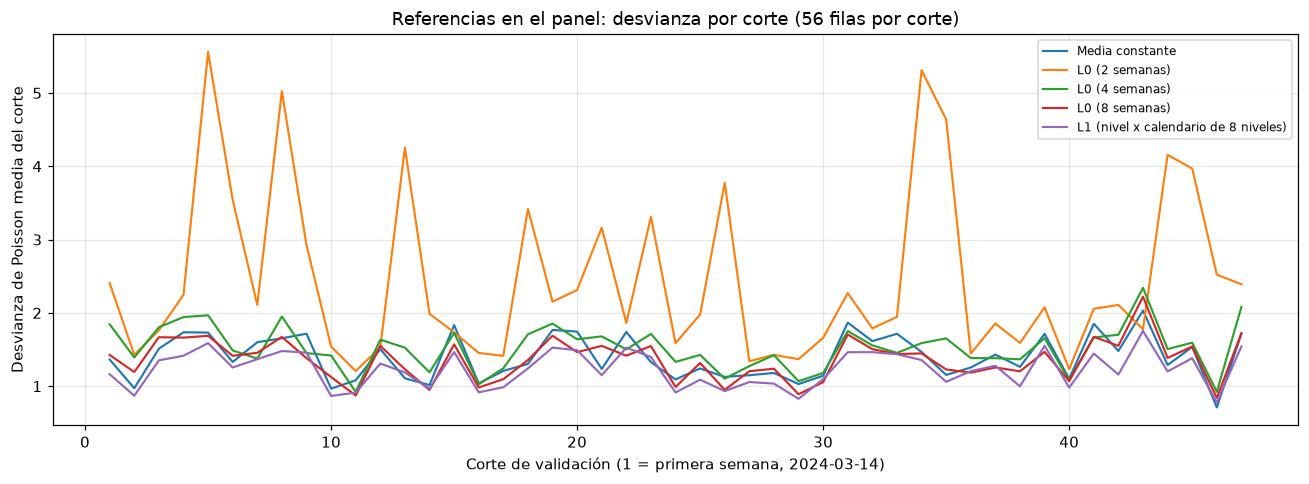

  guardado: experiments\modelos_candidatos\figuras\fig2_referencias_por_municipio.png


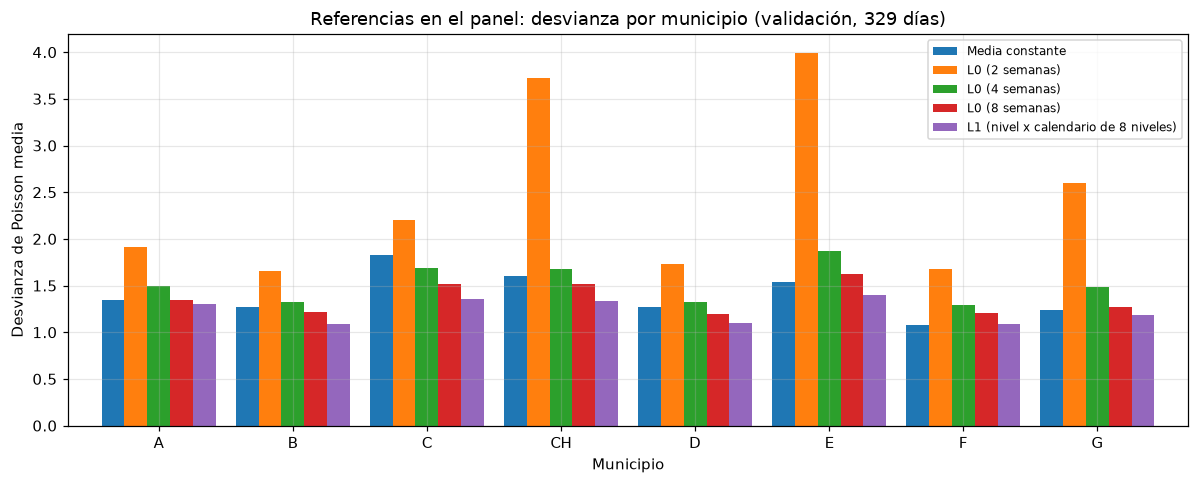

  guardado: experiments\modelos_candidatos\figuras\fig3_total_semanal_referencias.png


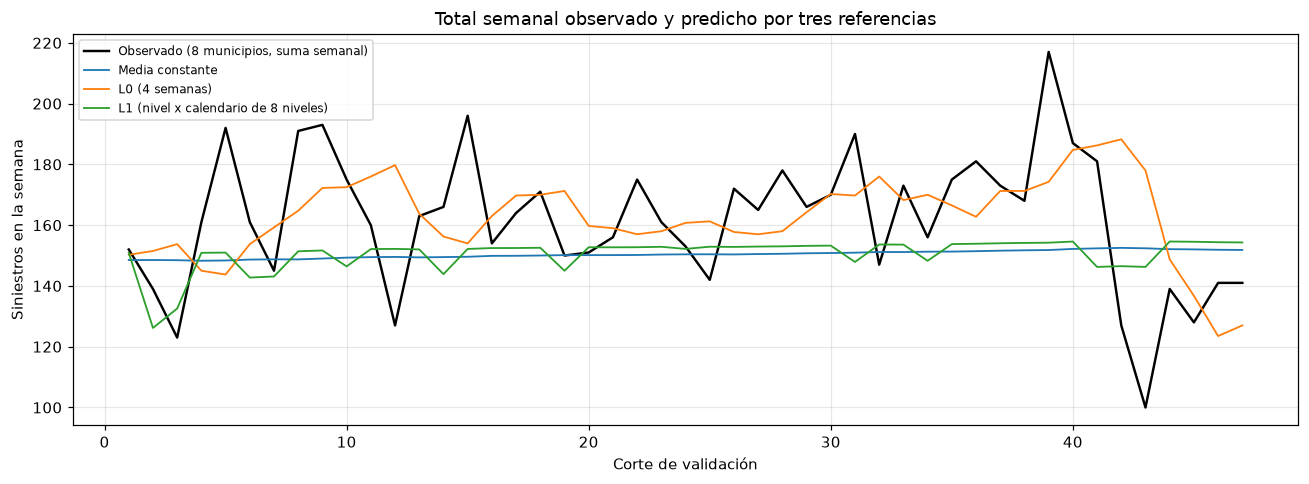

In [10]:
# fig1: desvianza por corte de cada referencia
fig, ax = plt.subplots(figsize=(12, 4.5))
for nombre in pred_ref:
    d = por_corte[por_corte["modelo"] == nombre]
    ax.plot(d["corte"], d["desvianza_poisson"], lw=1.4, label=nombre)
ax.set_xlabel("Corte de validación (1 = primera semana, 2024-03-14)")
ax.set_ylabel("Desvianza de Poisson media del corte")
ax.set_title("Referencias en el panel: desvianza por corte (56 filas por corte)")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "fig1_referencias_por_corte.png")
plt.show()

# fig2: desvianza por municipio
piv = por_mun.pivot(index="zona_id", columns="modelo", values="desvianza_poisson")
piv.index = [i.replace("MUNICIPIO ", "") for i in piv.index]
fig, ax = plt.subplots(figsize=(11, 4.5))
piv[list(pred_ref)].plot.bar(ax=ax, width=0.85)
ax.set_xlabel("Municipio")
ax.set_ylabel("Desvianza de Poisson media")
ax.set_title("Referencias en el panel: desvianza por municipio (validación, 329 días)")
ax.legend(fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=0)
fig.tight_layout()
guardar_figura(fig, "fig2_referencias_por_municipio.png")
plt.show()

# fig3: total semanal observado vs L1 y media constante
sem = todas.assign(fecha=pd.to_datetime(todas["fecha"])).groupby(["modelo", "corte"]).agg(
    obs=("n_siniestros", "sum"), pred=("pred", "sum")).reset_index()
fig, ax = plt.subplots(figsize=(12, 4.5))
o = sem[sem["modelo"] == "Media constante"]
ax.plot(o["corte"], o["obs"], "k-", lw=1.6, label="Observado (8 municipios, suma semanal)")
for nombre in ("Media constante", "L0 (4 semanas)", "L1 (nivel x calendario de 8 niveles)"):
    d = sem[sem["modelo"] == nombre]
    ax.plot(d["corte"], d["pred"], lw=1.2, label=nombre)
ax.set_xlabel("Corte de validación")
ax.set_ylabel("Siniestros en la semana")
ax.set_title("Total semanal observado y predicho por tres referencias")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "fig3_total_semanal_referencias.png")
plt.show()

## 7. Paso A — conjuntos de variables (ventana expansiva)

Reglas aplicadas: sección 1, adenda (ítems 2, 3 y 4) y precisiones de la fase 2 (D31 a D34 e ítem 5).

- **Familias.** GLM Poisson (`statsmodels`, enlace log, IRLS con los valores por defecto) y XGBoost con
  `objective="count:poisson"`, `max_depth=3`, `n_estimators=300`, `learning_rate=0.05` (D19) y el resto
  fijo (ítem 5 de las precisiones).
- **Conjuntos** (0), (a), (b) y (c); N ∈ {28, 56, 91} en (0) y en (c), elegido por desvianza media en
  validación **por separado en cada familia** (adenda, ítem 2).
- **Variables** sólo desde `src/variables.py` (`matriz_entrenamiento` para el entrenamiento con origen
  simulado, `variables_horizonte` para los 7 días a predecir), con la matriz de D31 y la forma de D34.
  Las mismas filas de entrenamiento para todos los conjuntos (decisión 2 de la Etapa 1).
- **Registro.** Cada configuración agrega una fila a `experiments/modelos_candidatos/registro_experimentos.csv`
  (D33: se reescribe en cada ejecución). Predicciones por corte, día y municipio en `tablas/17`.
- **Avisos y convergencia** de cada ajuste, por corte, en `tablas/16`. No se silencian: se registran.
- **Elección del conjunto por familia** con el ítem 4 de la adenda y D32. Se compara contra **L1** y
  **L0 de 8 semanas** (adenda, ítem 1), con el mismo motor y los mismos 47 cortes.

In [11]:
import json
from datetime import datetime
import statsmodels.api as sm
from statsmodels.discrete.discrete_model import NegativeBinomial

# --- Matriz de diseño (D31, D34): la misma para GLM y XGBoost ---
MUNICIPIOS = sorted(panel["zona_id"].unique())
MUN_COLS = ["mun_" + z.replace("MUNICIPIO ", "") for z in MUNICIPIOS]          # 8 columnas, sin constante
CAL_COLS = ["cal_" + n for n in var.NIVELES_CALENDARIO if n != "lunes"]        # 7 columnas, lunes = referencia
A_COLS = [c for c in var.COLUMNAS_A_X_CALENDARIO if c != "a_x_lunes"]          # 7 columnas, sin a_x_lunes
REZ_COLS = [f"rezago_{k}" for k in var.REZAGOS]                                # conteos crudos (D34)
SIMPLICIDAD = {"a": 1, "b": 2, "c": 3}                                         # adenda, ítem 4


def columnas_conjunto(conjunto, n=None):
    "Columnas de cada conjunto anidado de la sección 1; `n` = días del nivel reciente en (0) y (c)."
    if conjunto == "0":
        return MUN_COLS + [f"log_nivel_reciente_{n}"] + REZ_COLS
    cols = MUN_COLS + CAL_COLS
    if conjunto in ("b", "c"):
        cols = cols + A_COLS
    if conjunto == "c":
        cols = cols + [f"log_nivel_reciente_{n}"]
    return cols


NIVELES_VERIFICADOS = []      # cantidad de valores de nivel reciente comprobados > 0 (D34)


def disenio(df):
    "Matriz a partir de la salida de var.matriz_entrenamiento o var.variables_horizonte (sin calcular variables nuevas)."
    X = df[["fecha", "zona_id"] + (["n_siniestros"] if "n_siniestros" in df else [])].copy()
    for z, c in zip(MUNICIPIOS, MUN_COLS):
        X[c] = (df["zona_id"] == z).astype(float)
    cal = df["calendario"].astype(str)
    for c in CAL_COLS:
        X[c] = (cal == c.removeprefix("cal_")).astype(float)
    for c in A_COLS:
        X[c] = df[c].astype(float)
    for n in var.NIVELES_RECIENTES:
        nivel = df[f"nivel_reciente_{n}"]
        assert (nivel > 0).all(), f"nivel_reciente_{n} vale 0 (o falta) en alguna fila: log no definido (D34)"
        NIVELES_VERIFICADOS.append(len(nivel))
        X[f"log_nivel_reciente_{n}"] = np.log(nivel)
    for c in REZ_COLS:
        X[c] = df[c].astype(float)
    return X


_MATRICES = {}


def matrices(vista, origen, ventana):
    "Matrices de entrenamiento y del horizonte del corte; se calculan una vez por (origen, ventana) y se reusan."
    assert vista["zona_id"].nunique() == 8, "los candidatos se evalúan sólo sobre el panel completo"
    clave = (origen, ventana)
    if clave not in _MATRICES:
        ent = var.matriz_entrenamiento(vista, origen, dias_ventana=ventana)
        hor = var.variables_horizonte(vista, origen, dias_ventana=ventana)
        assert ent["fecha"].max() < origen and hor["fecha"].min() == origen and len(hor) == 56
        _MATRICES[clave] = (disenio(ent), disenio(hor))
    return _MATRICES[clave]


# --- Ajuste de cada familia (GLM Poisson y XGBoost desde el paso A; NB2 en el paso B) ---
XGB_FIJOS = dict(objective="count:poisson", tree_method="hist", subsample=1, colsample_bytree=1,
                 min_child_weight=1, reg_lambda=1, random_state=SEMILLA, n_jobs=1)    # ítem 5 de las precisiones
XGB_PASO_A = dict(max_depth=3, n_estimators=300, learning_rate=0.05)                 # D19

AJUSTES = []      # una fila por (configuración, corte): filas, convergencia, avisos, dispersión de Pearson


def con_avisos(f):
    "Ejecuta f() y devuelve también los avisos emitidos. No silencia nada (salvo el DeprecationWarning de pandas ya filtrado)."
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        warnings.filterwarnings("ignore", message="The .generic. unit for NumPy timedelta", category=DeprecationWarning)
        out = f()
    return out, [f"{a.category.__name__}: {a.message}" for a in avisos]


def ajustar_nb2(X, y, Xh):
    "NB2 con α por máxima verosimilitud en el corte (adenda, ítem 5); si no converge según el ítem 6 (D29), plan B (D28)."
    res, avisos = con_avisos(lambda: NegativeBinomial(y, X, loglike_method="nb2").fit(method="newton", maxiter=100, disp=0))
    alpha = float(res.params["alpha"])
    no_convergio = (not res.mle_retvals["converged"]
                    or any(a.startswith("ConvergenceWarning") for a in avisos)
                    or not np.isfinite(alpha) or alpha <= 0)
    extra = {"convergio": not no_convergio, "iteraciones": res.mle_retvals["iterations"], "alpha_mv": alpha,
             "plan_b": no_convergio, "alpha_momentos": np.nan}
    if not no_convergio:
        return res.predict(Xh), extra, avisos
    # Plan B (D28): GLM NB con α por momentos en el mismo corte. Regresión auxiliar sin intercepto de ((y − μ)² − y)/μ
    # sobre μ, con μ del GLM Poisson ajustado en el entrenamiento de este corte (Cameron y Trivedi, 1990).
    mu = sm.GLM(y, X, family=sm.families.Poisson()).fit().fittedvalues
    alpha_m = float(sm.OLS(((y - mu) ** 2 - y) / mu, mu).fit().params.iloc[0])
    assert np.isfinite(alpha_m) and alpha_m > 0, "α por momentos no positivo: caso no cubierto por D28; detenerse y consultar"
    res_b, avisos_b = con_avisos(lambda: sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha_m)).fit())
    extra["alpha_momentos"] = alpha_m
    return res_b.predict(Xh), extra, avisos + avisos_b


def modelo_candidato(config, familia, conjunto, n=None, hiper=None):
    cols = columnas_conjunto(conjunto, n)

    def modelo(vista, origen, ventana):
        ent, hor = matrices(vista, origen, ventana)
        X, y, Xh = ent[cols], ent["n_siniestros"], hor[cols]
        fila = {"configuracion": config, "origen": origen, "filas_entrenamiento": len(ent),
                "dias_entrenamiento": ent["fecha"].nunique()}
        if familia == "GLM Poisson":
            res, avisos = con_avisos(lambda: sm.GLM(y, X, family=sm.families.Poisson()).fit())
            pred = res.predict(Xh)
            fila.update(convergio=bool(res.converged), iteraciones=res.fit_history["iteration"],
                        dispersion_pearson=res.pearson_chi2 / res.df_resid)
        elif familia == "XGBoost":
            m, avisos = con_avisos(lambda: xgboost.XGBRegressor(**XGB_FIJOS, **hiper).fit(X, y))
            pred = m.predict(Xh)
        elif familia == "NB2":
            pred, extra, avisos = ajustar_nb2(X, y, Xh)
            fila.update(extra)
        else:
            raise ValueError(familia)
        fila.update(n_avisos=len(avisos), avisos=" | ".join(sorted(set(avisos))))
        AJUSTES.append(fila)
        return hor[["fecha", "zona_id"]].assign(pred=np.asarray(pred, dtype=float))
    return modelo


# --- Evaluación y registro (D33) ---
REGISTRO, PRED_CAND, META = [], {}, {}
RUTA_REGISTRO = DIR_EXPERIMENTO / "registro_experimentos.csv"


def evaluar_configuracion(paso, config, familia, conjunto, n=None, hiper=None, ventana=None):
    "Backtest de una configuración en los 47 cortes y su fila del registro."
    pred = backtest(panel, modelo_candidato(config, familia, conjunto, n, hiper), ventana=ventana)
    PRED_CAND[config] = pred
    hip = {"GLM Poisson": lambda: {"familia": "Poisson", "enlace": "log", "ajuste": "IRLS (statsmodels GLM, por defecto)"},
           "NB2": lambda: {"familia": "binomial negativa NB2 (varianza μ + αμ²)", "enlace": "log",
                           "ajuste": "NegativeBinomial(loglike_method='nb2').fit(method='newton', maxiter=100)",
                           "alpha": "máxima verosimilitud en cada corte", "plan_b": "GLM NB con α por momentos (D28)"},
           "XGBoost": lambda: {**XGB_FIJOS, **hiper}}[familia]()
    META[config] = dict(paso=paso, modelo=familia, conjunto=conjunto, N=n, ventana=ventana, hiper=hiper)
    g = evaluar(pred["n_siniestros"], pred["pred"])
    est = resumen_estabilidad({config: pred}).iloc[0]
    aj = pd.DataFrame([a for a in AJUSTES if a["configuracion"] == config])
    assert len(aj) == len(ORIGENES)
    no_conv = int((~aj["convergio"].astype(bool)).sum()) if "convergio" in aj and aj["convergio"].notna().all() else None
    REGISTRO.append({
        "paso": paso, "configuracion": config, "modelo": familia, "conjunto": conjunto, "N": n,
        "hiperparametros": json.dumps(hip, ensure_ascii=False),
        "ventana": "expansiva" if ventana is None else f"deslizante {ventana} días",
        "n_predicciones": g["n"], "desvianza": est["desvianza_media"],
        "error_estandar": est["error_estandar_47_cortes"], "mae": g["mae"], "rmse": g["rmse"],
        "total_pred_obs": g["razon_total"], "dias_prediccion_cero": g["dias_prediccion_cero"],
        "peor_municipio": est["peor_municipio"], "desvianza_peor_municipio": est["desvianza_peor_municipio"],
        "desvio_entre_cortes": est["desvio_entre_cortes"],
        "cortes_no_convergidos": no_conv, "cortes_con_avisos": int((aj["n_avisos"] > 0).sum()),
        "cortes_plan_b": int(aj["plan_b"].sum()) if "plan_b" in aj else None,     # sólo aplica a NB2
        "fecha_hora": datetime.now().isoformat(timespec="seconds"),
    })
    assert abs(g["desvianza_poisson"] - est["desvianza_media"]) < 1e-9     # cortes de igual peso (sección 4)
    return pred


def escribir_registro():
    reg = pd.DataFrame(REGISTRO)
    reg.round(6).to_csv(RUTA_REGISTRO, index=False, encoding="utf-8")
    print("  guardado:", RUTA_REGISTRO.relative_to(RAIZ), f"({len(reg)} filas)")
    return reg

In [12]:
CONFIGS_A = []
for familia, hiper in (("GLM Poisson", None), ("XGBoost", XGB_PASO_A)):
    for conjunto in ("0", "a", "b", "c"):
        for n in (var.NIVELES_RECIENTES if conjunto in ("0", "c") else (None,)):
            config = f"{familia} ({conjunto})" + (f" N={n}" if n else "")
            evaluar_configuracion("A", config, familia, conjunto, n, hiper)
            CONFIGS_A.append(config)

print(f"nivel reciente > 0 en todos los valores usados (D34): {sum(NIVELES_VERIFICADOS):,} comprobados")
ajustes_a = pd.DataFrame([a for a in AJUSTES if a["configuracion"] in CONFIGS_A])
ajustes_a["origen"] = ajustes_a["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(ajustes_a.round(6), "16_paso_a_ajustes_por_corte.csv")
print("ajustes con avisos:", int((ajustes_a["n_avisos"] > 0).sum()), "de", len(ajustes_a),
      "| GLM no convergidos:", int((ajustes_a["convergio"] == False).sum()))
registro = escribir_registro()
registro[["configuracion", "desvianza", "error_estandar", "total_pred_obs", "peor_municipio",
          "cortes_no_convergidos", "cortes_con_avisos"]].round(4)

nivel reciente > 0 en todos los valores usados (D34): 1,200,192 comprobados
  guardado: experiments\modelos_candidatos\tablas\16_paso_a_ajustes_por_corte.csv (752 filas)
ajustes con avisos: 0 de 752 | GLM no convergidos: 0
  guardado: experiments\modelos_candidatos\registro_experimentos.csv (16 filas)


,configuracion,desvianza,error_estandar,total_pred_obs,peor_municipio,cortes_no_convergidos,cortes_con_avisos
0,GLM Poisson (0) N=28,1.2760,0.0389,0.9524,MUNICIPIO E,0.0,0
1,GLM Poisson (0) N=56,1.2769,0.0388,0.9485,MUNICIPIO E,0.0,0
2,GLM Poisson (0) N=91,1.2757,0.0389,0.9529,MUNICIPIO E,0.0,0
3,GLM Poisson (a),1.2302,0.0359,0.9341,MUNICIPIO E,0.0,0
4,GLM Poisson (b),1.2207,0.0362,0.9341,MUNICIPIO E,0.0,0
5,GLM Poisson (c) N=28,1.2150,0.0363,0.9523,MUNICIPIO E,0.0,0
6,GLM Poisson (c) N=56,1.2167,0.0363,0.9479,MUNICIPIO E,0.0,0
7,GLM Poisson (c) N=91,1.2168,0.0364,0.9480,MUNICIPIO E,0.0,0
8,XGBoost (0) N=28,1.2864,0.0395,0.9590,MUNICIPIO C,NaN,0
9,XGBoost (0) N=56,1.2866,0.0412,0.9675,MUNICIPIO C,NaN,0


In [13]:
REF_COMPARACION = {n: pred_ref[n] for n in ("L1 (nivel x calendario de 8 niveles)", "L0 (8 semanas)")}
L1 = "L1 (nivel x calendario de 8 niveles)"


def familia_de(nombre):
    return META[nombre]["modelo"] if nombre in META else "referencia"


def marcar_1ee(t, grupo=None, col="desvianza", ee="error_estandar"):
    "Marca las filas a menos de 1 error estándar de la mejor (la de menor desvianza), en toda la tabla o por grupo."
    def _m(g):
        mejor = g.loc[g[col].idxmin()]
        return g[col] <= mejor[col] + mejor[ee]
    if grupo is None:
        return _m(t)
    return t.groupby(grupo, group_keys=False).apply(_m, include_groups=False)


def tabla_comparacion(configs, referencias=REF_COMPARACION):
    "Tabla global: métricas, error estándar sobre 47 cortes, estabilidad y comparación contra L1 y L0 de 8 semanas."
    preds = {**{c: PRED_CAND[c] for c in configs}, **referencias}
    est = resumen_estabilidad(preds)
    t = tabla_metricas(preds).merge(est, on="modelo")
    t = t.rename(columns={"desvianza_media": "desvianza", "error_estandar_47_cortes": "error_estandar",
                          "razon_total": "total_pred_obs"}).drop(columns="desvianza_poisson")
    t.insert(1, "familia", t["modelo"].map(familia_de))
    pc = tabla_metricas(preds, "corte").pivot(index="corte", columns="modelo", values="desvianza_poisson")
    t["diferencia_vs_L1"] = t["desvianza"] - t.loc[t["modelo"] == L1, "desvianza"].iloc[0]
    t["diferencia_vs_L0_8sem"] = t["desvianza"] - t.loc[t["modelo"] == "L0 (8 semanas)", "desvianza"].iloc[0]
    t["cortes_que_gana_a_L1"] = t["modelo"].map(lambda m: int((pc[m] < pc[L1]).sum()))
    t["a_menos_de_1_ee_del_mejor_de_la_tabla"] = marcar_1ee(t)
    t["a_menos_de_1_ee_del_mejor_de_su_familia"] = marcar_1ee(t, "familia")
    return t.sort_values("desvianza").reset_index(drop=True)


def tabla_por_municipio(configs, referencias=REF_COMPARACION):
    "Por municipio: desvianza, su error estándar sobre los 47 cortes (7 filas por corte), total pred./obs. y marca de 1 EE."
    preds = {**{c: PRED_CAND[c] for c in configs}, **referencias}
    filas = []
    for nombre, df in preds.items():
        for z, g in df.groupby("zona_id"):
            d = np.array([evaluar(h["n_siniestros"], h["pred"])["desvianza_poisson"] for _, h in g.groupby("corte")])
            m = evaluar(g["n_siniestros"], g["pred"])
            filas.append({"zona_id": z, "modelo": nombre, "familia": familia_de(nombre),
                          "desvianza": m["desvianza_poisson"], "error_estandar": d.std(ddof=1) / np.sqrt(len(d)),
                          "mae": m["mae"], "total_pred_obs": m["razon_total"],
                          "dias_prediccion_cero": m["dias_prediccion_cero"]})
    t = pd.DataFrame(filas)
    t["a_menos_de_1_ee_del_mejor_del_municipio"] = marcar_1ee(t, "zona_id")
    return t.sort_values(["zona_id", "desvianza"]).reset_index(drop=True)


glob_a = tabla_comparacion(CONFIGS_A)
guardar_tabla(glob_a.round(6), "11_paso_a_globales.csv")
mun_a = tabla_por_municipio(CONFIGS_A)
guardar_tabla(mun_a.round(6), "12_paso_a_por_municipio.csv")

preds_a = {**{c: PRED_CAND[c] for c in CONFIGS_A}, **REF_COMPARACION}
corte_a = tabla_metricas(preds_a, "corte")
guardar_tabla(corte_a.round(6), "13_paso_a_por_corte.csv")

glob_a[["modelo", "desvianza", "error_estandar", "mae", "rmse", "total_pred_obs", "dias_prediccion_cero",
        "peor_municipio", "desvianza_peor_municipio", "diferencia_vs_L1", "cortes_que_gana_a_L1",
        "a_menos_de_1_ee_del_mejor_de_la_tabla", "a_menos_de_1_ee_del_mejor_de_su_familia"]].round(4)

  guardado: experiments\modelos_candidatos\tablas\11_paso_a_globales.csv (18 filas)


  guardado: experiments\modelos_candidatos\tablas\12_paso_a_por_municipio.csv (144 filas)


  guardado: experiments\modelos_candidatos\tablas\13_paso_a_por_corte.csv (846 filas)


,modelo,desvianza,error_estandar,mae,rmse,total_pred_obs,dias_prediccion_cero,peor_municipio,desvianza_peor_municipio,diferencia_vs_L1,cortes_que_gana_a_L1,a_menos_de_1_ee_del_mejor_de_la_tabla,a_menos_de_1_ee_del_mejor_de_su_familia
0,GLM Poisson (c) N=28,1.2150,0.0363,1.3981,1.7826,0.9523,0,MUNICIPIO E,1.4121,-0.0169,38,True,True
1,GLM Poisson (c) N=56,1.2167,0.0363,1.3992,1.7840,0.9479,0,MUNICIPIO E,1.4018,-0.0152,37,True,True
2,GLM Poisson (c) N=91,1.2168,0.0364,1.3996,1.7841,0.9480,0,MUNICIPIO E,1.4011,-0.0151,35,True,True
3,XGBoost (b),1.2200,0.0362,1.3997,1.7888,0.9338,0,MUNICIPIO E,1.3997,-0.0119,32,True,True
4,GLM Poisson (b),1.2207,0.0362,1.3990,1.7876,0.9341,0,MUNICIPIO E,1.3995,-0.0111,35,True,True
5,XGBoost (a),1.2217,0.0361,1.3999,1.7900,0.9338,0,MUNICIPIO E,1.4004,-0.0102,31,True,True
6,XGBoost (c) N=28,1.2219,0.0370,1.4051,1.7894,0.9586,0,MUNICIPIO E,1.4454,-0.0100,29,True,True
7,XGBoost (c) N=56,1.2224,0.0382,1.4082,1.7893,0.9667,0,MUNICIPIO E,1.4165,-0.0095,29,True,True
8,XGBoost (c) N=91,1.2243,0.0373,1.4074,1.7919,0.9730,0,MUNICIPIO E,1.4219,-0.0075,27,True,True
9,GLM Poisson (a),1.2302,0.0359,1.4013,1.7951,0.9341,0,MUNICIPIO E,1.4019,-0.0017,36,True,True


In [14]:
# Desvianza y total pred./obs. por municipio (pivote de tablas/12); * = a menos de 1 EE del mejor del municipio
_p = mun_a.assign(v=mun_a["desvianza"].map("{:.4f}".format)
                  + np.where(mun_a["a_menos_de_1_ee_del_mejor_del_municipio"], "*", ""))
print("Desvianza por municipio (* = a menos de 1 EE del mejor del municipio)")
display(_p.pivot(index="modelo", columns="zona_id", values="v").loc[glob_a["modelo"]])
print("Total predicho / observado por municipio")
mun_a.pivot(index="modelo", columns="zona_id", values="total_pred_obs").loc[glob_a["modelo"]].round(4)

Desvianza por municipio (* = a menos de 1 EE del mejor del municipio)


zona_id,MUNICIPIO A,MUNICIPIO B,MUNICIPIO C,MUNICIPIO CH,MUNICIPIO D,MUNICIPIO E,MUNICIPIO F,MUNICIPIO G
modelo,,,,,,,,
GLM Poisson (c) N=28,1.2165*,1.0870*,1.3363*,1.3277*,1.0958*,1.4121*,1.0647*,1.1796*
GLM Poisson (c) N=56,1.2209*,1.0827*,1.3397*,1.3343*,1.0982*,1.4018*,1.0743*,1.1814*
GLM Poisson (c) N=91,1.2225*,1.0848*,1.3368*,1.3322*,1.1015*,1.4011*,1.0736*,1.1815*
XGBoost (b),1.2478*,1.0833*,1.3459*,1.3408*,1.1044*,1.3997*,1.0594*,1.1785*
GLM Poisson (b),1.2388*,1.0836*,1.3484*,1.3307*,1.0991*,1.3995*,1.0818*,1.1840*
XGBoost (a),1.2511*,1.0826*,1.3449*,1.3410*,1.1068*,1.4004*,1.0658*,1.1806*
XGBoost (c) N=28,1.2285*,1.0903*,1.3573*,1.3318*,1.1021*,1.4454*,1.0511*,1.1685*
XGBoost (c) N=56,1.2174*,1.0829*,1.3614*,1.3496*,1.1076*,1.4165*,1.0674*,1.1766*
XGBoost (c) N=91,1.2130*,1.0886*,1.3699*,1.3335*,1.1110*,1.4219*,1.0741*,1.1826*


Total predicho / observado por municipio


zona_id,MUNICIPIO A,MUNICIPIO B,MUNICIPIO C,MUNICIPIO CH,MUNICIPIO D,MUNICIPIO E,MUNICIPIO F,MUNICIPIO G
modelo,,,,,,,,
GLM Poisson (c) N=28,0.9001,1.0058,0.9378,1.0117,0.9685,0.9483,0.9160,0.9529
GLM Poisson (c) N=56,0.8917,1.0083,0.9315,1.0143,0.9653,0.9440,0.9083,0.9440
GLM Poisson (c) N=91,0.8927,1.0092,0.9319,1.0134,0.9640,0.9433,0.9091,0.9439
XGBoost (b),0.8613,0.9897,0.9036,1.0221,0.9459,0.9490,0.9015,0.9422
GLM Poisson (b),0.8692,1.0018,0.9138,1.0050,0.9590,0.9328,0.8897,0.9277
XGBoost (a),0.8631,0.9934,0.9059,1.0180,0.9487,0.9450,0.8978,0.9387
XGBoost (c) N=28,0.9115,0.9873,0.9163,1.0332,0.9502,0.9820,0.9616,0.9754
XGBoost (c) N=56,0.9142,1.0017,0.9310,1.0408,0.9457,0.9574,0.9930,0.9922
XGBoost (c) N=91,0.9492,1.0067,0.9455,1.0296,0.9480,0.9594,0.9737,1.0024


In [15]:
def elegir_conjunto(familia, glob, configs):
    "Ítem 4 de la adenda con D32. Devuelve (configuración elegida, filas con cada paso de la regla)."
    g = glob.set_index("modelo")
    dev, ee = g["desvianza"], g["error_estandar"]
    propias = [c for c in configs if META[c]["modelo"] == familia]
    pasos, mejor_n = [], {}
    for conj in ("0", "c"):                                           # adenda, ítem 2: N por desvianza media
        cands = [c for c in propias if META[c]["conjunto"] == conj]
        mejor_n[conj] = min(cands, key=lambda c: dev[c])
        for c in cands:
            pasos.append({"familia": familia, "paso": f"N de ({conj}) por desvianza media", "configuracion": c,
                          "desvianza": dev[c], "error_estandar": ee[c], "resultado": "elegido" if c == mejor_n[conj] else ""})
    abc = [c for c in propias if META[c]["conjunto"] in ("a", "b")] + [mejor_n["c"]]
    mejor = min(abc, key=lambda c: dev[c])
    umbral = dev[mejor] + ee[mejor]
    empatados = [c for c in abc if dev[c] <= umbral]
    elegido = min(empatados, key=lambda c: SIMPLICIDAD[META[c]["conjunto"]])
    for c in abc:
        pasos.append({"familia": familia, "paso": "(a), (b), (c): a menos de 1 EE del mejor", "configuracion": c,
                      "desvianza": dev[c], "error_estandar": ee[c],
                      "resultado": ("mejor; " if c == mejor else "") + (f"empatado (≤ {umbral:.4f})" if c in empatados else f"fuera (> {umbral:.4f})")})
    pasos.append({"familia": familia, "paso": "el más simple entre los empatados (a < b < c)", "configuracion": elegido,
                  "desvianza": dev[elegido], "error_estandar": ee[elegido], "resultado": "elegido entre (a), (b), (c)"})
    cero = mejor_n["0"]
    mejora = dev[elegido] - dev[cero]
    reemplaza = bool(mejora > ee[cero])                                # D32
    pasos.append({"familia": familia, "paso": "¿(0) reemplaza? desv(elegido) − desv(0) > EE(0)", "configuracion": cero,
                  "desvianza": dev[cero], "error_estandar": ee[cero],
                  "resultado": f"{mejora:.4f} {'>' if reemplaza else '≤'} {ee[cero]:.4f}: {'reemplaza' if reemplaza else 'no reemplaza'}"})
    final = cero if reemplaza else elegido
    pasos.append({"familia": familia, "paso": "conjunto elegido para la familia", "configuracion": final,
                  "desvianza": dev[final], "error_estandar": ee[final], "resultado": "ELEGIDO"})
    return final, pasos


ELEGIDO_A, _filas = {}, []
for fam in ("GLM Poisson", "XGBoost"):
    ELEGIDO_A[fam], p = elegir_conjunto(fam, glob_a, CONFIGS_A)
    _filas += p
eleccion_a = pd.DataFrame(_filas)
guardar_tabla(eleccion_a.round(6), "14_paso_a_eleccion.csv")
print("Elegido por familia:", ELEGIDO_A)
eleccion_a.round(4)

  guardado: experiments\modelos_candidatos\tablas\14_paso_a_eleccion.csv (24 filas)
Elegido por familia: {'GLM Poisson': 'GLM Poisson (a)', 'XGBoost': 'XGBoost (a)'}


,familia,paso,configuracion,desvianza,error_estandar,resultado
0,GLM Poisson,N de (0) por desvianza media,GLM Poisson (0) N=28,1.2760,0.0389,
1,GLM Poisson,N de (0) por desvianza media,GLM Poisson (0) N=56,1.2769,0.0388,
2,GLM Poisson,N de (0) por desvianza media,GLM Poisson (0) N=91,1.2757,0.0389,elegido
3,GLM Poisson,N de (c) por desvianza media,GLM Poisson (c) N=28,1.2150,0.0363,elegido
4,GLM Poisson,N de (c) por desvianza media,GLM Poisson (c) N=56,1.2167,0.0363,
5,GLM Poisson,N de (c) por desvianza media,GLM Poisson (c) N=91,1.2168,0.0364,
6,GLM Poisson,"(a), (b), (c): a menos de 1 EE del mejor",GLM Poisson (a),1.2302,0.0359,empatado (≤ 1.2513)
7,GLM Poisson,"(a), (b), (c): a menos de 1 EE del mejor",GLM Poisson (b),1.2207,0.0362,empatado (≤ 1.2513)
8,GLM Poisson,"(a), (b), (c): a menos de 1 EE del mejor",GLM Poisson (c) N=28,1.2150,0.0363,mejor; empatado (≤ 1.2513)
9,GLM Poisson,el más simple entre los empatados (a < b < c),GLM Poisson (a),1.2302,0.0359,"elegido entre (a), (b), (c)"


In [16]:
# Dispersión de Pearson del GLM Poisson con el conjunto elegido: chi² de Pearson / gl residuales, en el entrenamiento de cada corte
_disp = ajustes_a[ajustes_a["configuracion"] == ELEGIDO_A["GLM Poisson"]][["origen", "filas_entrenamiento", "dispersion_pearson"]]
_disp = _disp.reset_index(drop=True)
_disp.insert(0, "corte", range(1, len(_disp) + 1))
dispersion = pd.DataFrame([{
    "configuracion": ELEGIDO_A["GLM Poisson"], "n_cortes": len(_disp),
    "minimo": _disp["dispersion_pearson"].min(), "mediana": _disp["dispersion_pearson"].median(),
    "maximo": _disp["dispersion_pearson"].max(),
    "primer_corte": _disp["dispersion_pearson"].iloc[0], "ultimo_corte": _disp["dispersion_pearson"].iloc[-1],
}])
guardar_tabla(dispersion.round(6), "15_paso_a_dispersion_pearson.csv")
dispersion.round(4)

  guardado: experiments\modelos_candidatos\tablas\15_paso_a_dispersion_pearson.csv (1 filas)


,configuracion,n_cortes,minimo,mediana,maximo,primer_corte,ultimo_corte
0,GLM Poisson (a),47,1.1035,1.1109,1.1171,1.11,1.1124


  guardado: experiments\modelos_candidatos\figuras\fig4_paso_a_desvianza.png


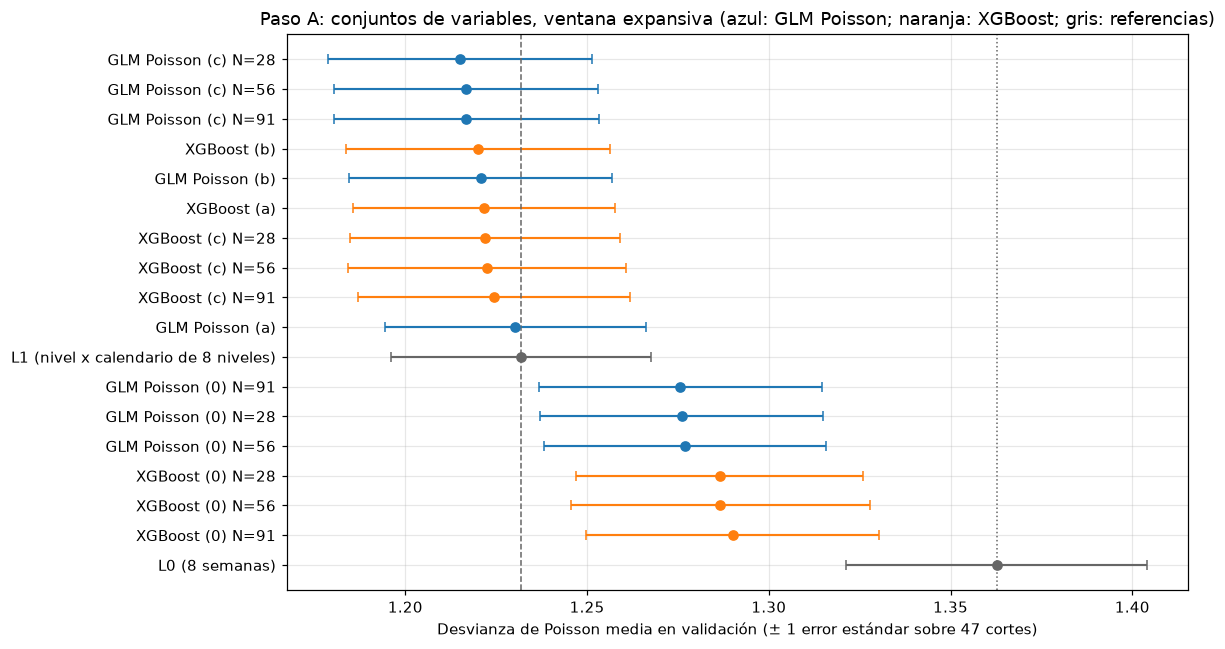

  guardado: experiments\modelos_candidatos\tablas\17_paso_a_predicciones.csv (42112 filas)


,configuracion,corte,origen,fecha,zona_id,n_siniestros,pred
0,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO A,0,2.753226
1,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO B,3,3.511780
2,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO C,4,3.251888
3,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO CH,1,2.098869
4,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO D,3,3.133004
...,...,...,...,...,...,...,...
42107,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO CH,3,2.266686
42108,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO D,6,3.361124
42109,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO E,6,2.308086
42110,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO F,3,3.098880


In [17]:
# fig4: desvianza ± 1 EE de las configuraciones del paso A, con L1 y L0 de 8 semanas
fig, ax = plt.subplots(figsize=(11, 6))
t = glob_a.iloc[::-1]
y_pos = pd.Series(range(len(t)), index=t.index)
for fam, color in (("GLM Poisson", "C0"), ("XGBoost", "C1"), ("referencia", "0.4")):
    f = t[t["familia"] == fam]
    ax.errorbar(f["desvianza"], y_pos[f.index], xerr=f["error_estandar"], fmt="o", color=color, elinewidth=1.4, capsize=3)
ax.set_yticks(range(len(t)), t["modelo"])
for nombre, ls in ((L1, "--"), ("L0 (8 semanas)", ":")):
    ax.axvline(t.loc[t["modelo"] == nombre, "desvianza"].iloc[0], color="0.4", ls=ls, lw=1)
ax.set_xlabel("Desvianza de Poisson media en validación (± 1 error estándar sobre 47 cortes)")
ax.set_title("Paso A: conjuntos de variables, ventana expansiva (azul: GLM Poisson; naranja: XGBoost; gris: referencias)")
fig.tight_layout()
guardar_figura(fig, "fig4_paso_a_desvianza.png")
plt.show()

predicciones_a = pd.concat([PRED_CAND[c].assign(configuracion=c) for c in CONFIGS_A], ignore_index=True)
predicciones_a["origen"] = predicciones_a["origen"].dt.strftime("%Y-%m-%d")
predicciones_a["fecha"] = predicciones_a["fecha"].dt.strftime("%Y-%m-%d")
guardar_tabla(predicciones_a[["configuracion", "corte", "origen", "fecha", "zona_id", "n_siniestros", "pred"]].round(6),
              "17_paso_a_predicciones.csv")

### 7.1 Lectura del paso A

Todas las cifras salen de `tablas/11` (globales), `12` (por municipio), `13` (por corte), `14` (elección), `15`
(dispersión de Pearson) y `16` (ajustes por corte). Desvianza = desvianza de Poisson media en validación (47 cortes).

**Evidencia**

- **Elección por familia (ítem 4 de la adenda, D32).** En las dos familias, (a), (b) y (c) quedan a menos de 1 error
  estándar del mejor de los tres, y la simplicidad elige **(a)**:
  - GLM Poisson: el mejor es (c) N=28 (1,2150; EE 0,0363; umbral 1,2513); elegido **(a)** (1,2302; EE 0,0359).
  - XGBoost: el mejor es (b) (1,2200; EE 0,0362; umbral 1,2562); elegido **(a)** (1,2217; EE 0,0361).
  - (0) no reemplaza en ninguna: GLM (0) N=91 da 1,2757 (desv(a) − desv(0) = −0,0454 ≤ EE(0) = 0,0389); XGBoost (0)
    N=28 da 1,2864 (−0,0648 ≤ 0,0395). (0) es peor que (a), no mejor.
- **N elegido:** GLM (0) N=91, GLM (c) N=28, XGBoost (0) N=28, XGBoost (c) N=28. Entre los tres N de cada conjunto la
  desvianza cambia a lo sumo 0,0036, muy por debajo de 1 EE.
- **Contra las referencias.** L1 (1,2319; EE 0,0358) también queda a menos de 1 EE del mejor de la tabla: **por el
  criterio de 1 EE, ninguna configuración de (a), (b) o (c) se distingue de L1**. GLM (a) queda a −0,0017 de L1; la
  mejor configuración, GLM (c) N=28, a −0,0169, y le gana a L1 en 38 de 47 cortes. Las seis de (0) quedan por encima de
  L1 (+0,0438 a +0,0581) y por debajo de L0 de 8 semanas (−0,0726 a −0,0870).
- **Ajustes:** 752 (16 configuraciones × 47 cortes), **ningún aviso**; los 376 ajustes del GLM convergieron (5
  iteraciones de IRLS cada uno). Ninguna predicción igual a 0. El peor municipio es E en todas las configuraciones salvo
  las tres de XGBoost (0), donde es C.
- **Dispersión de Pearson del GLM Poisson (a)**, en el entrenamiento de cada corte: de 1,1035 a 1,1171, mediana 1,1109.

**¿(c) corrige la subestimación de L1 (total pred./obs. 0,9305)?** *Evidencia:* en parte. El total predicho / observado
pasa de 0,9341 en GLM (a) a 0,9523 en GLM (c) N=28 (0,9479 y 0,9480 con N=56 y 91), y de 0,9338 en XGBoost (a) a entre
0,9586 y 0,9730 en XGBoost (c). Ninguna llega a 1. Por municipio, A sigue siendo el más subestimado (GLM (c) N=28: 0,9001,
contra 0,8641 de L1), seguido de F (0,9160, contra 0,8862). En desvianza, GLM (c) N=28 mejora a GLM (a) en 0,0152 y le gana
en 38 de 47 cortes, pero queda dentro de 1 EE; en XGBoost, (c) N=28 no mejora a (a) (+0,0002; gana en 26 de 47).
*Inferencia:* el nivel reciente absorbe una parte de la tendencia creciente, pero no toda. Qué explica el resto no se
investigó en este paso.

**¿El término de A aporta en el panel como en el diagnóstico?** *Evidencia:* en el GLM, sí en A y casi nada en el global.
La desvianza de A baja de 1,2950 con (a) a 1,2388 con (b), un −4,34 %. En el diagnóstico, el calendario propio mejoraba a A
en 4,06 % y 4,24 % en los dos pliegues (`resumen_diagnostico_municipios.md` §7.3). Son protocolos distintos (allí, un ajuste
fijo por pliegue), así que se compara la dirección y el orden de magnitud, no la cifra. Globalmente, (b) mejora a (a) en
0,0095 (EE 0,0362) y le gana en 33 de 47 cortes. En XGBoost el término casi no cambia nada: A pasa de 1,2511 a 1,2478 y el
global, de 1,2217 a 1,2200. *Inferencia:* XGBoost (a) ya modela A mejor que GLM (a) (1,2511 contra 1,2950), lo que sugiere que
los árboles de profundidad 3 encuentran la interacción municipio × calendario sin el término explícito.

**Inferencia general.** Con este protocolo y esta regla, ninguno de los bloques que el diagnóstico motivó (término de A,
nivel reciente) supera el umbral de 1 EE. El EE se calcula entre cortes y recoge las semanas difíciles que afectan a todos
los modelos por igual; las comparaciones corte a corte (38 de 47, 33 de 47) muestran diferencias más consistentes de lo que el
umbral deja ver. La regla está fijada y se aplica como está; esta lectura no la modifica.

## 8. Paso B — hiperparámetros de XGBoost y binomial negativa (ventana expansiva)

Sobre el conjunto elegido en el paso A para cada familia (sección 7: **(a)** en las dos; el código lo toma de `ELEGIDO_A`).

- **XGBoost:** las 12 combinaciones de la grilla de la sección 1 (`max_depth` ∈ {2, 3, 4} × `n_estimators` ∈ {100, 300} ×
  `learning_rate` ∈ {0.05, 0.1}), con el resto de los parámetros fijos (ítem 5 de las precisiones de la fase 2). La combinación
  (3, 300, 0.05) es la del paso A: se vuelve a evaluar y se verifica que da exactamente las mismas predicciones.
- **Binomial negativa NB2** (adenda, ítems 5 y 6): α por máxima verosimilitud en cada corte, `method="newton"`, `maxiter=100`. Un
  corte es **no convergido** si `mle_retvals["converged"]` es `False`, si hay un `ConvergenceWarning` o si α no es finito o no es
  positivo; en ese corte se usa el **plan B** (D28). Se reporta α por corte y cuántos cortes usaron el plan B. Si el α por momentos
  del plan B no fuera positivo (caso que D28 no cubre), la ejecución se detiene.
- **Selección por familia** con la regla de la sección 1 y las precisiones D36 a D38: familia GLM = GLM Poisson (a) del paso A y
  NB2 (a); familia XGBoost = las 12 combinaciones. Cada paso de la regla queda en `tablas/23`.

In [18]:
GRILLA_XGB = [dict(max_depth=d, n_estimators=n, learning_rate=lr) for d in (2, 3, 4) for n in (100, 300) for lr in (0.05, 0.1)]
CONJ_GLM_B = META[ELEGIDO_A["GLM Poisson"]]["conjunto"]
CONJ_XGB_B = META[ELEGIDO_A["XGBoost"]]["conjunto"]


def nombre_xgb(conjunto, h):
    return f"XGBoost ({conjunto}) d={h['max_depth']} n={h['n_estimators']} lr={h['learning_rate']}"


CONFIG_NB2 = f"NB2 ({CONJ_GLM_B})"
evaluar_configuracion("B", CONFIG_NB2, "NB2", CONJ_GLM_B)
CONFIGS_B_XGB = []
for h in GRILLA_XGB:
    CONFIGS_B_XGB.append(nombre_xgb(CONJ_XGB_B, h))
    evaluar_configuracion("B", CONFIGS_B_XGB[-1], "XGBoost", CONJ_XGB_B, hiper=h)
CONFIGS_B_GLM = [ELEGIDO_A["GLM Poisson"], CONFIG_NB2]
CONFIGS_B = CONFIGS_B_GLM + CONFIGS_B_XGB

# Control: la combinación del paso A, evaluada de nuevo, da exactamente las mismas predicciones
_repetida = nombre_xgb(CONJ_XGB_B, XGB_PASO_A)
assert _repetida in CONFIGS_B_XGB
assert np.array_equal(PRED_CAND[_repetida]["pred"].to_numpy(), PRED_CAND[ELEGIDO_A["XGBoost"]]["pred"].to_numpy()), \
    "la combinación del paso A no reproduce sus predicciones"
print(f"control: {_repetida} reproduce exactamente las predicciones de {ELEGIDO_A['XGBoost']} (paso A)")

ajustes_b = pd.DataFrame([a for a in AJUSTES if a["configuracion"] in CONFIGS_B and META[a["configuracion"]]["paso"] == "B"])
ajustes_b["origen"] = ajustes_b["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(ajustes_b.round(6), "24_paso_b_ajustes_por_corte.csv")
print("ajustes con avisos:", int((ajustes_b["n_avisos"] > 0).sum()), "de", len(ajustes_b))
registro = escribir_registro()
registro.loc[registro["paso"] == "B", ["configuracion", "desvianza", "error_estandar", "total_pred_obs", "peor_municipio",
                                       "cortes_no_convergidos", "cortes_plan_b", "cortes_con_avisos"]].round(4)

control: XGBoost (a) d=3 n=300 lr=0.05 reproduce exactamente las predicciones de XGBoost (a) (paso A)
  guardado: experiments\modelos_candidatos\tablas\24_paso_b_ajustes_por_corte.csv (611 filas)
ajustes con avisos: 0 de 611
  guardado: experiments\modelos_candidatos\registro_experimentos.csv (29 filas)


,configuracion,desvianza,error_estandar,total_pred_obs,peor_municipio,cortes_no_convergidos,cortes_plan_b,cortes_con_avisos
16,NB2 (a),1.2301,0.0359,0.9341,MUNICIPIO E,0.0,0.0,0
17,XGBoost (a) d=2 n=100 lr=0.05,1.2671,0.0395,0.9332,MUNICIPIO C,NaN,NaN,0
18,XGBoost (a) d=2 n=100 lr=0.1,1.2375,0.0375,0.9336,MUNICIPIO E,NaN,NaN,0
19,XGBoost (a) d=2 n=300 lr=0.05,1.2276,0.0368,0.9337,MUNICIPIO E,NaN,NaN,0
20,XGBoost (a) d=2 n=300 lr=0.1,1.2202,0.0360,0.9339,MUNICIPIO E,NaN,NaN,0
21,XGBoost (a) d=3 n=100 lr=0.05,1.2443,0.0380,0.9335,MUNICIPIO C,NaN,NaN,0
22,XGBoost (a) d=3 n=100 lr=0.1,1.2264,0.0366,0.9337,MUNICIPIO E,NaN,NaN,0
23,XGBoost (a) d=3 n=300 lr=0.05,1.2217,0.0361,0.9338,MUNICIPIO E,NaN,NaN,0
24,XGBoost (a) d=3 n=300 lr=0.1,1.2211,0.0358,0.9339,MUNICIPIO E,NaN,NaN,0
25,XGBoost (a) d=4 n=100 lr=0.05,1.2290,0.0374,0.9336,MUNICIPIO E,NaN,NaN,0


In [19]:
# NB2: α por corte, convergencia y plan B
nb2 = ajustes_b[ajustes_b["configuracion"] == CONFIG_NB2][
    ["origen", "filas_entrenamiento", "convergio", "iteraciones", "alpha_mv", "plan_b", "alpha_momentos", "n_avisos", "avisos"]
].reset_index(drop=True)
nb2.insert(0, "corte", range(1, len(nb2) + 1))
guardar_tabla(nb2.round(6), "21_paso_b_nb2_por_corte.csv")

# NB2 contra GLM Poisson (mismo conjunto): desvianza, cortes ganados y diferencia entre predicciones
_p, _n = PRED_CAND[ELEGIDO_A["GLM Poisson"]], PRED_CAND[CONFIG_NB2]
assert _p[["corte", "fecha", "zona_id"]].equals(_n[["corte", "fecha", "zona_id"]])
_pc = tabla_metricas({"p": _p, "n": _n}, "corte").pivot(index="corte", columns="modelo", values="desvianza_poisson")
_est = resumen_estabilidad({"p": _p, "n": _n}).set_index("modelo")
nb2_vs_poisson = pd.DataFrame([{
    "glm_poisson": ELEGIDO_A["GLM Poisson"], "nb2": CONFIG_NB2,
    "desvianza_glm_poisson": _est.loc["p", "desvianza_media"], "desvianza_nb2": _est.loc["n", "desvianza_media"],
    "diferencia_nb2_menos_poisson": _est.loc["n", "desvianza_media"] - _est.loc["p", "desvianza_media"],
    "error_estandar_glm_poisson": _est.loc["p", "error_estandar_47_cortes"], "error_estandar_nb2": _est.loc["n", "error_estandar_47_cortes"],
    "cortes_que_gana_nb2": int((_pc["n"] < _pc["p"]).sum()),
    "max_dif_absoluta_predicciones": float(np.abs(_n["pred"] - _p["pred"]).max()),
    "max_dif_relativa_predicciones": float((np.abs(_n["pred"] - _p["pred"]) / _p["pred"]).max()),
    "cortes_plan_b": int(nb2["plan_b"].sum()), "alpha_mv_minimo": nb2["alpha_mv"].min(),
    "alpha_mv_mediana": nb2["alpha_mv"].median(), "alpha_mv_maximo": nb2["alpha_mv"].max(),
}])
guardar_tabla(nb2_vs_poisson.round(6), "22_paso_b_nb2_vs_poisson.csv")
nb2_vs_poisson.T

  guardado: experiments\modelos_candidatos\tablas\21_paso_b_nb2_por_corte.csv (47 filas)


  guardado: experiments\modelos_candidatos\tablas\22_paso_b_nb2_vs_poisson.csv (1 filas)


,0
glm_poisson,GLM Poisson (a)
nb2,NB2 (a)
desvianza_glm_poisson,1.230204
desvianza_nb2,1.230105
diferencia_nb2_menos_poisson,-0.000098
error_estandar_glm_poisson,0.035934
error_estandar_nb2,0.035935
cortes_que_gana_nb2,27
max_dif_absoluta_predicciones,0.007085
max_dif_relativa_predicciones,0.00179


In [20]:
glob_b = tabla_comparacion(CONFIGS_B)
# Para la regla, la familia GLM incluye GLM Poisson y NB2 (la marca por familia se recalcula con ese agrupamiento)
glob_b.insert(2, "familia_regla", glob_b["familia"].replace({"GLM Poisson": "GLM", "NB2": "GLM"}))
glob_b["a_menos_de_1_ee_del_mejor_de_su_familia"] = marcar_1ee(glob_b, "familia_regla")
guardar_tabla(glob_b.round(6), "18_paso_b_globales.csv")
mun_b = tabla_por_municipio(CONFIGS_B)
guardar_tabla(mun_b.round(6), "19_paso_b_por_municipio.csv")
corte_b = tabla_metricas({**{c: PRED_CAND[c] for c in CONFIGS_B}, **REF_COMPARACION}, "corte")
guardar_tabla(corte_b.round(6), "20_paso_b_por_corte.csv")

glob_b[["modelo", "familia_regla", "desvianza", "error_estandar", "total_pred_obs", "peor_municipio", "desvianza_peor_municipio",
        "desvio_entre_cortes", "diferencia_vs_L1", "cortes_que_gana_a_L1",
        "a_menos_de_1_ee_del_mejor_de_la_tabla", "a_menos_de_1_ee_del_mejor_de_su_familia"]].round(4)

  guardado: experiments\modelos_candidatos\tablas\18_paso_b_globales.csv (16 filas)


  guardado: experiments\modelos_candidatos\tablas\19_paso_b_por_municipio.csv (128 filas)


  guardado: experiments\modelos_candidatos\tablas\20_paso_b_por_corte.csv (752 filas)


,modelo,familia_regla,desvianza,error_estandar,total_pred_obs,peor_municipio,desvianza_peor_municipio,desvio_entre_cortes,diferencia_vs_L1,cortes_que_gana_a_L1,a_menos_de_1_ee_del_mejor_de_la_tabla,a_menos_de_1_ee_del_mejor_de_su_familia
0,XGBoost (a) d=4 n=300 lr=0.05,XGBoost,1.2197,0.0358,0.9339,MUNICIPIO E,1.4002,0.2455,-0.0122,31,True,True
1,XGBoost (a) d=2 n=300 lr=0.1,XGBoost,1.2202,0.0360,0.9339,MUNICIPIO E,1.4035,0.2468,-0.0117,33,True,True
2,XGBoost (a) d=4 n=100 lr=0.1,XGBoost,1.2204,0.0362,0.9338,MUNICIPIO E,1.3975,0.2483,-0.0115,31,True,True
3,XGBoost (a) d=3 n=300 lr=0.1,XGBoost,1.2211,0.0358,0.9339,MUNICIPIO E,1.4036,0.2453,-0.0108,29,True,True
4,XGBoost (a) d=3 n=300 lr=0.05,XGBoost,1.2217,0.0361,0.9338,MUNICIPIO E,1.4004,0.2476,-0.0102,31,True,True
5,XGBoost (a) d=4 n=300 lr=0.1,XGBoost,1.2223,0.0356,0.9340,MUNICIPIO E,1.4036,0.2441,-0.0096,29,True,True
6,XGBoost (a) d=3 n=100 lr=0.1,XGBoost,1.2264,0.0366,0.9337,MUNICIPIO E,1.3975,0.2510,-0.0054,29,True,True
7,XGBoost (a) d=2 n=300 lr=0.05,XGBoost,1.2276,0.0368,0.9337,MUNICIPIO E,1.4016,0.2521,-0.0042,27,True,True
8,XGBoost (a) d=4 n=100 lr=0.05,XGBoost,1.2290,0.0374,0.9336,MUNICIPIO E,1.3935,0.2562,-0.0029,26,True,True
9,NB2 (a),GLM,1.2301,0.0359,0.9341,MUNICIPIO E,1.4020,0.2464,-0.0018,33,True,True


In [21]:
def aplicar_regla(etiqueta, configs, glob, mun, simplicidad, criterio_simplicidad):
    """Regla de selección de la sección 1 con D36 a D38. Devuelve (configuración elegida, filas con cada paso).

    1) desvianza media; 2) empate: a menos de 1 EE del mejor; 3) el más simple (`simplicidad`: clave ordenable, menor = más simple);
    4) sólo si el paso 3 deja más de una (D38): peor municipio con tolerancia de 1 EE, luego desvío entre cortes, luego |total − 1|.
    """
    g = glob.set_index("modelo")
    pasos = []

    def fila(paso, c, resultado):
        pasos.append({"seleccion": etiqueta, "paso": paso, "configuracion": c, "desvianza": g.loc[c, "desvianza"],
                      "error_estandar": g.loc[c, "error_estandar"], "peor_municipio": g.loc[c, "peor_municipio"],
                      "desvianza_peor_municipio": g.loc[c, "desvianza_peor_municipio"],
                      "desvio_entre_cortes": g.loc[c, "desvio_entre_cortes"], "total_pred_obs": g.loc[c, "total_pred_obs"],
                      "resultado": resultado})

    mejor = min(configs, key=lambda c: g.loc[c, "desvianza"])
    umbral = g.loc[mejor, "desvianza"] + g.loc[mejor, "error_estandar"]
    empatados = [c for c in configs if g.loc[c, "desvianza"] <= umbral]
    for c in sorted(configs, key=lambda c: g.loc[c, "desvianza"]):
        fila("1-2. desvianza; empate a menos de 1 EE del mejor", c,
             ("mejor; " if c == mejor else "") + (f"empatada (≤ {umbral:.4f})" if c in empatados else f"fuera (> {umbral:.4f})"))
    kmin = min(simplicidad(c) for c in empatados)
    simples = [c for c in empatados if simplicidad(c) == kmin]
    for c in empatados:
        fila(f"3. simplicidad ({criterio_simplicidad})", c, "más simple" if c in simples else "más compleja")
    if len(simples) == 1:
        elegido = simples[0]
    else:                                                                   # D38
        def ee_peor(c):
            m = mun[(mun["modelo"] == c) & (mun["zona_id"] == g.loc[c, "peor_municipio"])]
            return m["error_estandar"].iloc[0]
        mejor_pm = min(simples, key=lambda c: g.loc[c, "desvianza_peor_municipio"])
        umbral_pm = g.loc[mejor_pm, "desvianza_peor_municipio"] + ee_peor(mejor_pm)
        pasan = [c for c in simples if g.loc[c, "desvianza_peor_municipio"] <= umbral_pm]
        for c in simples:
            fila("4a. peor municipio, tolerancia de 1 EE (D38)", c,
                 ("mejor; " if c == mejor_pm else "") + (f"pasa (≤ {umbral_pm:.4f})" if c in pasan else f"fuera (> {umbral_pm:.4f})"))
        dmin = min(g.loc[c, "desvio_entre_cortes"] for c in pasan)
        estables = [c for c in pasan if g.loc[c, "desvio_entre_cortes"] == dmin]
        for c in pasan:
            fila("4b. menor desvío entre cortes (D38)", c, "menor" if c in estables else "mayor")
        elegido = min(estables, key=lambda c: abs(g.loc[c, "total_pred_obs"] - 1))
        if len(estables) > 1:
            for c in estables:
                fila("4c. menor |total pred./obs. − 1| (D38)", c, "menor" if c == elegido else "mayor")
    fila("configuración elegida", elegido, "ELEGIDA")
    return elegido, pasos


SIMPLICIDAD_GLM = {"GLM Poisson": 0, "NB2": 1}                                     # D36


def simplicidad_xgb(c):                                                            # D37
    h = META[c]["hiper"]
    return (h["max_depth"], h["n_estimators"])


ELEGIDO_B = {}
ELEGIDO_B["GLM"], _f1 = aplicar_regla("paso B, familia GLM", CONFIGS_B_GLM, glob_b, mun_b,
                                      lambda c: SIMPLICIDAD_GLM[META[c]["modelo"]], "D36: Poisson antes que NB2")
ELEGIDO_B["XGBoost"], _f2 = aplicar_regla("paso B, familia XGBoost", CONFIGS_B_XGB, glob_b, mun_b,
                                          simplicidad_xgb, "D37: menor max_depth, luego menor n_estimators")
eleccion_b = pd.DataFrame(_f1 + _f2)
guardar_tabla(eleccion_b.round(6), "23_paso_b_eleccion.csv")
print("Elegida por familia:", ELEGIDO_B)
eleccion_b.round(4)

  guardado: experiments\modelos_candidatos\tablas\23_paso_b_eleccion.csv (29 filas)
Elegida por familia: {'GLM': 'GLM Poisson (a)', 'XGBoost': 'XGBoost (a) d=2 n=100 lr=0.1'}


,seleccion,paso,configuracion,desvianza,error_estandar,peor_municipio,desvianza_peor_municipio,desvio_entre_cortes,total_pred_obs,resultado
0,"paso B, familia GLM",1-2. desvianza; empate a menos de 1 EE del mejor,NB2 (a),1.2301,0.0359,MUNICIPIO E,1.4020,0.2464,0.9341,mejor; empatada (≤ 1.2660)
1,"paso B, familia GLM",1-2. desvianza; empate a menos de 1 EE del mejor,GLM Poisson (a),1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,empatada (≤ 1.2660)
2,"paso B, familia GLM",3. simplicidad (D36: Poisson antes que NB2),GLM Poisson (a),1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,más simple
3,"paso B, familia GLM",3. simplicidad (D36: Poisson antes que NB2),NB2 (a),1.2301,0.0359,MUNICIPIO E,1.4020,0.2464,0.9341,más compleja
4,"paso B, familia GLM",configuración elegida,GLM Poisson (a),1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,ELEGIDA
5,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=4 n=300 lr=0.05,1.2197,0.0358,MUNICIPIO E,1.4002,0.2455,0.9339,mejor; empatada (≤ 1.2555)
6,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=2 n=300 lr=0.1,1.2202,0.0360,MUNICIPIO E,1.4035,0.2468,0.9339,empatada (≤ 1.2555)
7,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=4 n=100 lr=0.1,1.2204,0.0362,MUNICIPIO E,1.3975,0.2483,0.9338,empatada (≤ 1.2555)
8,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=3 n=300 lr=0.1,1.2211,0.0358,MUNICIPIO E,1.4036,0.2453,0.9339,empatada (≤ 1.2555)
9,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=3 n=300 lr=0.05,1.2217,0.0361,MUNICIPIO E,1.4004,0.2476,0.9338,empatada (≤ 1.2555)


  guardado: experiments\modelos_candidatos\figuras\fig5_paso_b_desvianza.png


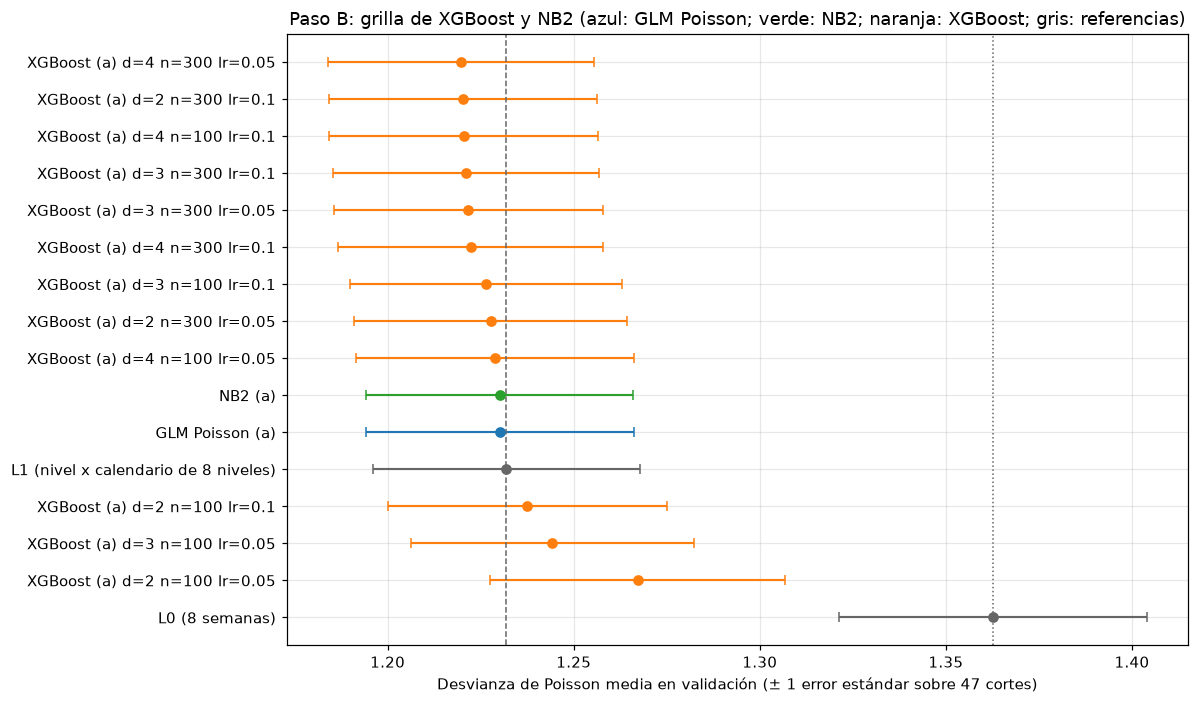

  guardado: experiments\modelos_candidatos\tablas\25_paso_b_predicciones.csv (34216 filas)


,configuracion,corte,origen,fecha,zona_id,n_siniestros,pred
0,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO A,0,2.963655
1,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO B,3,3.374218
2,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO C,4,3.480553
3,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO CH,1,2.096354
4,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO D,3,3.256612
...,...,...,...,...,...,...,...
34211,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO CH,3,2.292051
34212,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO D,6,3.270097
34213,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO E,6,2.241288
34214,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO F,3,2.705660


In [22]:
# fig5: desvianza ± 1 EE de las configuraciones del paso B, con L1 y L0 de 8 semanas
fig, ax = plt.subplots(figsize=(11, 6.5))
t = glob_b.iloc[::-1]
y_pos = pd.Series(range(len(t)), index=t.index)
for fam, color in (("GLM Poisson", "C0"), ("NB2", "C2"), ("XGBoost", "C1"), ("referencia", "0.4")):
    f = t[t["familia"] == fam]
    ax.errorbar(f["desvianza"], y_pos[f.index], xerr=f["error_estandar"], fmt="o", color=color, elinewidth=1.4, capsize=3)
ax.set_yticks(range(len(t)), t["modelo"])
for nombre, ls in ((L1, "--"), ("L0 (8 semanas)", ":")):
    ax.axvline(t.loc[t["modelo"] == nombre, "desvianza"].iloc[0], color="0.4", ls=ls, lw=1)
ax.set_xlabel("Desvianza de Poisson media en validación (± 1 error estándar sobre 47 cortes)")
ax.set_title("Paso B: grilla de XGBoost y NB2 (azul: GLM Poisson; verde: NB2; naranja: XGBoost; gris: referencias)")
fig.tight_layout()
guardar_figura(fig, "fig5_paso_b_desvianza.png")
plt.show()

nuevas_b = [CONFIG_NB2] + CONFIGS_B_XGB                       # GLM Poisson (a) ya está en tablas/17
predicciones_b = pd.concat([PRED_CAND[c].assign(configuracion=c) for c in nuevas_b], ignore_index=True)
predicciones_b["origen"] = predicciones_b["origen"].dt.strftime("%Y-%m-%d")
predicciones_b["fecha"] = predicciones_b["fecha"].dt.strftime("%Y-%m-%d")
guardar_tabla(predicciones_b[["configuracion", "corte", "origen", "fecha", "zona_id", "n_siniestros", "pred"]].round(6),
              "25_paso_b_predicciones.csv")

### 8.1 Lectura del paso B

Cifras de `tablas/18` (globales), `21` (NB2 por corte), `22` (NB2 contra GLM Poisson), `23` (elección) y `24` (ajustes por corte).

**Evidencia**

- **NB2 (a) frente a GLM Poisson (a).** Desvianza 1,2301 contra 1,2302 (diferencia −0,000098; EE 0,0359 en los dos). NB2 gana en 27 de
  47 cortes. Las predicciones difieren como mucho en 0,0071 siniestros (0,18 % relativo). **α por máxima verosimilitud: de 0,0349 a
  0,0400, mediana 0,0377**. Los 47 ajustes convergieron en 4 iteraciones de Newton, sin avisos: **ningún corte usó el plan B**.
- **Familia GLM:** Poisson y NB2 empatan a menos de 1 EE (umbral 1,2660) y **D36 elige GLM Poisson (a)**.
- **Grilla de XGBoost.** Desvianza de 1,2197 (d=4, n=300, lr=0,05) a 1,2671 (d=2, n=100, lr=0,05). Umbral de 1 EE: 1,2555. Quedan
  dentro 11 de las 12 combinaciones; solo d=2, n=100, lr=0,05 queda afuera. Seis combinaciones quedan entre 1,2197 y 1,2223, y las de
  100 árboles con lr=0,05 son las peores de cada profundidad.
- **Familia XGBoost:** **D37 elige d=2, n=100, lr=0,1**, la única empatada con profundidad 2 y 100 árboles. Desvianza 1,2375 (EE
  0,0375). Es la décima de las doce, **queda por encima de L1 (+0,0056)** y le gana en 20 de 47 cortes. El paso 4 (D38) no intervino:
  el paso 3 dejó una sola configuración.
- **Control:** la combinación d=3, n=300, lr=0,05 reprodujo exactamente las predicciones de XGBoost (a) del paso A.
- 611 ajustes (13 configuraciones × 47 cortes), ninguno con avisos y ninguna predicción igual a 0.

**Inferencia**

- En validación, NB2 no cambia la predicción puntual: con α ≈ 0,04 la media estimada es casi la de Poisson. Es lo que la sección 1
  anticipaba: su papel son los intervalos y la inferencia sobre coeficientes, no la desvianza. La sobredispersión es moderada y
  coherente con la dispersión de Pearson del paso A (de 1,10 a 1,12).
- La grilla de XGBoost tiene una meseta: la mitad de las combinaciones queda a menos de 0,003 de la mejor. Entre las que quedan dentro
  de 1 EE, la regla elige la más simple, que **en desvianza media es peor que L1**, aunque esté a menos de 1 EE de ella. Es
  consecuencia directa de la regla fijada (1 EE amplio y simplicidad por D37), no un error del cálculo. El paso C usa esta
  configuración como «la mejor de XGBoost».

## 9. Paso C — ventanas de entrenamiento

Para la configuración elegida de cada familia en el paso B (sección 8; el código la toma de `ELEGIDO_B`): **GLM Poisson (a)** y
**XGBoost (a) d=2 n=100 lr=0.1** (D39), con ventana **expansiva** y **deslizante de 364, 546 y 728 días** (sección 1).

- Ventana deslizante de N días: las filas de entrenamiento son los N días anteriores al origen (`dias_ventana=N` en
  `var.matriz_entrenamiento`). Con el conjunto (a) ninguna variable depende del objetivo, así que la ventana sólo cambia qué días
  entrenan el modelo. Se verifica que cada ajuste usó exactamente N días.
- Las dos configuraciones expansivas se vuelven a evaluar con el nombre del paso C, y se verifica que reproducen exactamente las
  predicciones de los pasos A y B.
- **Regla de selección completa** sobre las 8 configuraciones: 1) desvianza; 2) empate a menos de 1 EE de la mejor; 3) simplicidad,
  sólo por familia (GLM antes que XGBoost; la ventana no cuenta, D40); 4) entre las que siguen empatadas, D38 (peor municipio con
  tolerancia de 1 EE, luego desvío entre cortes, luego |total pred./obs. − 1|). Cada paso queda en `tablas/29`.
- Referencias en las tablas, **fuera de la regla**: L1, L0 de 8 semanas y la mejor combinación de la grilla de XGBoost en desvianza
  (expansiva, del paso B; D39: no se ejecuta en el paso C).
- Columnas informativas, **fuera de la regla**: total predicho / observado global y del municipio A.
- **La configuración que queda elegida no se escribe como final**: la configuración final se fija en la fase 3.

In [23]:
VENTANAS_C = [None, 364, 546, 728]


def nombre_ventana(base, ventana):
    return f"{base} [{'expansiva' if ventana is None else f'deslizante {ventana} d'}]"


CONFIGS_C = []
for base in (ELEGIDO_B["GLM"], ELEGIDO_B["XGBoost"]):
    m = META[base]
    for v in VENTANAS_C:
        CONFIGS_C.append(nombre_ventana(base, v))
        evaluar_configuracion("C", CONFIGS_C[-1], m["modelo"], m["conjunto"], m["N"], m["hiper"], ventana=v)
    # Control: la expansiva reproduce exactamente las predicciones del paso A / B
    assert np.array_equal(PRED_CAND[nombre_ventana(base, None)]["pred"].to_numpy(), PRED_CAND[base]["pred"].to_numpy()), \
        f"la ventana expansiva no reproduce {base}"
    print(f"control: {nombre_ventana(base, None)} reproduce exactamente las predicciones de {base}")

ajustes_c = pd.DataFrame([a for a in AJUSTES if a["configuracion"] in CONFIGS_C])
for c in CONFIGS_C:                                            # cada ajuste deslizante usó exactamente N días
    v = META[c]["ventana"]
    if v is not None:
        assert (ajustes_c.loc[ajustes_c["configuracion"] == c, "dias_entrenamiento"] == v).all(), c
print("ventanas deslizantes: cada ajuste usó exactamente N días de entrenamiento")
ajustes_c["origen"] = ajustes_c["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(ajustes_c.round(6), "30_paso_c_ajustes_por_corte.csv")
print("ajustes con avisos:", int((ajustes_c["n_avisos"] > 0).sum()), "de", len(ajustes_c),
      "| GLM no convergidos:", int((ajustes_c["convergio"] == False).sum()))
registro = escribir_registro()
registro.loc[registro["paso"] == "C", ["configuracion", "ventana", "desvianza", "error_estandar", "total_pred_obs", "peor_municipio",
                                       "cortes_no_convergidos", "cortes_con_avisos"]].round(4)

control: GLM Poisson (a) [expansiva] reproduce exactamente las predicciones de GLM Poisson (a)


control: XGBoost (a) d=2 n=100 lr=0.1 [expansiva] reproduce exactamente las predicciones de XGBoost (a) d=2 n=100 lr=0.1
ventanas deslizantes: cada ajuste usó exactamente N días de entrenamiento
  guardado: experiments\modelos_candidatos\tablas\30_paso_c_ajustes_por_corte.csv (376 filas)
ajustes con avisos: 0 de 376 | GLM no convergidos: 0
  guardado: experiments\modelos_candidatos\registro_experimentos.csv (37 filas)


,configuracion,ventana,desvianza,error_estandar,total_pred_obs,peor_municipio,cortes_no_convergidos,cortes_con_avisos
29,GLM Poisson (a) [expansiva],expansiva,1.2302,0.0359,0.9341,MUNICIPIO E,0.0,0
30,GLM Poisson (a) [deslizante 364 d],deslizante 364 días,1.2205,0.0364,0.9717,MUNICIPIO E,0.0,0
31,GLM Poisson (a) [deslizante 546 d],deslizante 546 días,1.2242,0.0361,0.9588,MUNICIPIO E,0.0,0
32,GLM Poisson (a) [deslizante 728 d],deslizante 728 días,1.2263,0.0360,0.9495,MUNICIPIO E,0.0,0
33,XGBoost (a) d=2 n=100 lr=0.1 [expansiva],expansiva,1.2375,0.0375,0.9336,MUNICIPIO E,NaN,0
34,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],deslizante 364 días,1.2280,0.0377,0.9712,MUNICIPIO E,NaN,0
35,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 546 d],deslizante 546 días,1.2322,0.0378,0.9582,MUNICIPIO E,NaN,0
36,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 728 d],deslizante 728 días,1.2320,0.0377,0.9489,MUNICIPIO C,NaN,0


In [24]:
# Referencias fuera de la regla: L1, L0 de 8 semanas y la mejor de la grilla de XGBoost (D39)
MEJOR_GRILLA = glob_b[glob_b["modelo"].isin(CONFIGS_B_XGB)].sort_values("desvianza")["modelo"].iloc[0]
REF_C = {**REF_COMPARACION, f"{MEJOR_GRILLA} [expansiva] (referencia, D39)": PRED_CAND[MEJOR_GRILLA]}

glob_c = tabla_comparacion(CONFIGS_C, REF_C)
mun_c = tabla_por_municipio(CONFIGS_C, REF_C)
_tot_a = mun_c[mun_c["zona_id"] == "MUNICIPIO A"].set_index("modelo")["total_pred_obs"]
glob_c.insert(glob_c.columns.get_loc("total_pred_obs") + 1, "total_pred_obs_municipio_A", glob_c["modelo"].map(_tot_a))
glob_c.insert(2, "ventana", glob_c["modelo"].map(
    lambda m: ("expansiva" if META[m]["ventana"] is None else f"deslizante {META[m]['ventana']} d") if m in META
    else ("no aplica (rezagos)" if m == "L0 (8 semanas)" else "expansiva")))
guardar_tabla(glob_c.round(6), "26_paso_c_globales.csv")
guardar_tabla(mun_c.round(6), "27_paso_c_por_municipio.csv")
corte_c = tabla_metricas({**{c: PRED_CAND[c] for c in CONFIGS_C}, **REF_C}, "corte")
guardar_tabla(corte_c.round(6), "28_paso_c_por_corte.csv")

glob_c[["modelo", "familia", "ventana", "desvianza", "error_estandar", "total_pred_obs", "total_pred_obs_municipio_A",
        "peor_municipio", "desvianza_peor_municipio", "desvio_entre_cortes", "diferencia_vs_L1", "cortes_que_gana_a_L1",
        "a_menos_de_1_ee_del_mejor_de_la_tabla", "a_menos_de_1_ee_del_mejor_de_su_familia"]].round(4)

  guardado: experiments\modelos_candidatos\tablas\26_paso_c_globales.csv (11 filas)
  guardado: experiments\modelos_candidatos\tablas\27_paso_c_por_municipio.csv (88 filas)


  guardado: experiments\modelos_candidatos\tablas\28_paso_c_por_corte.csv (517 filas)


,modelo,familia,ventana,desvianza,error_estandar,total_pred_obs,total_pred_obs_municipio_A,peor_municipio,desvianza_peor_municipio,desvio_entre_cortes,diferencia_vs_L1,cortes_que_gana_a_L1,a_menos_de_1_ee_del_mejor_de_la_tabla,a_menos_de_1_ee_del_mejor_de_su_familia
0,XGBoost (a) d=4 n=300 lr=0.05 [expansiva] (ref...,referencia,expansiva,1.2197,0.0358,0.9339,0.8679,MUNICIPIO E,1.4002,0.2455,-0.0122,31,True,True
1,GLM Poisson (a) [deslizante 364 d],GLM Poisson,deslizante 364 d,1.2205,0.0364,0.9717,0.9330,MUNICIPIO E,1.4068,0.2495,-0.0114,32,True,True
2,GLM Poisson (a) [deslizante 546 d],GLM Poisson,deslizante 546 d,1.2242,0.0361,0.9588,0.9151,MUNICIPIO E,1.4086,0.2476,-0.0077,31,True,True
3,GLM Poisson (a) [deslizante 728 d],GLM Poisson,deslizante 728 d,1.2263,0.0360,0.9495,0.8939,MUNICIPIO E,1.4042,0.2468,-0.0056,34,True,True
4,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],XGBoost,deslizante 364 d,1.2280,0.0377,0.9712,0.9030,MUNICIPIO E,1.4029,0.2582,-0.0038,26,True,True
5,GLM Poisson (a) [expansiva],GLM Poisson,expansiva,1.2302,0.0359,0.9341,0.8695,MUNICIPIO E,1.4019,0.2464,-0.0017,36,True,True
6,L1 (nivel x calendario de 8 niveles),referencia,expansiva,1.2319,0.0358,0.9305,0.8641,MUNICIPIO E,1.4026,0.2456,0.0000,0,True,True
7,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 728 d],XGBoost,deslizante 728 d,1.2320,0.0377,0.9489,0.8647,MUNICIPIO C,1.4037,0.2582,0.0001,26,True,True
8,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 546 d],XGBoost,deslizante 546 d,1.2322,0.0378,0.9582,0.8855,MUNICIPIO E,1.4044,0.2591,0.0003,25,True,True
9,XGBoost (a) d=2 n=100 lr=0.1 [expansiva],XGBoost,expansiva,1.2375,0.0375,0.9336,0.8378,MUNICIPIO E,1.4024,0.2573,0.0056,20,True,True


In [25]:
# Regla completa sobre las 8 configuraciones del paso C (D40: el paso 3 sólo ordena por familia)
SIMPLICIDAD_FAMILIA = {"GLM Poisson": 0, "NB2": 0, "XGBoost": 1}
ELEGIDA_C, _f = aplicar_regla("paso C, 8 configuraciones", CONFIGS_C, glob_c, mun_c,
                              lambda c: SIMPLICIDAD_FAMILIA[META[c]["modelo"]], "D40: GLM antes que XGBoost; la ventana no cuenta")
eleccion_c = pd.DataFrame(_f)
eleccion_c.insert(eleccion_c.columns.get_loc("total_pred_obs") + 1, "total_pred_obs_municipio_A",
                  eleccion_c["configuracion"].map(_tot_a))                     # informativo: no entra en la regla
guardar_tabla(eleccion_c.round(6), "29_paso_c_eleccion.csv")
print("Configuración que quedaría elegida por la regla (NO es la configuración final; se fija en la fase 3):", ELEGIDA_C)
eleccion_c.round(4)

  guardado: experiments\modelos_candidatos\tablas\29_paso_c_eleccion.csv (25 filas)
Configuración que quedaría elegida por la regla (NO es la configuración final; se fija en la fase 3): GLM Poisson (a) [expansiva]


,seleccion,paso,configuracion,desvianza,error_estandar,peor_municipio,desvianza_peor_municipio,desvio_entre_cortes,total_pred_obs,total_pred_obs_municipio_A,resultado
0,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,GLM Poisson (a) [deslizante 364 d],1.2205,0.0364,MUNICIPIO E,1.4068,0.2495,0.9717,0.9330,mejor; empatada (≤ 1.2569)
1,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,GLM Poisson (a) [deslizante 546 d],1.2242,0.0361,MUNICIPIO E,1.4086,0.2476,0.9588,0.9151,empatada (≤ 1.2569)
2,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,GLM Poisson (a) [deslizante 728 d],1.2263,0.0360,MUNICIPIO E,1.4042,0.2468,0.9495,0.8939,empatada (≤ 1.2569)
3,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],1.2280,0.0377,MUNICIPIO E,1.4029,0.2582,0.9712,0.9030,empatada (≤ 1.2569)
4,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,GLM Poisson (a) [expansiva],1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,0.8695,empatada (≤ 1.2569)
5,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 728 d],1.2320,0.0377,MUNICIPIO C,1.4037,0.2582,0.9489,0.8647,empatada (≤ 1.2569)
6,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 546 d],1.2322,0.0378,MUNICIPIO E,1.4044,0.2591,0.9582,0.8855,empatada (≤ 1.2569)
7,"paso C, 8 configuraciones",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=2 n=100 lr=0.1 [expansiva],1.2375,0.0375,MUNICIPIO E,1.4024,0.2573,0.9336,0.8378,empatada (≤ 1.2569)
8,"paso C, 8 configuraciones",3. simplicidad (D40: GLM antes que XGBoost; la...,GLM Poisson (a) [expansiva],1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,0.8695,más simple
9,"paso C, 8 configuraciones",3. simplicidad (D40: GLM antes que XGBoost; la...,GLM Poisson (a) [deslizante 364 d],1.2205,0.0364,MUNICIPIO E,1.4068,0.2495,0.9717,0.9330,más simple


  guardado: experiments\modelos_candidatos\figuras\fig6_paso_c_ventanas.png


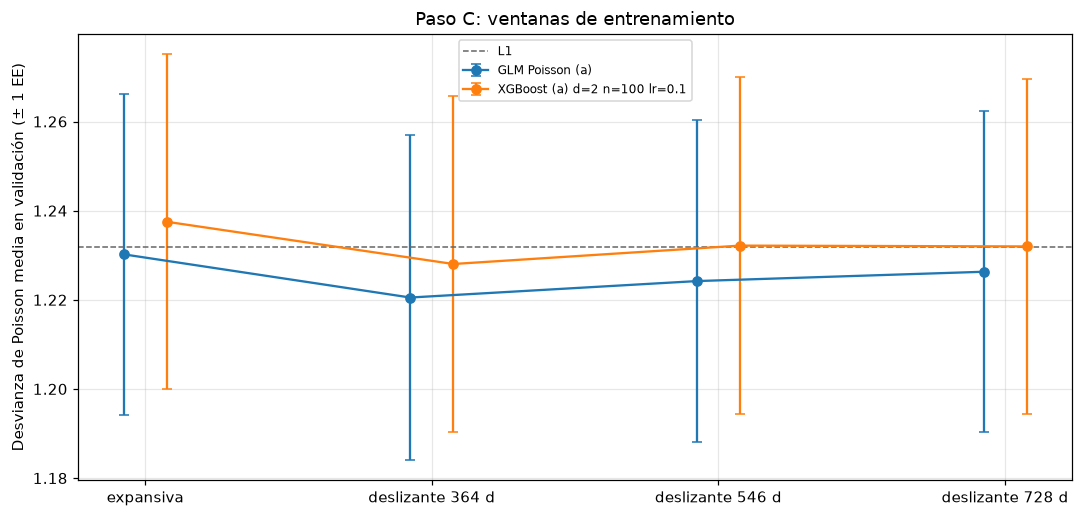

  guardado: experiments\modelos_candidatos\tablas\31_paso_c_predicciones.csv (21056 filas)


,configuracion,corte,origen,fecha,zona_id,n_siniestros,pred
0,GLM Poisson (a) [expansiva],1,2024-03-14,2024-03-14,MUNICIPIO A,0,2.960619
1,GLM Poisson (a) [expansiva],1,2024-03-14,2024-03-14,MUNICIPIO B,3,3.373212
2,GLM Poisson (a) [expansiva],1,2024-03-14,2024-03-14,MUNICIPIO C,4,3.483081
3,GLM Poisson (a) [expansiva],1,2024-03-14,2024-03-14,MUNICIPIO CH,1,2.096862
4,GLM Poisson (a) [expansiva],1,2024-03-14,2024-03-14,MUNICIPIO D,3,3.253993
...,...,...,...,...,...,...,...
21051,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 728 d],47,2025-01-30,2025-02-05,MUNICIPIO CH,3,2.366506
21052,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 728 d],47,2025-01-30,2025-02-05,MUNICIPIO D,6,3.204241
21053,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 728 d],47,2025-01-30,2025-02-05,MUNICIPIO E,6,2.382522
21054,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 728 d],47,2025-01-30,2025-02-05,MUNICIPIO F,3,3.102680


In [26]:
# fig6: desvianza ± 1 EE por ventana, para las dos familias, con L1 como referencia
fig, ax = plt.subplots(figsize=(10, 4.8))
etiquetas = ["expansiva" if v is None else f"deslizante {v} d" for v in VENTANAS_C]
for k, (base, color) in enumerate(((ELEGIDO_B["GLM"], "C0"), (ELEGIDO_B["XGBoost"], "C1"))):
    t = glob_c.set_index("modelo").loc[[nombre_ventana(base, v) for v in VENTANAS_C]]
    x = np.arange(len(VENTANAS_C)) + (k - 0.5) * 0.15
    ax.errorbar(x, t["desvianza"], yerr=t["error_estandar"], fmt="o-", color=color, capsize=3, label=base)
ax.axhline(glob_c.loc[glob_c["modelo"] == L1, "desvianza"].iloc[0], color="0.4", ls="--", lw=1, label="L1")
ax.set_xticks(range(len(VENTANAS_C)), etiquetas)
ax.set_ylabel("Desvianza de Poisson media en validación (± 1 EE)")
ax.set_title("Paso C: ventanas de entrenamiento")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "fig6_paso_c_ventanas.png")
plt.show()

predicciones_c = pd.concat([PRED_CAND[c].assign(configuracion=c) for c in CONFIGS_C], ignore_index=True)
predicciones_c["origen"] = predicciones_c["origen"].dt.strftime("%Y-%m-%d")
predicciones_c["fecha"] = predicciones_c["fecha"].dt.strftime("%Y-%m-%d")
guardar_tabla(predicciones_c[["configuracion", "corte", "origen", "fecha", "zona_id", "n_siniestros", "pred"]].round(6),
              "31_paso_c_predicciones.csv")

### 9.1 Lectura del paso C

Cifras de `tablas/26` (globales), `27` (por municipio), `28` (por corte), `29` (regla, paso por paso) y `30` (ajustes por corte).
**La configuración que queda elegida no es la configuración final**: la fase 3 la fija.

**Evidencia — la regla, paso por paso**

1. **Desvianza:** la mejor de las 8 es **GLM Poisson (a), deslizante 364 d** (1,2205; EE 0,0364).
2. **Empate a menos de 1 EE** (umbral 1,2569): **las 8 configuraciones empatan**. La peor es XGBoost expansiva, con 1,2375.
3. **Simplicidad (D40):** pasan las 4 ventanas del GLM; las 4 de XGBoost quedan afuera por familia.
4. **D38:**
   - **Peor municipio:** E en las cuatro. La mejor es la expansiva (1,4019) y su EE en E es 0,0919, así que el umbral queda en 1,4939
     y **pasan las cuatro** (de 1,4019 a 1,4086).
   - **Desvío entre cortes:** gana la **expansiva**: 0,246353 contra 0,246801 (728 d), 0,247608 (546 d) y 0,249505 (364 d). La
     diferencia con la segunda es de 0,00045.
   - El paso de calibración no hizo falta.

**Configuración que quedaría elegida: GLM Poisson (a), ventana expansiva** (1,2302; total pred./obs. 0,9341; en A, 0,8695).

**Evidencia — lo demás**

- **Calibración según la ventana (informativa, fuera de la regla).** En el GLM, el total predicho / observado se acerca a 1 a medida
  que la ventana se acorta: expansiva 0,9341, 728 d 0,9495, 546 d 0,9588, 364 d 0,9717. En A, 0,8695, 0,8939, 0,9151 y 0,9330. En
  XGBoost pasa lo mismo: 0,9336, 0,9489, 0,9582 y 0,9712.
- **Desvianza según la ventana.** En el GLM, todas las deslizantes mejoran a la expansiva: 1,2205 (364 d), 1,2242 (546 d) y 1,2263
  (728 d), contra 1,2302. La de 364 d le gana a la expansiva en 30 de 47 cortes. En XGBoost también mejoran: 1,2280, 1,2322 y 1,2320,
  contra 1,2375.
- **Referencias.** L1 1,2319. La mejor combinación de la grilla de XGBoost (d=4 n=300 lr=0,05, expansiva, sin ejecutar en el paso C,
  D39) tiene la menor desvianza de la tabla, 1,2197.
- 376 ajustes (8 configuraciones × 47 cortes), sin avisos; los GLM convergieron. Cada ajuste deslizante usó exactamente N días. Las dos
  expansivas reprodujeron exactamente las predicciones de los pasos A y B.

**Inferencia**

- Las ventanas cortas siguen mejor el nivel creciente (la tendencia), y por eso calibran mejor. La regla fijada no las elige: en el paso
  4, D38 compara primero la estabilidad y deja la calibración al final. La estabilidad la decide una diferencia de desvío entre cortes de
  0,00045, unas 80 veces menor que el EE de la desvianza (≈ 0,036). **La elección de la ventana expansiva es, en la práctica, un empate que el criterio
  de desvío resuelve por un margen despreciable**, y la deslizante de 364 d es mejor en desvianza media y en calibración.
- La regla está fijada y se aplicó como está. Qué configuración se adopta lo decide la fase 3.

## 10. Fase 3, paso 3a — configuración de la solución (D42)

Sin ajustes nuevos: esta sección toma lo ya evaluado en el paso C (`META`, `glob_c`, `eleccion_c`) y escribe:

- `solucion_seleccionada.json`: la configuración final (D42), la de la regla, la de sensibilidad y la de contraste, con el EPS de la
  desvianza, la semilla, las versiones de las bibliotecas (`tablas/00`) y el commit del repositorio en el momento de la ejecución.
- `tablas/32_fase3_configuracion_final.csv`: la regla paso por paso y, en una fila aparte, la decisión D42 con su motivo.

**El JSON quedó fijado en el commit `1560a5b` y no se reescribe (F3-B2):** si ya existe, la celda vuelve a calcular su contenido,
verifica con `assert` que todos los campos salvo los de procedencia (commit y estado del árbol de trabajo) coinciden, y lo deja intacto.

Las cifras que se copian al JSON salen de las mismas tablas que cita el bloque D42; los `assert` comprueban que la regla sigue eligiendo
la expansiva y que la configuración final es la de 364 días que evaluó el paso C.

In [27]:
import subprocess

SOLUCION = nombre_ventana(ELEGIDO_B["GLM"], 364)                    # D42
REGLA = ELEGIDA_C                                                   # lo que eligió la regla (sección 9)
CONTRASTE = (glob_c[glob_c["modelo"].isin(CONFIGS_C) & (glob_c["familia"] == "XGBoost")]
             .sort_values("desvianza")["modelo"].iloc[0])           # la mejor XGBoost del paso C
assert REGLA == nombre_ventana(ELEGIDO_B["GLM"], None), REGLA
assert SOLUCION in META and META[SOLUCION]["ventana"] == 364 and META[SOLUCION]["conjunto"] == "a"
assert CONTRASTE == nombre_ventana(ELEGIDO_B["XGBoost"], 364), CONTRASTE
assert all(b - a == pd.Timedelta(days=PASO) for a, b in zip(ORIGENES, ORIGENES[1:]))


def describir(nombre):
    "Configuración completa de un modelo evaluado en el paso C, con sus cifras de validación (tablas/26)."
    m, g = META[nombre], glob_c.set_index("modelo").loc[nombre]
    cols = columnas_conjunto(m["conjunto"], m["N"])
    if m["modelo"] == "GLM Poisson":
        modelo = {"modelo": "GLM", "familia": "Poisson", "enlace": "log",
                  "implementacion": "statsmodels.api.GLM(y, X, family=sm.families.Poisson()).fit()",
                  "hiperparametros": {"ajuste": "IRLS, valores por defecto de statsmodels", "regularizacion": None,
                                      "constante": "no (8 indicadoras de municipio, D31)"}}
    else:
        modelo = {"modelo": "XGBoost", "familia": "Poisson (objective='count:poisson')",
                  "implementacion": "xgboost.XGBRegressor(**hiperparametros).fit(X, y)",
                  "hiperparametros": {**XGB_FIJOS, **m["hiper"]}}
    return {
        "configuracion": nombre, **modelo,
        "conjunto_de_variables": {"conjunto": m["conjunto"], "descripcion": "municipio + calendario de 8 niveles",
                                  "columnas": cols, "parametrizacion": "D31: 8 indicadoras de municipio sin constante; "
                                  "calendario con 7 columnas, lunes de referencia", "fuente": "src/variables.py"},
        "ventana": ({"tipo": "expansiva", "dias": None} if m["ventana"] is None
                    else {"tipo": "deslizante", "dias": int(m["ventana"])}),
        "reentrenamiento_cada_dias": PASO, "horizonte_dias": HORIZONTE,
        "validacion_47_cortes": {"desvianza_media": round(float(g["desvianza"]), 6),
                                 "error_estandar": round(float(g["error_estandar"]), 6),
                                 "desvio_entre_cortes": round(float(g["desvio_entre_cortes"]), 6),
                                 "total_pred_obs": round(float(g["total_pred_obs"]), 6),
                                 "total_pred_obs_municipio_A": round(float(g["total_pred_obs_municipio_A"]), 6),
                                 "fuente": "tablas/26_paso_c_globales.csv"},
    }


def git(*args):
    return subprocess.run(["git", *args], cwd=RAIZ, capture_output=True, text=True, check=True).stdout.strip()


solucion = {
    "fecha_decision": "2026-10-19",
    "decision": "D42",
    "origen_de_la_eleccion": "decisión del equipo D42, apartándose de la regla",
    "solucion": describir(SOLUCION),
    "configuracion_de_la_regla": describir(REGLA),
    "sensibilidad": {**describir(REGLA), "papel": "se evalúa en la fase 4 junto con las referencias; no compite y no puede "
                                                  "reemplazar a la configuración final"},
    "contraste": {**describir(CONTRASTE), "papel": "se evalúa en la fase 4 junto con las referencias; no compite"},
    "eps_desvianza": EPS,
    "semilla": SEMILLA,
    "versiones": dict(zip(entorno["componente"], entorno["version"])),
    "commit_del_repositorio": git("rev-parse", "HEAD"),
    "arbol_de_trabajo_con_cambios_sin_commitear": bool(git("status", "--porcelain")),
    "bloque_final_leido": False,
}
RUTA_SOLUCION = DIR_EXPERIMENTO / "solucion_seleccionada.json"
# El JSON quedó fijado en el commit 1560a5b y no se reescribe (F3-B2): si ya existe, se verifica contra lo calculado y se deja
# intacto. Los campos de procedencia (commit y estado del árbol) son los de la ejecución que lo escribió; por eso no se comparan.
PROCEDENCIA = ("commit_del_repositorio", "arbol_de_trabajo_con_cambios_sin_commitear")
if RUTA_SOLUCION.exists():
    fijado = json.loads(RUTA_SOLUCION.read_text(encoding="utf-8"))
    calculado = json.loads(json.dumps(solucion, ensure_ascii=False))
    distintos = sorted(k for k in (set(fijado) | set(calculado)) - set(PROCEDENCIA) if fijado.get(k) != calculado.get(k))
    assert not distintos, f"solucion_seleccionada.json no coincide con lo calculado en: {distintos}"
    print("  verificado, sin reescribir:", RUTA_SOLUCION.relative_to(RAIZ), "| commit fijado:", fijado["commit_del_repositorio"][:7])
else:
    RUTA_SOLUCION.write_text(json.dumps(solucion, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print("  guardado:", RUTA_SOLUCION.relative_to(RAIZ))

# --- Tabla: la regla paso por paso y, aparte, la decisión D42 ---
g, e = glob_c.set_index("modelo"), eleccion_c
GLM_C = [c for c in CONFIGS_C if META[c]["modelo"] == "GLM Poisson"]
emp = e[e["paso"].str.startswith("1-2") & e["resultado"].str.contains("empatada")]["configuracion"].tolist()
umbral = g.loc[e["configuracion"].iloc[0], "desvianza"] + g.loc[e["configuracion"].iloc[0], "error_estandar"]
pm = e[e["paso"].str.startswith("4a")]
estab = sorted(GLM_C, key=lambda c: g.loc[c, "desvio_entre_cortes"])
pc = corte_c.pivot(index="corte", columns="modelo", values="desvianza_poisson")
gana = int((pc[SOLUCION] < pc[REGLA]).sum())
f = lambda x: f"{x:.4f}".replace(".", ",")
f6 = lambda x: f"{x:.6f}".replace(".", ",")
filas = [
    ("1. desvianza media", f"mejor: {e['configuracion'].iloc[0]} ({f(g.loc[e['configuracion'].iloc[0], 'desvianza'])}; "
     f"EE {f(g.loc[e['configuracion'].iloc[0], 'error_estandar'])})", "tablas/26, tablas/29"),
    ("2. empate a menos de 1 EE", f"{len(emp)} de {len(CONFIGS_C)} empatan (umbral {f(umbral)})", "tablas/29"),
    ("3. simplicidad (D40)", f"pasan las {len(GLM_C)} ventanas del GLM; XGBoost queda afuera por familia", "tablas/29"),
    ("4a. estabilidad: peor municipio (D38)", f"pasan {int(pm['resultado'].str.contains('pasa').sum())} de {len(pm)} "
     f"({pm['resultado'].iloc[0].split('(')[-1].rstrip(')').replace('.', ',')})", "tablas/27, tablas/29"),
    ("4b. estabilidad: desvío entre cortes (D38)", "; ".join(f"{c.split('[')[-1].rstrip(']')} {f6(g.loc[c, 'desvio_entre_cortes'])}"
     for c in estab) + f" — diferencia con la segunda {g.loc[estab[1], 'desvio_entre_cortes'] - g.loc[estab[0], 'desvio_entre_cortes']:.5f}"
     .replace(".", ","), "tablas/29"),
    ("4c. calibración (D38)", "no se aplicó: 4b dejó una sola", "tablas/29"),
    ("configuración elegida por la regla", REGLA, "tablas/29"),
    ("DECISIÓN D42 (del equipo, apartándose de la regla)",
     f"{SOLUCION}. Motivo: desvianza media {f(g.loc[SOLUCION, 'desvianza'])} contra {f(g.loc[REGLA, 'desvianza'])}; "
     f"gana {gana} de {len(pc)} cortes; total pred./obs. {f(g.loc[SOLUCION, 'total_pred_obs'])} contra "
     f"{f(g.loc[REGLA, 'total_pred_obs'])} (en A, {f(g.loc[SOLUCION, 'total_pred_obs_municipio_A'])} contra "
     f"{f(g.loc[REGLA, 'total_pred_obs_municipio_A'])}). La expansiva queda como sensibilidad; contraste: {CONTRASTE}",
     "tablas/26, tablas/28"),
]
assert estab[0] == REGLA and gana == 30
config_final = pd.DataFrame(filas, columns=["paso", "resultado", "fuente"])
guardar_tabla(config_final, "32_fase3_configuracion_final.csv")
with pd.option_context("display.max_colwidth", None):
    display(config_final)

  verificado, sin reescribir: experiments\modelos_candidatos\solucion_seleccionada.json | commit fijado: 5f207e2
  guardado: experiments\modelos_candidatos\tablas\32_fase3_configuracion_final.csv (8 filas)


,paso,resultado,fuente
0,1. desvianza media,"mejor: GLM Poisson (a) [deslizante 364 d] (1,2205; EE 0,0364)","tablas/26, tablas/29"
1,2. empate a menos de 1 EE,"8 de 8 empatan (umbral 1,2569)",tablas/29
2,3. simplicidad (D40),pasan las 4 ventanas del GLM; XGBoost queda afuera por familia,tablas/29
3,4a. estabilidad: peor municipio (D38),"pasan 4 de 4 (≤ 1,4939)","tablas/27, tablas/29"
4,4b. estabilidad: desvío entre cortes (D38),"expansiva 0,246353; deslizante 728 d 0,246801; deslizante 546 d 0,247608; deslizante 364 d 0,249505 — diferencia con la segunda 0,00045",tablas/29
5,4c. calibración (D38),no se aplicó: 4b dejó una sola,tablas/29
6,configuración elegida por la regla,GLM Poisson (a) [expansiva],tablas/29
7,"DECISIÓN D42 (del equipo, apartándose de la regla)","GLM Poisson (a) [deslizante 364 d]. Motivo: desvianza media 1,2205 contra 1,2302; gana 30 de 47 cortes; total pred./obs. 0,9717 contra 0,9341 (en A, 0,9330 contra 0,8695). La expansiva queda como sensibilidad; contraste: XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d]","tablas/26, tablas/28"


## 11. Fase 3, paso 3b — explicabilidad (con datos de validación)

El bloque final no se lee: todo sale del panel de desarrollo y de los 47 cortes de validación.

- **Coeficientes** (D45): GLM Poisson (a) ajustado con los últimos 364 días del desarrollo (2024-02-08 → 2025-02-05), expresados como
  razones de tasas con IC95 de Wald. Como complemento (sección 1: el papel declarado de la binomial negativa incluye la inferencia sobre
  coeficientes) se reporta también el IC95 de NB2 ajustada con las mismas filas.
- **Importancia por permutación por grupos** (municipio: 8 columnas; calendario: 7 columnas; el conjunto (a) no tiene otros). En cada corte
  se usa el modelo de ese corte, se permutan juntas las columnas del grupo entre las 56 filas del horizonte y se recalcula la desvianza de
  las 2.632 predicciones. 5 repeticiones con `np.random.default_rng(SEMILLA)`. Para la solución y para el contraste.
- **Dependencia parcial del contraste** (XGBoost) para los dos grupos más importantes: en cada corte se fija el nivel del grupo en las 56
  filas del horizonte y se promedia la predicción; luego se promedia entre cortes. El GLM se calcula igual, como comparación.
- Antes de usar los modelos de cada corte, se verifica que reproducen las predicciones del paso C.

In [28]:
from scipy import stats

ORIGEN_FINAL = ULTIMO + pd.Timedelta(days=1)          # sólo se usan fechas < ORIGEN_FINAL, es decir, el desarrollo
assert panel["fecha"].max() == ULTIMO                  # el panel no tiene ninguna fecha del bloque final
COLS_A = columnas_conjunto("a")
ent_fin = disenio(var.matriz_entrenamiento(panel, ORIGEN_FINAL, dias_ventana=364))
assert ent_fin["fecha"].nunique() == 364 and ent_fin["fecha"].max() == ULTIMO
X_fin, y_fin = ent_fin[COLS_A], ent_fin["n_siniestros"]
glm_fin, av_glm = con_avisos(lambda: sm.GLM(y_fin, X_fin, family=sm.families.Poisson()).fit())
nb2_fin, av_nb2 = con_avisos(lambda: NegativeBinomial(y_fin, X_fin, loglike_method="nb2").fit(method="newton", maxiter=100, disp=0))
alpha_fin = float(nb2_fin.params["alpha"])
assert glm_fin.converged and not av_glm, av_glm
assert nb2_fin.mle_retvals["converged"] and not any(a.startswith("ConvergenceWarning") for a in av_nb2) and alpha_fin > 0, av_nb2

ajuste_fin = pd.DataFrame([{
    "desde": str(ent_fin["fecha"].min().date()), "hasta": str(ent_fin["fecha"].max().date()),
    "dias": ent_fin["fecha"].nunique(), "filas": len(ent_fin),
    "glm_convergio": bool(glm_fin.converged), "glm_iteraciones": glm_fin.fit_history["iteration"],
    "dispersion_pearson": glm_fin.pearson_chi2 / glm_fin.df_resid,
    "nb2_convergio": bool(nb2_fin.mle_retvals["converged"]), "nb2_iteraciones": nb2_fin.mle_retvals["iterations"],
    "alpha_nb2": alpha_fin, "avisos": len(av_glm) + len(av_nb2),
}])
guardar_tabla(ajuste_fin.round(6), "33_fase3b_ajuste_ultimos_364_dias.csv")

Z95 = stats.norm.ppf(0.975)
V, VN = glm_fin.cov_params(), nb2_fin.cov_params().loc[COLS_A, COLS_A]


def fila_coef(termino, tipo, w):
    "w: vector de contraste sobre COLS_A. Estimación, EE e IC95 de Wald en escala de razón (Poisson y NB2)."
    w = pd.Series(w, index=COLS_A, dtype=float)
    est, ee = float(w @ glm_fin.params[COLS_A]), float(np.sqrt(w @ V @ w))
    est_n, ee_n = float(w @ nb2_fin.params[COLS_A]), float(np.sqrt(w @ VN @ w))
    return {"tipo": tipo, "termino": termino, "coeficiente": est, "error_estandar": ee,
            "razon": np.exp(est), "ic95_inferior": np.exp(est - Z95 * ee), "ic95_superior": np.exp(est + Z95 * ee),
            "razon_nb2": np.exp(est_n), "ic95_inferior_nb2": np.exp(est_n - Z95 * ee_n), "ic95_superior_nb2": np.exp(est_n + Z95 * ee_n)}


def unitario(c):
    return [1.0 if k == c else 0.0 for k in COLS_A]


filas = [fila_coef(z, "municipio: siniestros esperados un lunes", unitario(c)) for z, c in zip(MUNICIPIOS, MUN_COLS)]
filas += [fila_coef(z, "municipio: razón respecto de A", np.subtract(unitario(c), unitario("mun_A")))
          for z, c in zip(MUNICIPIOS, MUN_COLS) if c != "mun_A"]
filas += [fila_coef(c.removeprefix("cal_"), "calendario: razón respecto del lunes", unitario(c)) for c in CAL_COLS]
coeficientes = pd.DataFrame(filas)
guardar_tabla(coeficientes.round(6), "34_fase3b_coeficientes_glm.csv")
print(ajuste_fin.round(4).to_string(index=False))
coeficientes[["tipo", "termino", "razon", "ic95_inferior", "ic95_superior", "ic95_inferior_nb2", "ic95_superior_nb2"]].round(4)

  guardado: experiments\modelos_candidatos\tablas\33_fase3b_ajuste_ultimos_364_dias.csv (1 filas)
  guardado: experiments\modelos_candidatos\tablas\34_fase3b_coeficientes_glm.csv (22 filas)
     desde      hasta  dias  filas  glm_convergio  glm_iteraciones  dispersion_pearson  nb2_convergio  nb2_iteraciones  alpha_nb2  avisos
2024-02-08 2025-02-05   364   2912           True                5              1.1006           True                5     0.0297       0


,tipo,termino,razon,ic95_inferior,ic95_superior,ic95_inferior_nb2,ic95_superior_nb2
0,municipio: siniestros esperados un lunes,MUNICIPIO A,3.5056,3.2437,3.7885,3.2373,3.8096
1,municipio: siniestros esperados un lunes,MUNICIPIO B,3.4673,3.2076,3.7480,3.1956,3.7617
2,municipio: siniestros esperados un lunes,MUNICIPIO C,3.9415,3.6557,4.2498,3.6405,4.2639
3,municipio: siniestros esperados un lunes,MUNICIPIO CH,2.1446,1.9603,2.3462,1.9541,2.3535
4,municipio: siniestros esperados un lunes,MUNICIPIO D,3.4820,3.2215,3.7636,3.2117,3.7799
5,municipio: siniestros esperados un lunes,MUNICIPIO E,2.4215,2.2210,2.6401,2.2133,2.6484
6,municipio: siniestros esperados un lunes,MUNICIPIO F,3.0431,2.8071,3.2989,2.7997,3.3136
7,municipio: siniestros esperados un lunes,MUNICIPIO G,2.5570,2.3487,2.7838,2.3416,2.7944
8,municipio: razón respecto de A,MUNICIPIO B,0.9891,0.9125,1.0721,0.9073,1.0743
9,municipio: razón respecto de A,MUNICIPIO C,1.1244,1.0399,1.2157,1.0335,1.2179


  guardado: experiments\modelos_candidatos\figuras\fig7_coeficientes_glm.png


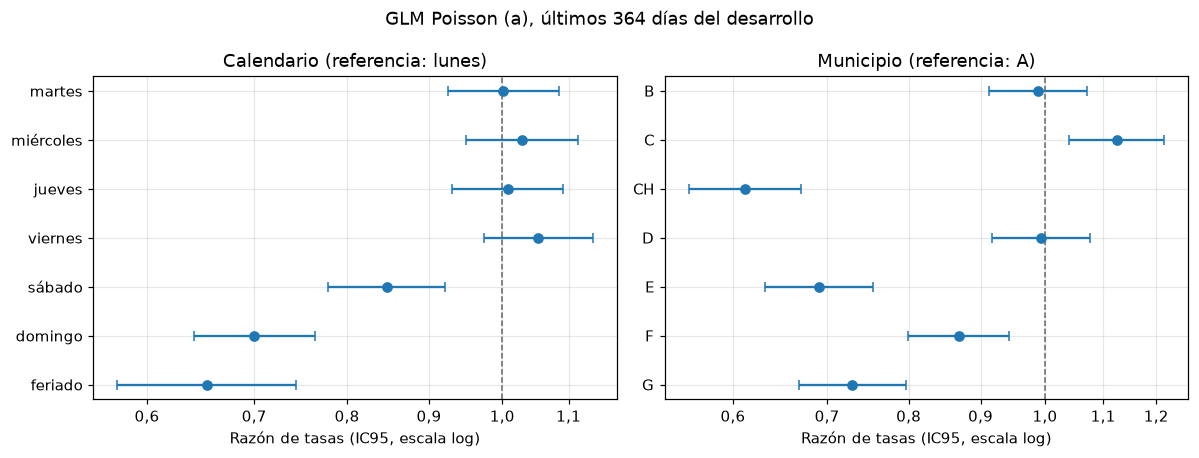

In [29]:
# fig7: razones de tasas con IC95 (Poisson): calendario respecto del lunes y municipios respecto de A
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, tipo, titulo in ((axes[0], "calendario: razón respecto del lunes", "Calendario (referencia: lunes)"),
                         (axes[1], "municipio: razón respecto de A", "Municipio (referencia: A)")):
    t = coeficientes[coeficientes["tipo"] == tipo].reset_index(drop=True)
    yy = np.arange(len(t))[::-1]
    ax.errorbar(t["razon"], yy, xerr=[t["razon"] - t["ic95_inferior"], t["ic95_superior"] - t["razon"]],
                fmt="o", color="C0", capsize=3)
    ax.axvline(1, color="0.4", ls="--", lw=1)
    ax.set_yticks(yy, t["termino"].str.replace("MUNICIPIO ", ""))
    ax.set_xscale("log")
    marcas = [m for m in (0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3)
              if t["ic95_inferior"].min() * 0.95 <= m <= t["ic95_superior"].max() * 1.05]
    ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator(marcas))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
    ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.set_xlabel("Razón de tasas (IC95, escala log)")
    ax.set_title(titulo)
fig.suptitle("GLM Poisson (a), últimos 364 días del desarrollo")
fig.tight_layout()
guardar_figura(fig, "fig7_coeficientes_glm.png")
plt.show()

control: los 47 modelos de GLM Poisson (a) [deslizante 364 d] reproducen las predicciones del paso C (diferencia máxima 0.0e+00)


control: los 47 modelos de XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d] reproducen las predicciones del paso C (diferencia máxima 0.0e+00)


  guardado: experiments\modelos_candidatos\tablas\35_fase3b_permutacion_repeticiones.csv (20 filas)
  guardado: experiments\modelos_candidatos\tablas\36_fase3b_importancia_permutacion.csv (4 filas)


  guardado: experiments\modelos_candidatos\figuras\fig8_importancia_permutacion.png


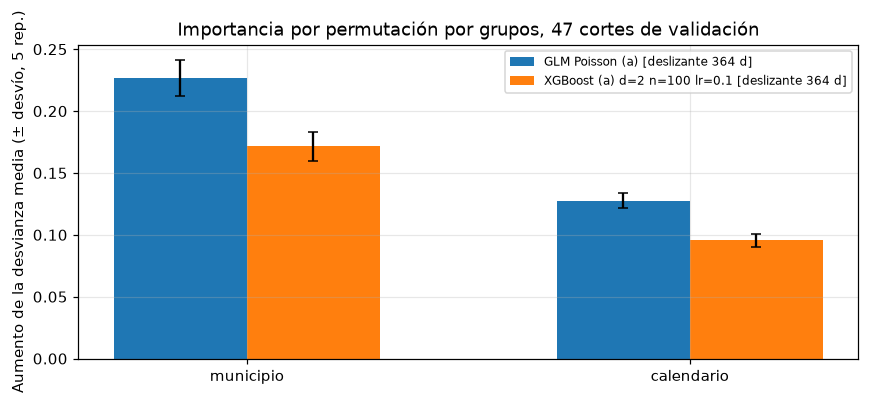

,configuracion,grupo,desvianza_base,aumento_medio,aumento_desvio,aumento_minimo,aumento_maximo,repeticiones,aumento_medio_relativo
0,GLM Poisson (a) [deslizante 364 d],municipio,1.2205,0.2270,0.0145,0.2095,0.2420,5,0.1860
1,GLM Poisson (a) [deslizante 364 d],calendario,1.2205,0.1277,0.0058,0.1197,0.1346,5,0.1046
2,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,1.2280,0.1717,0.0118,0.1559,0.1866,5,0.1398
3,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],calendario,1.2280,0.0955,0.0052,0.0882,0.1021,5,0.0778


In [30]:
SOLUCION_NB2 = nombre_ventana("NB2 (a)", 364)          # para los intervalos (sección 12, D44)


def ajustar_corte(config, corte, origen):
    "Reajusta el modelo de `config` en el corte, por el mismo camino que el motor; devuelve el predictor y las filas del horizonte."
    m = META[config]
    cols = columnas_conjunto(m["conjunto"], m["N"])
    fin = origen + pd.Timedelta(days=HORIZONTE)
    vista = panel[panel["fecha"] < fin].copy()
    vista.loc[vista["fecha"] >= origen, "n_siniestros"] = np.nan
    ent, hor = matrices(vista, origen, m["ventana"])
    if m["modelo"] == "GLM Poisson":
        mod = sm.GLM(ent["n_siniestros"], ent[cols], family=sm.families.Poisson()).fit()
    else:
        mod = xgboost.XGBRegressor(**XGB_FIJOS, **m["hiper"]).fit(ent[cols], ent["n_siniestros"])
    real = panel[(panel["fecha"] >= origen) & (panel["fecha"] < fin)][["fecha", "zona_id", "n_siniestros"]]
    h = hor[["fecha", "zona_id"] + cols].merge(real, on=["fecha", "zona_id"], how="left", validate="one_to_one")
    h.insert(0, "corte", corte)
    return (lambda Z: np.asarray(mod.predict(Z[cols]), dtype=float)), h


FITS = {}
for config in (SOLUCION, CONTRASTE):
    FITS[config] = [ajustar_corte(config, k, o) for k, o in enumerate(ORIGENES, start=1)]
    rep = pd.concat([h[["corte", "fecha", "zona_id"]].assign(pred=f(h)) for f, h in FITS[config]], ignore_index=True)
    chk = PRED_CAND[config].merge(rep, on=["corte", "fecha", "zona_id"], suffixes=("", "_rep"), validate="one_to_one")
    assert len(chk) == 2632 and np.abs(chk["pred"] - chk["pred_rep"]).max() < 1e-9, config
    print(f"control: los 47 modelos de {config} reproducen las predicciones del paso C "
          f"(diferencia máxima {np.abs(chk['pred'] - chk['pred_rep']).max():.1e})")

GRUPOS = {"municipio": MUN_COLS, "calendario": CAL_COLS}
REPETICIONES = 5
rng_perm = np.random.default_rng(SEMILLA)
filas = []
for config in (SOLUCION, CONTRASTE):
    y_todo = np.concatenate([h["n_siniestros"].to_numpy() for _, h in FITS[config]])
    d_base = evaluar(y_todo, np.concatenate([f(h) for f, h in FITS[config]]))["desvianza_poisson"]
    for grupo, cols in GRUPOS.items():
        for r in range(1, REPETICIONES + 1):
            preds = []
            for f, h in FITS[config]:
                Z = h.copy()
                Z[cols] = Z[cols].to_numpy()[rng_perm.permutation(len(Z))]      # mismas filas permutadas para todo el grupo
                preds.append(f(Z))
            d = evaluar(y_todo, np.concatenate(preds))["desvianza_poisson"]
            filas.append({"configuracion": config, "grupo": grupo, "repeticion": r, "desvianza_base": d_base,
                          "desvianza_permutada": d, "aumento": d - d_base})
perm_rep = pd.DataFrame(filas)
guardar_tabla(perm_rep.round(6), "35_fase3b_permutacion_repeticiones.csv")
perm = (perm_rep.groupby(["configuracion", "grupo"], sort=False)
        .agg(desvianza_base=("desvianza_base", "first"), aumento_medio=("aumento", "mean"),
             aumento_desvio=("aumento", lambda s: s.std(ddof=1)), aumento_minimo=("aumento", "min"),
             aumento_maximo=("aumento", "max"), repeticiones=("aumento", "size")).reset_index())
perm["aumento_medio_relativo"] = perm["aumento_medio"] / perm["desvianza_base"]
guardar_tabla(perm.round(6), "36_fase3b_importancia_permutacion.csv")

fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (config, color) in enumerate(((SOLUCION, "C0"), (CONTRASTE, "C1"))):
    t = perm[perm["configuracion"] == config]
    x = np.arange(len(GRUPOS)) + (k - 0.5) * 0.3
    ax.bar(x, t["aumento_medio"], width=0.3, color=color, yerr=t["aumento_desvio"], capsize=3, label=config)
ax.set_xticks(range(len(GRUPOS)), list(GRUPOS))
ax.set_ylabel("Aumento de la desvianza media (± desvío, 5 rep.)")
ax.set_title("Importancia por permutación por grupos, 47 cortes de validación")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "fig8_importancia_permutacion.png")
plt.show()
perm.round(4)

  guardado: experiments\modelos_candidatos\tablas\37_fase3b_dependencia_parcial.csv (32 filas)


  guardado: experiments\modelos_candidatos\figuras\fig9_dependencia_parcial.png


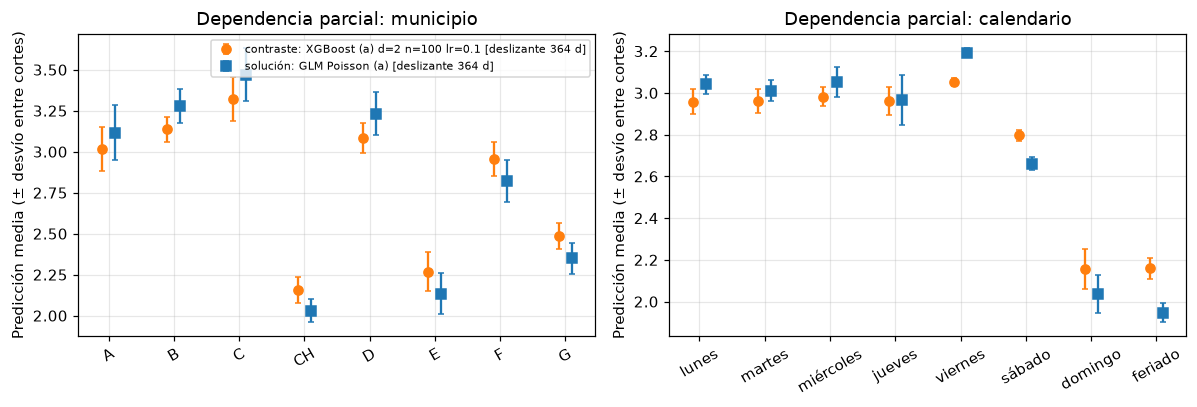

,configuracion,grupo,nivel,prediccion_media,desvio_entre_cortes,minimo_corte,maximo_corte
0,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO A,3.0163,0.1333,2.5836,3.2247
1,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO B,3.1361,0.0770,2.8616,3.2516
2,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO C,3.3210,0.1331,2.8903,3.5399
3,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO CH,2.1562,0.0789,1.7761,2.2240
4,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO D,3.0843,0.0898,2.7075,3.2108
5,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO E,2.2666,0.1191,1.9127,2.4164
6,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO F,2.9570,0.1048,2.5405,3.0567
7,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],municipio,MUNICIPIO G,2.4853,0.0806,2.1296,2.5679
8,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],calendario,lunes,2.9577,0.0589,2.8487,3.0619
9,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],calendario,martes,2.9620,0.0571,2.8526,3.0619


In [31]:
# Dependencia parcial por grupo: en cada corte se fija el nivel del grupo en las 56 filas del horizonte y se promedia la predicción
NIVELES_GRUPO = {"municipio": [(z, c) for z, c in zip(MUNICIPIOS, MUN_COLS)],
                 "calendario": [("lunes", None)] + [(c.removeprefix("cal_"), c) for c in CAL_COLS]}
DOS_MAS_IMPORTANTES = (perm[perm["configuracion"] == CONTRASTE].sort_values("aumento_medio", ascending=False)["grupo"]
                       .head(2).tolist())
filas = []
for config in (CONTRASTE, SOLUCION):          # el GLM, como comparación
    for grupo in DOS_MAS_IMPORTANTES:
        cols = GRUPOS[grupo]
        for nivel, col in NIVELES_GRUPO[grupo]:
            por_corte = []
            for f, h in FITS[config]:
                Z = h.copy()
                Z[cols] = 0.0
                if col is not None:
                    Z[col] = 1.0
                por_corte.append(f(Z).mean())
            filas.append({"configuracion": config, "grupo": grupo, "nivel": nivel,
                          "prediccion_media": np.mean(por_corte), "desvio_entre_cortes": np.std(por_corte, ddof=1),
                          "minimo_corte": np.min(por_corte), "maximo_corte": np.max(por_corte)})
pdp = pd.DataFrame(filas)
guardar_tabla(pdp.round(6), "37_fase3b_dependencia_parcial.csv")

fig, axes = plt.subplots(1, len(DOS_MAS_IMPORTANTES), figsize=(11, 3.8))
for ax, grupo in zip(np.atleast_1d(axes), DOS_MAS_IMPORTANTES):
    for k, (config, color, mk) in enumerate(((CONTRASTE, "C1", "o"), (SOLUCION, "C0", "s"))):
        t = pdp[(pdp["configuracion"] == config) & (pdp["grupo"] == grupo)]
        x = np.arange(len(t)) + (k - 0.5) * 0.2
        ax.errorbar(x, t["prediccion_media"], yerr=t["desvio_entre_cortes"], fmt=mk, color=color, capsize=2,
                    label=("contraste: " if config == CONTRASTE else "solución: ") + config)
    ax.set_xticks(range(len(t)), t["nivel"].str.replace("MUNICIPIO ", ""), rotation=30)
    ax.set_ylabel("Predicción media (± desvío entre cortes)")
    ax.set_title(f"Dependencia parcial: {grupo}")
np.atleast_1d(axes)[0].legend(fontsize=7)
fig.tight_layout()
guardar_figura(fig, "fig9_dependencia_parcial.png")
plt.show()
pdp.round(4)

### 11.1 Lectura del paso 3b

Cifras de `tablas/33` (ajuste final), `34` (coeficientes), `36` (permutación; repeticiones en `35`) y `37` (dependencia parcial). Validación;
el bloque final no se leyó.

**Evidencia**

- **Ajuste con los últimos 364 días** (2024-02-08 → 2025-02-05, 2.912 filas): GLM convergió en 5 iteraciones, dispersión de Pearson 1,1006;
  NB2 convergió, α = 0,0297. Los IC95 de NB2 son apenas más anchos que los de Poisson (p. ej. domingo 0,6388–0,7659 contra 0,6415–0,7640).
- **Calendario, respecto del lunes:** sábado ×0,8467 (IC95 0,7786–0,9207), domingo ×0,7001 (0,6415–0,7640), feriado ×0,6537 (0,5748–0,7434).
  De martes a viernes los IC95 incluyen 1: martes ×1,0015, miércoles ×1,0282, jueves ×1,0080, **viernes ×1,0529 (0,9734–1,1390)**.
- **Municipios:** esperados un lunes, de 2,1446 (CH) a 3,9415 (C). Respecto de A: C ×1,1244 (1,0399–1,2157); B ×0,9891 y D ×0,9933, con IC95
  que incluyen 1; F ×0,8681, G ×0,7294, E ×0,6908 y CH ×0,6118, con IC95 por debajo de 1.
- **Permutación** (aumento medio de la desvianza; desvío entre las 5 repeticiones): solución, municipio +0,2270 (0,0145; +18,6 %) y
  calendario +0,1277 (0,0058; +10,5 %); contraste, municipio +0,1717 (0,0118) y calendario +0,0955 (0,0052). En los dos modelos, el grupo
  municipio pesa más que el calendario.
- **Dependencia parcial del contraste:** reproduce el orden del GLM (CH y E abajo, C arriba; domingo y feriado abajo, viernes arriba), con
  un rango más angosto entre municipios: 2,1562 a 3,3210 en XGBoost, contra 2,0313 a 3,4707 en el GLM.

**Inferencia**

- La importancia por permutación mide cuánto empeora la predicción **de este modelo** sin la información del grupo. No dice por qué
  ocurren los siniestros: que el municipio pese más quiere decir que el nivel de cada municipio explica más desvianza que el día de la
  semana, nada más.
- La diferencia entre días hábiles no se distingue con estos datos. Lo que el modelo separa son el fin de semana y los feriados.
- El rango más angosto de XGBoost entre municipios es coherente con la lectura del paso B (con 100 árboles de profundidad 2, el modelo no
  termina de ajustar los niveles), pero no la verifica.

## 12. Fase 3, paso 3c — errores, intervalos y robustez (con datos de validación)

Sobre las 2.632 predicciones de validación de la solución (GLM Poisson (a), 364 d), con la sensibilidad, el contraste y L1 como comparación
donde corresponde. El bloque final no se lee.

- **Errores** por municipio, por tipo de día (calendario de 8 niveles) y en las 5 semanas (cortes) de mayor desvianza de la solución, con
  la lista de sus días (fecha, día de la semana, feriado). **No se atribuyen causas.**
- **Calibración:** media predicha contra media observada por deciles de la predicción; residuos por corte y su tendencia (pendiente por
  MCO con errores estándar HAC de Newey-West, 4 rezagos, porque los cortes vecinos no son independientes).
- **Intervalos** (D44): μ de la solución y α de NB2 (a) 364 d por corte; también intervalos Poisson con la misma μ. Cobertura empírica,
  global y por municipio, junto a la cobertura que el propio modelo espera (por ser discreta, P(lo ≤ Y ≤ hi) no es exactamente el nominal).
  NB2 (a) 364 d se evalúa con el motor y se agrega al registro de experimentos (paso «3c»), aunque no compite.
- **Análisis pareado (D35), posterior a ver los resultados y sin efecto sobre la selección:** diferencia de desvianza corte a corte.
- **Robustez, exclusión de un municipio por vez** (D43). **Descriptivo; no cambia la selección.**

In [32]:
P3 = {SOLUCION: PRED_CAND[SOLUCION], REGLA: PRED_CAND[REGLA], CONTRASTE: PRED_CAND[CONTRASTE], L1: pred_ref[L1]}


def con_calendario(df):
    d = df.merge(panel[["fecha", "zona_id", "tipo_dia"]], on=["fecha", "zona_id"], how="left", validate="one_to_one")
    d["calendario"] = var.calendario_8(d)
    return d


def errores(preds, por):
    filas = []
    for nombre, df in preds.items():
        for clave, g in con_calendario(df).groupby(por, sort=True, observed=True):
            m = evaluar(g["n_siniestros"], g["pred"])
            filas.append({"modelo": nombre, por: clave, "n": m["n"], "media_observada": g["n_siniestros"].mean(),
                          "media_predicha": g["pred"].mean(), "residuo_medio": (g["n_siniestros"] - g["pred"]).mean(),
                          "desvianza": m["desvianza_poisson"], "mae": m["mae"], "total_pred_obs": m["razon_total"]})
    return pd.DataFrame(filas)


err_mun = errores(P3, "zona_id")
guardar_tabla(err_mun.round(6), "38_fase3c_errores_por_municipio.csv")
err_cal = errores(P3, "calendario")
err_cal["calendario"] = err_cal["calendario"].astype(str)
guardar_tabla(err_cal.round(6), "39_fase3c_errores_por_tipo_dia.csv")

# Las 5 semanas (cortes) de mayor desvianza de la solución, y sus días
pc_sol = tabla_metricas({SOLUCION: PRED_CAND[SOLUCION], L1: pred_ref[L1]}, "corte").pivot(
    index="corte", columns="modelo", values="desvianza_poisson")
peores = pc_sol[SOLUCION].sort_values(ascending=False).head(5).index.tolist()
d_sol = con_calendario(PRED_CAND[SOLUCION])
filas_s, filas_d = [], []
for rango, k in enumerate(peores, start=1):
    g = d_sol[d_sol["corte"] == k]
    filas_s.append({"rango": rango, "corte": k, "desde": str(g["fecha"].min().date()), "hasta": str(g["fecha"].max().date()),
                    "desvianza_solucion": pc_sol.loc[k, SOLUCION], "desvianza_L1": pc_sol.loc[k, L1],
                    "rango_de_L1_entre_47": int(pc_sol[L1].rank(ascending=False).loc[k]),
                    "observado_total": int(g["n_siniestros"].sum()), "predicho_total": g["pred"].sum(),
                    "total_pred_obs": g["pred"].sum() / g["n_siniestros"].sum(),
                    "dias_feriado": int((g.groupby("fecha")["calendario"].first() == "feriado").sum())})
    for fecha, gd in g.groupby("fecha"):
        filas_d.append({"corte": k, "fecha": str(fecha.date()), "dia_semana": var.DIAS_SEMANA[fecha.dayofweek],
                        "calendario": str(gd["calendario"].iloc[0]), "tipo_dia": gd["tipo_dia"].iloc[0],
                        "observado_8_municipios": int(gd["n_siniestros"].sum()), "predicho_8_municipios": gd["pred"].sum(),
                        "desvianza_del_dia": evaluar(gd["n_siniestros"], gd["pred"])["desvianza_poisson"],
                        "max_observado_un_municipio": int(gd["n_siniestros"].max())})
semanas = pd.DataFrame(filas_s)
guardar_tabla(semanas.round(6), "40_fase3c_semanas_mayor_desvianza.csv")
semanas_dias = pd.DataFrame(filas_d)
guardar_tabla(semanas_dias.round(6), "41_fase3c_semanas_mayor_desvianza_dias.csv")
display(err_mun.round(4), err_cal.round(4), semanas.round(4))
semanas_dias.round(3)

  guardado: experiments\modelos_candidatos\tablas\38_fase3c_errores_por_municipio.csv (32 filas)
  guardado: experiments\modelos_candidatos\tablas\39_fase3c_errores_por_tipo_dia.csv (32 filas)


  guardado: experiments\modelos_candidatos\tablas\40_fase3c_semanas_mayor_desvianza.csv (5 filas)
  guardado: experiments\modelos_candidatos\tablas\41_fase3c_semanas_mayor_desvianza_dias.csv (35 filas)


,modelo,zona_id,n,media_observada,media_predicha,residuo_medio,desvianza,mae,total_pred_obs
0,GLM Poisson (a) [deslizante 364 d],MUNICIPIO A,329,3.3404,3.1165,0.2239,1.2586,1.5712,0.9330
1,GLM Poisson (a) [deslizante 364 d],MUNICIPIO B,329,3.2097,3.2809,-0.0712,1.0842,1.4583,1.0222
2,GLM Poisson (a) [deslizante 364 d],MUNICIPIO C,329,3.7021,3.4707,0.2314,1.3508,1.6268,0.9375
3,GLM Poisson (a) [deslizante 364 d],MUNICIPIO CH,329,1.9878,2.0313,-0.0434,1.3406,1.2141,1.0218
4,GLM Poisson (a) [deslizante 364 d],MUNICIPIO D,329,3.2796,3.2316,0.0480,1.1019,1.4409,0.9854
5,GLM Poisson (a) [deslizante 364 d],MUNICIPIO E,329,2.2614,2.1349,0.1265,1.4068,1.3410,0.9441
6,GLM Poisson (a) [deslizante 364 d],MUNICIPIO F,329,2.9331,2.8191,0.1140,1.0541,1.3473,0.9611
7,GLM Poisson (a) [deslizante 364 d],MUNICIPIO G,329,2.3739,2.3487,0.0251,1.1670,1.2540,0.9894
8,GLM Poisson (a) [expansiva],MUNICIPIO A,329,3.3404,2.9046,0.4358,1.2950,1.5658,0.8695
9,GLM Poisson (a) [expansiva],MUNICIPIO B,329,3.2097,3.2153,-0.0056,1.0879,1.4518,1.0018


,modelo,calendario,n,media_observada,media_predicha,residuo_medio,desvianza,mae,total_pred_obs
0,GLM Poisson (a) [deslizante 364 d],lunes,352,3.0852,3.0420,0.0432,1.2446,1.5028,0.9860
1,GLM Poisson (a) [deslizante 364 d],martes,368,3.1087,3.0104,0.0983,1.3274,1.5022,0.9684
2,GLM Poisson (a) [deslizante 364 d],miércoles,336,3.1399,3.0526,0.0872,1.0787,1.3806,0.9722
3,GLM Poisson (a) [deslizante 364 d],jueves,360,3.1278,2.9707,0.1571,1.0689,1.3926,0.9498
4,GLM Poisson (a) [deslizante 364 d],viernes,368,3.2853,3.1937,0.0916,1.2141,1.5249,0.9721
5,GLM Poisson (a) [deslizante 364 d],sábado,352,2.5994,2.6589,-0.0595,1.2390,1.3310,1.0229
6,GLM Poisson (a) [deslizante 364 d],domingo,368,2.1902,2.0371,0.1531,1.4006,1.3145,0.9301
7,GLM Poisson (a) [deslizante 364 d],feriado,128,1.9922,1.9223,0.0699,1.0960,1.1095,0.9649
8,GLM Poisson (a) [expansiva],lunes,352,3.0852,2.9378,0.1475,1.2351,1.4879,0.9522
9,GLM Poisson (a) [expansiva],martes,368,3.1087,2.8500,0.2587,1.3389,1.4979,0.9168


,rango,corte,desde,hasta,desvianza_solucion,desvianza_L1,rango_de_L1_entre_47,observado_total,predicho_total,total_pred_obs,dias_feriado
0,1,43,2025-01-02,2025-01-08,1.8183,1.7534,1,100,155.1512,1.5515,1
1,2,47,2025-01-30,2025-02-05,1.5889,1.5424,4,141,162.9186,1.1555,0
2,3,5,2024-04-11,2024-04-17,1.5873,1.5878,2,192,155.8514,0.8117,0
3,4,20,2024-07-25,2024-07-31,1.5198,1.4912,7,151,159.3979,1.0556,0
4,5,22,2024-08-08,2024-08-14,1.5029,1.5253,6,175,158.7678,0.9072,0


,corte,fecha,dia_semana,calendario,tipo_dia,observado_8_municipios,predicho_8_municipios,desvianza_del_dia,max_observado_un_municipio
0,43,2025-01-02,jueves,jueves,entre_semana,14,25.140,1.262,3
1,43,2025-01-03,viernes,viernes,entre_semana,14,25.706,1.898,6
2,43,2025-01-04,sábado,sábado,fin_semana,10,20.854,2.224,3
3,43,2025-01-05,domingo,domingo,fin_semana,11,17.275,2.364,6
4,43,2025-01-06,lunes,feriado,feriado,12,16.000,2.014,4
5,43,2025-01-07,martes,martes,entre_semana,17,24.900,1.242,5
6,43,2025-01-08,miércoles,miércoles,entre_semana,22,25.277,1.723,6
7,47,2025-01-30,jueves,jueves,entre_semana,16,24.840,1.154,3
8,47,2025-01-31,viernes,viernes,entre_semana,27,25.784,2.278,8
9,47,2025-02-01,sábado,sábado,fin_semana,19,20.714,1.480,5


  guardado: experiments\modelos_candidatos\tablas\42_fase3c_calibracion_deciles.csv (20 filas)
  guardado: experiments\modelos_candidatos\tablas\43_fase3c_residuos_por_corte.csv (141 filas)
  guardado: experiments\modelos_candidatos\tablas\44_fase3c_tendencia_residuos.csv (3 filas)


  guardado: experiments\modelos_candidatos\figuras\fig10_calibracion_y_residuos.png


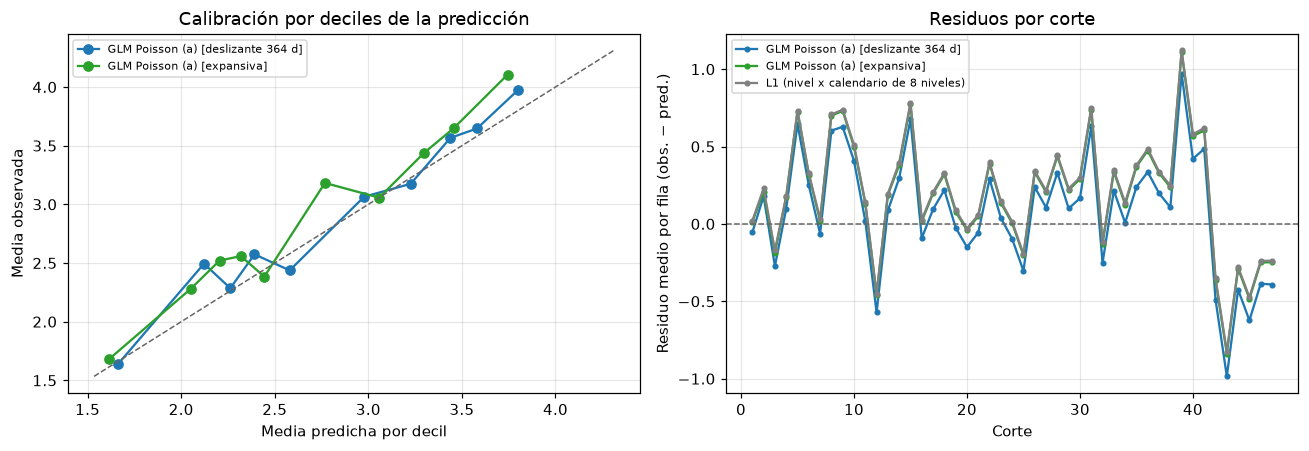

,modelo,decil,n,pred_min,pred_max,media_predicha,media_observada,observada_sobre_predicha
0,GLM Poisson (a) [deslizante 364 d],1,264,1.3675,1.9833,1.6632,1.6402,0.9862
1,GLM Poisson (a) [deslizante 364 d],2,263,1.9833,2.1989,2.1217,2.4943,1.1756
2,GLM Poisson (a) [deslizante 364 d],3,263,2.1992,2.3209,2.2624,2.2852,1.0101
3,GLM Poisson (a) [deslizante 364 d],4,263,2.3211,2.4719,2.3915,2.5741,1.0764
4,GLM Poisson (a) [deslizante 364 d],5,263,2.4723,2.7076,2.5794,2.4373,0.9449
5,GLM Poisson (a) [deslizante 364 d],6,263,2.7086,3.1014,2.9774,3.0646,1.0293
6,GLM Poisson (a) [deslizante 364 d],7,263,3.1026,3.3504,3.2261,3.1749,0.9841
7,GLM Poisson (a) [deslizante 364 d],8,263,3.3511,3.5134,3.4386,3.5665,1.0372
8,GLM Poisson (a) [deslizante 364 d],9,263,3.5134,3.6583,3.5806,3.6464,1.0184
9,GLM Poisson (a) [deslizante 364 d],10,264,3.6587,4.1215,3.8018,3.9773,1.0462


,modelo,pendiente_por_corte,ee_hac,ic95_inferior,ic95_superior,residuo_medio_cortes_1_a_23,residuo_medio_cortes_24_a_47,obs_sobre_pred_cortes_1_a_23,obs_sobre_pred_cortes_24_a_47
0,GLM Poisson (a) [deslizante 364 d],-0.0072,0.0063,-0.0195,0.0051,0.1412,0.0249,1.0513,1.0087
1,GLM Poisson (a) [expansiva],-0.0057,0.0063,-0.0181,0.0067,0.2330,0.1492,1.0876,1.0546
2,L1 (nivel x calendario de 8 niveles),-0.0057,0.0063,-0.0181,0.0067,0.2432,0.1598,1.0918,1.0587


In [33]:
# Calibración por deciles de la predicción (solución y sensibilidad)
filas = []
for nombre in (SOLUCION, REGLA):
    d = PRED_CAND[nombre].copy()
    d["decil"] = pd.qcut(d["pred"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
    for dec, g in d.groupby("decil"):
        filas.append({"modelo": nombre, "decil": dec, "n": len(g), "pred_min": g["pred"].min(), "pred_max": g["pred"].max(),
                      "media_predicha": g["pred"].mean(), "media_observada": g["n_siniestros"].mean(),
                      "observada_sobre_predicha": g["n_siniestros"].mean() / g["pred"].mean()})
deciles = pd.DataFrame(filas)
guardar_tabla(deciles.round(6), "42_fase3c_calibracion_deciles.csv")

# Residuos por corte y tendencia (MCO con EE HAC de Newey-West, 4 rezagos)
filas, tend = [], []
for nombre in (SOLUCION, REGLA, L1):
    df = P3[nombre]
    g = df.groupby("corte").agg(origen=("origen", "first"), observado=("n_siniestros", "sum"), predicho=("pred", "sum"))
    g["observado_sobre_predicho"] = g["observado"] / g["predicho"]
    g["residuo_medio"] = (g["observado"] - g["predicho"]) / 56
    filas.append(g.reset_index().assign(modelo=nombre))
    ols = sm.OLS(g["residuo_medio"].to_numpy(), sm.add_constant(g.index.to_numpy(dtype=float))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 4})
    tend.append({"modelo": nombre, "pendiente_por_corte": ols.params[1], "ee_hac": ols.bse[1],
                 "ic95_inferior": ols.conf_int()[1][0], "ic95_superior": ols.conf_int()[1][1],
                 "residuo_medio_cortes_1_a_23": g.loc[1:23, "residuo_medio"].mean(),
                 "residuo_medio_cortes_24_a_47": g.loc[24:47, "residuo_medio"].mean(),
                 "obs_sobre_pred_cortes_1_a_23": g.loc[1:23, "observado"].sum() / g.loc[1:23, "predicho"].sum(),
                 "obs_sobre_pred_cortes_24_a_47": g.loc[24:47, "observado"].sum() / g.loc[24:47, "predicho"].sum()})
residuos = pd.concat(filas, ignore_index=True)
residuos["origen"] = residuos["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(residuos[["modelo", "corte", "origen", "observado", "predicho", "observado_sobre_predicho", "residuo_medio"]].round(6),
              "43_fase3c_residuos_por_corte.csv")
tendencia = pd.DataFrame(tend)
guardar_tabla(tendencia.round(6), "44_fase3c_tendencia_residuos.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for nombre, color in ((SOLUCION, "C0"), (REGLA, "C2")):
    t = deciles[deciles["modelo"] == nombre]
    axes[0].plot(t["media_predicha"], t["media_observada"], "o-", color=color, label=nombre)
lim = [deciles[["media_predicha", "media_observada"]].min().min() * 0.95, deciles[["media_predicha", "media_observada"]].max().max() * 1.05]
axes[0].plot(lim, lim, color="0.4", ls="--", lw=1)
axes[0].set_xlabel("Media predicha por decil")
axes[0].set_ylabel("Media observada")
axes[0].set_title("Calibración por deciles de la predicción")
axes[0].legend(fontsize=7)
for nombre, color in ((SOLUCION, "C0"), (REGLA, "C2"), (L1, "0.5")):
    t = residuos[residuos["modelo"] == nombre]
    axes[1].plot(t["corte"], t["residuo_medio"], "o-", ms=3, color=color, label=nombre)
axes[1].axhline(0, color="0.4", ls="--", lw=1)
axes[1].set_xlabel("Corte")
axes[1].set_ylabel("Residuo medio por fila (obs. − pred.)")
axes[1].set_title("Residuos por corte")
axes[1].legend(fontsize=7)
fig.tight_layout()
guardar_figura(fig, "fig10_calibracion_y_residuos.png")
plt.show()
display(deciles.round(4))
tendencia.round(4)

  guardado: experiments\modelos_candidatos\registro_experimentos.csv (38 filas)
  guardado: experiments\modelos_candidatos\tablas\45_fase3c_nb2_364_alpha_por_corte.csv (47 filas)
NB2 364 d: cortes con plan B: 0 | α: {'count': 47.0, 'mean': 0.0323, 'std': 0.0059, 'min': 0.02, '25%': 0.0283, '50%': 0.0317, '75%': 0.0373, 'max': 0.0433}
diferencia máxima entre μ de NB2 364 d y de la solución: 0.00762
  guardado: experiments\modelos_candidatos\tablas\46_fase3c_cobertura_intervalos.csv (36 filas)


  guardado: experiments\modelos_candidatos\figuras\fig11_cobertura_intervalos.png


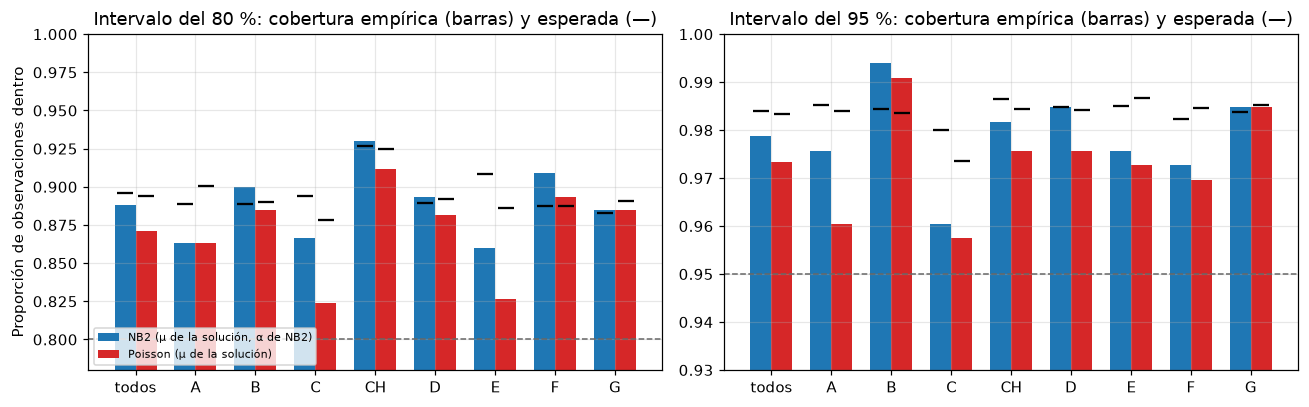

,intervalo,nivel_nominal,municipio,n,cobertura_empirica,cobertura_esperada_por_el_modelo,debajo,encima,ancho_medio
0,"NB2 (μ de la solución, α de NB2)",80,todos,2632,0.8883,0.8959,0.0312,0.0805,4.4153
9,"NB2 (μ de la solución, α de NB2)",95,todos,2632,0.9787,0.9840,0.0011,0.0201,6.6824
18,Poisson (μ de la solución),80,todos,2632,0.8712,0.8937,0.0426,0.0862,4.2143
27,Poisson (μ de la solución),95,todos,2632,0.9734,0.9833,0.0023,0.0243,6.3970


In [34]:
# NB2 (a) con ventana de 364 días: α por corte (D29 y plan B D28); se evalúa con el motor y entra al registro (no compite)
evaluar_configuracion("3c", SOLUCION_NB2, "NB2", "a", None, None, ventana=364)
registro = escribir_registro()
alpha_c = pd.DataFrame([a for a in AJUSTES if a["configuracion"] == SOLUCION_NB2])[
    ["origen", "dias_entrenamiento", "convergio", "iteraciones", "alpha_mv", "plan_b", "alpha_momentos", "n_avisos", "avisos"]]
alpha_c.insert(0, "corte", range(1, len(alpha_c) + 1))
alpha_c["alpha_usado"] = np.where(alpha_c["plan_b"], alpha_c["alpha_momentos"], alpha_c["alpha_mv"])
assert (alpha_c["dias_entrenamiento"] == 364).all() and len(alpha_c) == 47
alpha_c["origen"] = alpha_c["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(alpha_c.round(6), "45_fase3c_nb2_364_alpha_por_corte.csv")
print("NB2 364 d: cortes con plan B:", int(alpha_c["plan_b"].sum()), "| α:", alpha_c["alpha_usado"].describe().round(4).to_dict())
print("diferencia máxima entre μ de NB2 364 d y de la solución:",
      round(float(np.abs(PRED_CAND[SOLUCION_NB2]["pred"] - PRED_CAND[SOLUCION]["pred"]).max()), 6))

# Intervalos (D44): μ de la solución, α de NB2 del mismo corte; y Poisson con la misma μ
d = PRED_CAND[SOLUCION][["corte", "fecha", "zona_id", "n_siniestros", "pred"]].copy()
d["alpha"] = d["corte"].map(alpha_c.set_index("corte")["alpha_usado"])
r_nb = 1 / d["alpha"]
p_nb = r_nb / (r_nb + d["pred"])                                      # media r(1 − p)/p = μ; varianza μ + αμ²
DIST = {"NB2 (μ de la solución, α de NB2)": stats.nbinom(r_nb, p_nb), "Poisson (μ de la solución)": stats.poisson(d["pred"])}
NIVELES_INT = {80: (0.10, 0.90), 95: (0.025, 0.975)}
filas, y = [], d["n_siniestros"].to_numpy()
for tipo, dist in DIST.items():
    for nivel, (ql, qh) in NIVELES_INT.items():
        lo, hi = dist.ppf(ql), dist.ppf(qh)
        teor = dist.cdf(hi) - dist.cdf(lo - 1)                        # lo que el propio modelo espera dentro del intervalo
        dentro = (y >= lo) & (y <= hi)
        for z in ["todos"] + MUNICIPIOS:
            s = np.ones(len(d), bool) if z == "todos" else (d["zona_id"] == z).to_numpy()
            filas.append({"intervalo": tipo, "nivel_nominal": nivel, "municipio": z, "n": int(s.sum()),
                          "cobertura_empirica": dentro[s].mean(), "cobertura_esperada_por_el_modelo": teor[s].mean(),
                          "debajo": (y[s] < lo[s]).mean(), "encima": (y[s] > hi[s]).mean(), "ancho_medio": (hi - lo)[s].mean()})
cobertura = pd.DataFrame(filas)
guardar_tabla(cobertura.round(6), "46_fase3c_cobertura_intervalos.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))           # cada nivel con su eje: ninguna barra queda cortada
for ax, nivel in zip(axes, NIVELES_INT):
    for k, (tipo, color) in enumerate(zip(DIST, ("C0", "C3"))):
        t = cobertura[(cobertura["intervalo"] == tipo) & (cobertura["nivel_nominal"] == nivel)]
        x = np.arange(len(t)) + (k - 0.5) * 0.35
        ax.bar(x, t["cobertura_empirica"], width=0.35, color=color, label=tipo)
        ax.scatter(x, t["cobertura_esperada_por_el_modelo"], marker="_", s=120, color="k", zorder=3)
    ax.axhline(nivel / 100, color="0.4", ls="--", lw=1)
    ax.set_xticks(range(len(t)), [m.replace("MUNICIPIO ", "") for m in t["municipio"]])
    _t = cobertura[cobertura["nivel_nominal"] == nivel]
    ax.set_ylim(min(_t["cobertura_empirica"].min(), _t["cobertura_esperada_por_el_modelo"].min(), nivel / 100) - 0.02, 1.0)
    ax.set_title(f"Intervalo del {nivel} %: cobertura empírica (barras) y esperada (—)")
axes[0].set_ylabel("Proporción de observaciones dentro")
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
guardar_figura(fig, "fig11_cobertura_intervalos.png")
plt.show()
cobertura[cobertura["municipio"] == "todos"].round(4)

In [35]:
# Análisis pareado (D35): declarado como posterior a ver los resultados; no cambia la selección
pc_par = corte_c.pivot(index="corte", columns="modelo", values="desvianza_poisson")
PARES = [("solución", SOLUCION, "L1", L1), ("sensibilidad", REGLA, "L1", L1), ("contraste", CONTRASTE, "L1", L1),
         ("solución", SOLUCION, "sensibilidad", REGLA)]
filas = []
for ea, a, eb, b in PARES:
    dif = (pc_par[a] - pc_par[b]).to_numpy()
    ee = dif.std(ddof=1) / np.sqrt(len(dif))
    filas.append({"comparacion": f"{ea} − {eb}", "a": a, "b": b, "n_cortes": len(dif), "diferencia_media": dif.mean(),
                  "ee_de_la_diferencia": ee, "media_sobre_ee": dif.mean() / ee,
                  "cortes_gana_a": int((dif < 0).sum()), "empates": int((dif == 0).sum()), "cortes_gana_b": int((dif > 0).sum())})
pareado = pd.DataFrame(filas)
guardar_tabla(pareado.round(6), "47_fase3c_analisis_pareado.csv")
pareado.round(4)

  guardado: experiments\modelos_candidatos\tablas\47_fase3c_analisis_pareado.csv (4 filas)


,comparacion,a,b,n_cortes,diferencia_media,ee_de_la_diferencia,media_sobre_ee,cortes_gana_a,empates,cortes_gana_b
0,solución − L1,GLM Poisson (a) [deslizante 364 d],L1 (nivel x calendario de 8 niveles),47,-0.0114,0.0054,-2.0871,32,0,15
1,sensibilidad − L1,GLM Poisson (a) [expansiva],L1 (nivel x calendario de 8 niveles),47,-0.0017,0.0005,-3.4683,36,0,11
2,contraste − L1,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],L1 (nivel x calendario de 8 niveles),47,-0.0038,0.0074,-0.5222,26,0,21
3,solución − sensibilidad,GLM Poisson (a) [deslizante 364 d],GLM Poisson (a) [expansiva],47,-0.0097,0.0051,-1.8955,30,0,17


In [36]:
# Robustez (D43): exclusión de un municipio por vez, GLM Poisson (a), ventana de 364 días. Descriptivo; no cambia la selección.
filas, n_avisos, no_conv = [], 0, 0
for corte, origen in enumerate(ORIGENES, start=1):
    fin = origen + pd.Timedelta(days=HORIZONTE)
    vista = panel[panel["fecha"] < fin].copy()
    vista.loc[vista["fecha"] >= origen, "n_siniestros"] = np.nan
    ent, hor = matrices(vista, origen, 364)
    niveles = var.nivel_municipio(vista, origen, 364)
    for z, cz in zip(MUNICIPIOS, MUN_COLS):
        otras = [c for c in MUN_COLS if c != cz]
        e7 = ent[ent["zona_id"] != z]
        res, av = con_avisos(lambda: sm.GLM(e7["n_siniestros"], e7[otras + CAL_COLS], family=sm.families.Poisson()).fit())
        n_avisos += len(av)
        no_conv += int(not res.converged)
        beta_bar, gam = res.params[otras].mean(), res.params[CAL_COLS]
        em, hm = ent[ent["zona_id"] == z], hor[hor["zona_id"] == z]
        assert np.isclose(niveles[z], em["n_siniestros"].mean())          # el nivel propio es su media en la ventana
        c_m = niveles[z] / np.exp(beta_bar + em[CAL_COLS].to_numpy() @ gam.to_numpy()).mean()
        filas.append(hm[["fecha", "zona_id"]].assign(
            corte=corte, c_m=c_m, pred_excluido=np.exp(beta_bar + hm[CAL_COLS].to_numpy() @ gam.to_numpy()) * c_m))
lomo = pd.concat(filas, ignore_index=True).merge(
    PRED_CAND[SOLUCION][["corte", "fecha", "zona_id", "n_siniestros", "pred"]], on=["corte", "fecha", "zona_id"],
    how="left", validate="one_to_one")
assert len(lomo) == 2632 and lomo["pred"].notna().all()
print(f"376 ajustes de exclusión: {no_conv} no convergidos, {n_avisos} avisos")

filas = []
for z in ["todos"] + MUNICIPIOS:
    g = lomo if z == "todos" else lomo[lomo["zona_id"] == z]
    m_con, m_sin = evaluar(g["n_siniestros"], g["pred"]), evaluar(g["n_siniestros"], g["pred_excluido"])
    dc = g.groupby("corte").apply(lambda h: evaluar(h["n_siniestros"], h["pred_excluido"])["desvianza_poisson"]
                                  - evaluar(h["n_siniestros"], h["pred"])["desvianza_poisson"], include_groups=False)
    filas.append({"municipio": z, "desvianza_modelo_que_lo_vio": m_con["desvianza_poisson"],
                  "desvianza_excluido": m_sin["desvianza_poisson"],
                  "empeora": m_sin["desvianza_poisson"] - m_con["desvianza_poisson"],
                  "empeora_relativo": m_sin["desvianza_poisson"] / m_con["desvianza_poisson"] - 1,
                  "ee_de_la_diferencia_por_corte": dc.std(ddof=1) / np.sqrt(len(dc)),
                  "cortes_en_que_empeora": int((dc > 0).sum()),
                  "total_pred_obs_modelo_que_lo_vio": m_con["razon_total"], "total_pred_obs_excluido": m_sin["razon_total"],
                  "max_dif_relativa_predicciones": float((np.abs(g["pred_excluido"] - g["pred"]) / g["pred"]).max())})
exclusion = pd.DataFrame(filas)
guardar_tabla(exclusion.round(6), "48_fase3c_exclusion_municipio.csv")
exclusion.round(4)

376 ajustes de exclusión: 0 no convergidos, 0 avisos


  guardado: experiments\modelos_candidatos\tablas\48_fase3c_exclusion_municipio.csv (9 filas)


,municipio,desvianza_modelo_que_lo_vio,desvianza_excluido,empeora,empeora_relativo,ee_de_la_diferencia_por_corte,cortes_en_que_empeora,total_pred_obs_modelo_que_lo_vio,total_pred_obs_excluido,max_dif_relativa_predicciones
0,todos,1.2205,1.2256,0.0051,0.0042,0.0010,35,0.9717,0.9716,0.0693
1,MUNICIPIO A,1.2586,1.2839,0.0252,0.0200,0.0058,35,0.9330,0.9331,0.0693
2,MUNICIPIO B,1.0842,1.0873,0.0031,0.0028,0.0025,27,1.0222,1.0222,0.0271
3,MUNICIPIO C,1.3508,1.3580,0.0072,0.0054,0.0038,28,0.9375,0.9372,0.0444
4,MUNICIPIO CH,1.3406,1.3407,0.0001,0.0001,0.0024,22,1.0218,1.0220,0.0372
5,MUNICIPIO D,1.1019,1.1057,0.0037,0.0034,0.0024,29,0.9854,0.9851,0.0487
6,MUNICIPIO E,1.4068,1.4076,0.0008,0.0006,0.0018,26,0.9441,0.9439,0.0318
7,MUNICIPIO F,1.0541,1.0560,0.0019,0.0018,0.0025,25,0.9611,0.9616,0.0442
8,MUNICIPIO G,1.1670,1.1657,-0.0013,-0.0011,0.0014,20,0.9894,0.9894,0.0213


### 12.1 Lectura del paso 3c

Cifras de `tablas/38` a `48`. Validación; el bloque final no se leyó. Nada de esta sección cambia la selección (D42, D43).

**Evidencia — errores**

- **Por municipio** (`38`): la solución tiene su peor desvianza en E (1,4068) y la mejor en F (1,0541). Su total predicho / observado va de
  0,9330 (A) a 1,0222 (B); el de la sensibilidad, de 0,8695 (A) a 1,0049 (CH). Subestima sobre todo A y C (residuo medio +0,2239 y +0,2314
  siniestros por día).
- **Por tipo de día** (`39`): la mayor desvianza de la solución es la del domingo (1,4006), y la menor, la del jueves (1,0689). Sobreestima
  solo los sábados (total pred./obs. 1,0229); el resto de los niveles va de 0,9301 (domingo) a 0,9860 (lunes).
- **Las 5 semanas de mayor desvianza** (`40`, días en `41`): cortes 43 (2025-01-02 → 01-08; 1,8183), 47 (2025-01-30 → 02-05; 1,5889), 5
  (2024-04-11 → 04-17; 1,5873), 20 (2024-07-25 → 07-31; 1,5198) y 22 (2024-08-08 → 08-14; 1,5029). Las cinco están también entre las
  7 peores de L1, y el corte 43 es la peor de L1. En el corte 43 se observaron 100 siniestros contra 155,15 predichos (1,5515); incluye un
  día que el ETL marca como feriado (2025-01-06, lunes). En el corte 5 pasa lo contrario: 192 observados contra 155,85 (0,8117), y los días
  2024-04-16 y 04-17 registran 37 cada uno. Ninguna de las otras cuatro semanas tiene feriados. **Los datos no muestran por qué** esas
  semanas se apartan: no se atribuyen causas.

**Evidencia — calibración y deriva**

- **Deciles** (`42`): en la solución, la razón observado / predicho va de 0,9449 (decil 5) a 1,1756 (decil 2); en la sensibilidad, de 0,9754
  a 1,1498, con 8 de 10 deciles por encima de 1,04.
- **Residuos en el tiempo** (`43`, `44`): pendiente del residuo medio por corte −0,0072 (EE HAC 0,0063; IC95 −0,0195 a 0,0051), compatible con
  0. La razón observado / predicho de la solución es 1,0513 en los cortes 1 a 23 y 1,0087 en los 24 a 47; la de la sensibilidad, 1,0876 y 1,0546.

**Evidencia — intervalos** (`45`, `46`)

- **α de NB2 (a) 364 d:** de 0,0200 a 0,0433 (mediana 0,0317); 47 de 47 cortes convergieron según D29 y **ninguno usó el plan B**. Su μ
  difiere de la de la solución en como mucho 0,0076, y su desvianza es 1,2205 (registro, paso «3c»).
- **Cobertura global**, empírica contra la que espera el modelo: NB2 80 % **0,8883** (0,8959) y 95 % **0,9787** (0,9840); Poisson 80 %
  **0,8712** (0,8937) y 95 % **0,9734** (0,9833). Por ser conteos chicos, los intervalos cubren más que el nominal en los dos modelos.
  La cobertura empírica queda por debajo de la esperada, menos en NB2 que en Poisson.
- **Asimetría:** con NB2 al 80 %, el 8,05 % de las observaciones queda por encima del intervalo y el 3,12 % por debajo.
- **Por municipio**, NB2 al 80 %: de 0,8602 (E, esperada 0,9082) a 0,9301 (CH). Con Poisson, C y E bajan a 0,8237 y 0,8267.

**Evidencia — análisis pareado (D35, posterior a ver los resultados)** (`47`)

| Comparación | Diferencia media | EE de la diferencia | Cortes ganados / perdidos |
| --- | --- | --- | --- |
| solución − L1 | −0,0114 | 0,0054 | 32 / 15 |
| sensibilidad − L1 | −0,0017 | 0,0005 | 36 / 11 |
| contraste − L1 | −0,0038 | 0,0074 | 26 / 21 |
| solución − sensibilidad | −0,0097 | 0,0051 | 30 / 17 |

**Evidencia — exclusión de un municipio por vez (D43, descriptivo)** (`48`)

Excluir cada municipio del entrenamiento empeora la desvianza global de 1,2205 a 1,2256 (+0,0051, +0,42 %). El que más empeora es **A**
(+0,0252, +2,0 %, en 35 de 47 cortes); el resto, entre −0,0013 (G, que mejora levemente) y +0,0072 (C). El total pred./obs. no cambia más
de 0,0005 en ningún municipio.

**Inferencia**

- Lo que queda sin explicar se concentra en semanas puntuales que también son difíciles para L1. Sin deriva sostenida detectable en la
  validación, la ventana de 364 días parece seguir el nivel. La subestimación residual se redujo en la segunda mitad.
- El EE pareado es mucho menor que el de 1 EE entre cortes de la regla (0,0054 contra ≈ 0,036). Visto corte a corte, la solución mejora a L1 de
  forma más consistente de lo que el criterio de la regla dejaba ver. Pero este análisis es posterior, los cortes vecinos no son
  independientes y no se fijó antes ningún umbral: **no es una prueba de significación y no cambia la selección**.
- Los intervalos NB2 cubren algo mejor que los Poisson y, por las colas, siguen la subestimación. Que la cobertura empírica quede por
  debajo de la esperada sugiere que la dispersión de algunas semanas es mayor que la que α captura.
- Que A sea el que más pierde al excluirlo es coherente con su patrón de calendario propio (§7, término de A). Con 8 municipios parecidos,
  el resto se predice casi igual sin verlo. Con 8 zonas, esta prueba tiene poco poder para hablar de generalización a zonas nuevas.

## 13. Estado y artefactos

- **Fase 1** (secciones 1 a 6): protocolo y referencias.
- **Fase 2, paso A** (sección 7): conjuntos de variables con GLM Poisson y XGBoost, ventana expansiva.
- **Fase 2, paso B** (sección 8): grilla de XGBoost y binomial negativa NB2 sobre el conjunto elegido en el paso A.
- **Fase 2, paso C** (sección 9): ventanas expansiva y deslizantes para la configuración elegida de cada familia.
  La regla eligió la ventana expansiva.
- **Fase 3, paso 3a** (sección 10): configuración final fijada por el equipo (D42, apartándose de la regla): GLM Poisson (a)
  con ventana deslizante de 364 días. Escrita en `experiments/modelos_candidatos/solucion_seleccionada.json`.
- **Fase 3, paso 3b** (sección 11): coeficientes, importancia por permutación y dependencia parcial (validación).
- **Fase 3, paso 3c** (sección 12): errores, calibración, intervalos NB2 y Poisson, análisis pareado y exclusión de un
  municipio por vez (validación). Elecciones de análisis D43 a D45; no cambian la selección.

El registro de experimentos está en `experiments/modelos_candidatos/registro_experimentos.csv`.

In [37]:
indice = pd.DataFrame(sorted([(f"tablas/{p.name}") for p in DIR_TABLAS.glob("*.csv") if p.name != "10_artefactos.csv"]
                             + [(f"figuras/{p.name}") for p in DIR_FIGURAS.glob("*.png")]
                             + [p.name for p in (RUTA_REGISTRO, RUTA_SOLUCION) if p.exists()]), columns=["artefacto"])
guardar_tabla(indice, "10_artefactos.csv")
indice

  guardado: experiments\modelos_candidatos\tablas\10_artefactos.csv (61 filas)


,artefacto
0,figuras/fig10_calibracion_y_residuos.png
1,figuras/fig11_cobertura_intervalos.png
2,figuras/fig1_referencias_por_corte.png
3,figuras/fig2_referencias_por_municipio.png
4,figuras/fig3_total_semanal_referencias.png
...,...
56,tablas/44_fase3c_tendencia_residuos.csv
57,tablas/45_fase3c_nb2_364_alpha_por_corte.csv
58,tablas/46_fase3c_cobertura_intervalos.csv
59,tablas/47_fase3c_analisis_pareado.csv
